<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 2 DO PROJETO</b></CENTER><br/>

NOME COMPLETO: Lucas Barbosa Simão

LINK PARA SEU PRÓPRIO COLAB: [Aqui](https://colab.research.google.com/drive/10AEoNUk_nz2T3QFCd0gGeYs_agi26Mew#scrollTo=x4M2bx57qwI7)

**LINK PARA SEU GITHUB DO PROJETO COMPLETO - OBRIGATÓRIO (0.5 ponto)**: [Aqui](https://github.com/lucasbarsim-lang/UWine)

**LINK PARA SEU PRÓPRIO VÍDEO NO YOUTUBE - OBRIGATÓRIO (0.5 ponto):** [Aqui](https://youtu.be/TL-V4ksO1-E)

# **Cenário Fictício**:

Prezados(as) alunos(as),

É ótimo que você como **Consultor** ( ***Data Science Consultant*** ) do **Projeto Data Science** tenha chegado no **Workflow - Parte 2: Aprendizado de Máquina** (*Machine Learnning*). A *Incrível Biblioteca*:

<center>

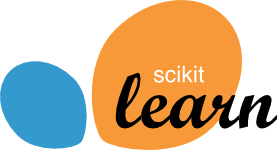

<center>

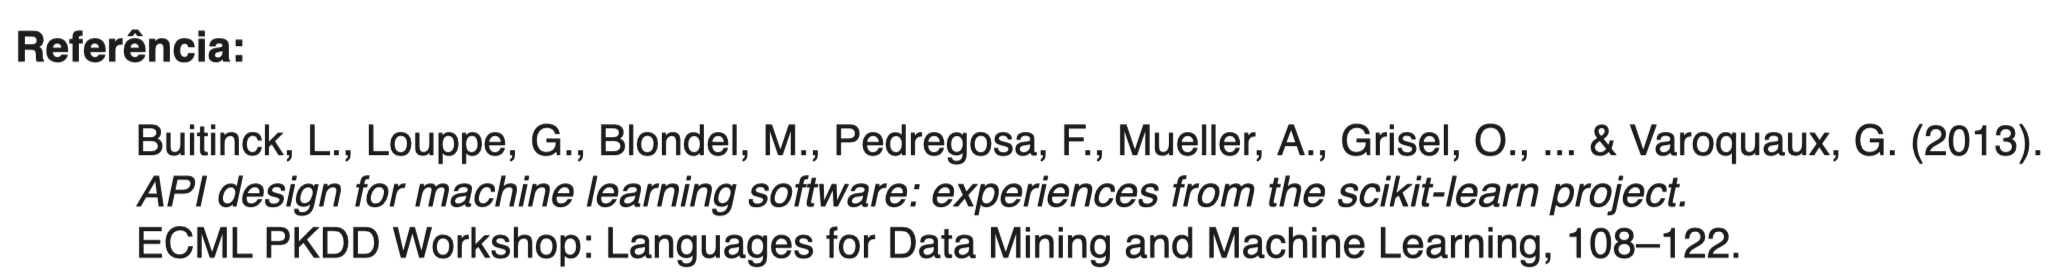

Neste etapa, você irá usar conjuntos (vários) que virão do **Workflow - Parte1**, a saber:

*   Conjunto de Treinamento: ***train***
*   Conjunto de Validação: ***validation***
*   Conjunto de Teste: ***test***

<center>

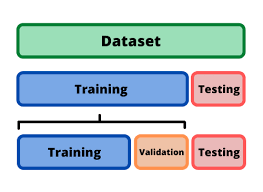

Ou seja:

<center>

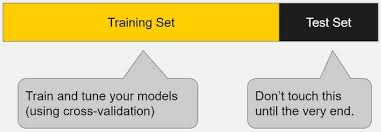


Com todas as Análises e *Insights* (**Estatistica Descritiva,** **Testes de Hipóteses** e os **Métodos Quantitativos**) que irão garatir que temos conjuntos com Qualidade (***Best Quality Analytics***) e que são ótimas amostras em relação a população ratificando justamente a importância da Parte 1 do projeto.

<center>

**EXCELENTE!!! Agora podemos ir mais longe no Universo Python!** 🚀🚀🚀

</center>

Podemos praticar as técnicas mais avançadas do **Aprendizado de Máquina** (*Machine Learnning*) e criarmos aprendizes dos seguintes modelos, a saber:

*   REGRESSOR: Modelo de Regressão: [Regression](https://scikit-learn.org/stable/supervised_learning.html)
*   CLUSTERIZADOR: Modelo de Agrupamento: [Clustering](https://scikit-learn.org/stable/modules/clustering.html)
*   CLASSIFICADOR: Modelo de Classificação:  [Classification](https://scikit-learn.org/stable/supervised_learning.html)

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do projeto, adotaremos um **Fluxo de Projeto (Ciclo de Vida)** composto pela atividades estabelecidas no **Workflow - Parte 2**, conforme a seguir:

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

In [ ]:
# ==============================================================================
# CÉLULA 1: IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÕES GLOBAIS
# ==============================================================================

# 1. Manipulação de Dados e Computação Científica
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# 2. Estatística e Validação Amostral (Parte 1 -> Parte 2)
from scipy import stats
from scipy.stats import mannwhitneyu

# 3. Visualização de Dados
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração padrão de estilo dos gráficos
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# 4. Pré-processamento, Pipelines e Divisão de Dados
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 5. Modelos de Regressão
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 6. Modelos de Clusterização (Aprendizagem Não Supervisionada)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 7. Modelos de Classificação
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# 8. Métricas de Avaliação
from sklearn.metrics import (
    # Regressão
    r2_score, mean_squared_error, mean_absolute_error,
    # Clusterização
    silhouette_score, davies_bouldin_score,
    # Classificação
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
)

# 9. Semente de Reprodutibilidade
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## Load dos Datasets:

In [ ]:
# ==============================================================
#| Load dos Datasets: TAMANHO IDEAL (n = 50.300)
# ==============================================================
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42                      # reprodutibilidade
ESTRATO = "TIPO DA CONTA"      # variável de estratificação

# --------------------------------------------------------------
# 1. Base completa (mesma tabela da Parte 1)
# --------------------------------------------------------------
table39 = pd.read_csv("table39.csv", index_col=0)

# --------------------------------------------------------------
# 2. Alocação de Neyman obtida na Parte 1 (n = 50.300)
#    Fonte: optimal_stratified_sample_size -> coluna "Allocated Sample (nh)"
# --------------------------------------------------------------
alocacao_neyman = {
    "ESSENTIAL": 20073,
    "PRIME": 18900,
    "VIP": 11327,
}
N_IDEAL = sum(alocacao_neyman.values())
assert N_IDEAL == 50300, "A soma da alocação deve ser 50.300."

# --------------------------------------------------------------
# 3. Amostra do TAMANHO IDEAL (estratificada, sem reposição)
# --------------------------------------------------------------
amostra_ideal = pd.concat([
    table39[table39[ESTRATO] == estrato].sample(n=nh, random_state=SEED)
    for estrato, nh in alocacao_neyman.items()
])

# --------------------------------------------------------------
# 4. Divisão 70% / 15% / 15% (estratificada por TIPO DA CONTA)
# --------------------------------------------------------------
train, temp = train_test_split(
    amostra_ideal,
    test_size=0.30,
    stratify=amostra_ideal[ESTRATO],
    random_state=SEED,
)

validation, test = train_test_split(
    temp,
    test_size=0.50,
    stratify=temp[ESTRATO],
    random_state=SEED,
)

# --------------------------------------------------------------
# 5. Verificações de integridade
# --------------------------------------------------------------
assert len(train) + len(validation) + len(test) == N_IDEAL
assert not (set(train.index) & set(validation.index)), "Vazamento: train x validation"
assert not (set(train.index) & set(test.index)), "Vazamento: train x test"
assert not (set(validation.index) & set(test.index)), "Vazamento: validation x test"

# --------------------------------------------------------------
# 6. Salvar os conjuntos (reuso nas próximas etapas)
# --------------------------------------------------------------
train.to_csv("train.csv")
validation.to_csv("validation.csv")
test.to_csv("test.csv")

# --------------------------------------------------------------
# 7. Relatório
# --------------------------------------------------------------
resumo = pd.DataFrame({
    "train": train[ESTRATO].value_counts(),
    "validation": validation[ESTRATO].value_counts(),
    "test": test[ESTRATO].value_counts(),
})
resumo.loc["TOTAL"] = resumo.sum()
resumo["TOTAL"] = resumo.sum(axis=1)

print(f"Amostra ideal: {N_IDEAL:,} registros".replace(",", "."))
print(f"train: {len(train):,} | validation: {len(validation):,} | test: {len(test):,}".replace(",", "."))
display(resumo)

Amostra ideal: 50.300 registros
train: 35.210 | validation: 7.545 | test: 7.545


,train,validation,test,TOTAL
TIPO DA CONTA,,,,
ESSENTIAL,14051,3011,3011,20073
PRIME,13230,2835,2835,18900
VIP,7929,1699,1699,11327
TOTAL,35210,7545,7545,50300


*Load* dos dataset aqui, a saber:

*   Conjunto de Treinamento do **TAMANHO IDEAL**: ***train***
*   Conjunto de Validação do **TAMANHO IDEAL**: ***validation***
*   Conjunto de Teste do **TAMANHO IDEAL**: ***test***

Qual o "TAMANHO IDEAL" do conjunto:

*   Conjunto de Treinamento: ???
*   Conjunto de Validação: ???
*   Conjunto de Teste: ???

In [ ]:
n_total = len(train) + len(validation) + len(test)

print(f"Conjunto de Treinamento: {len(train):,} ({len(train)/n_total:.0%})".replace(",", "."))
print(f"Conjunto de Validação:   {len(validation):,} ({len(validation)/n_total:.0%})".replace(",", "."))
print(f"Conjunto de Teste:       {len(test):,} ({len(test)/n_total:.0%})".replace(",", "."))
print(f"Total:                   {n_total:,}".replace(",", "."))

Conjunto de Treinamento: 35.210 (70%)
Conjunto de Validação:   7.545 (15%)
Conjunto de Teste:       7.545 (15%)
Total:                   50.300


**Amostra e alocação de Neyman.** Analisar 1,12 milhão de registros em todos os modelos seria lento e desnecessário, então trabalhamos com uma amostra de **50.300 notas**. Como a base tem três tipos de conta com comportamentos de compra muito diferentes, a amostra foi **estratificada por tipo de conta**, isto é, cada tipo foi sorteado separadamente. A quantidade de clientes sorteada em cada tipo seguiu a **alocação de Neyman**, método que dá mais peso aos grupos que são maiores **e** mais variáveis no valor da nota (TOTAL). Na prática, cada tipo recebe uma fatia proporcional ao seu tamanho na base multiplicado pelo desvio-padrão do valor das notas:

`clientes sorteados no tipo = tamanho da amostra × (tamanho do tipo na base × desvio-padrão do tipo) ÷ soma desse produto nos três tipos`

| Tipo de conta | Clientes na base | % da base | Desvio-padrão do valor da nota (reais) | Tamanho × desvio | % da amostra | Clientes sorteados | Fração sorteada do tipo |
|---|---|---|---|---|---|---|---|
| ESSENTIAL | 683.224 | 61,0% | 300,07 | 183,05 | 39,9% | 20.073 | 2,9% |
| VIP | 253.308 | 22,6% | 456,73 | 103,30 | 22,5% | 11.327 | 4,5% |
| PRIME | 183.469 | 16,4% | 1.052,14 | 172,35 | 37,6% | 18.900 | 10,3% |
| **Total** | **1.120.000** | **100%** | – | **458,70** | **100%** | **50.300** | **4,5%** |

O resultado tem uma lógica simples. O PRIME é o menor grupo da base (16,4%), mas as notas dele variam muito mais (desvio-padrão de cerca de 1.052 reais, contra cerca de 300 reais no ESSENTIAL). Por isso ele recebe uma amostra proporcionalmente maior: 10,3% dos clientes PRIME entram na amostra, contra 2,9% dos ESSENTIAL. Esse é o jeito de estimar o valor médio das notas com a maior precisão possível para um mesmo tamanho de amostra.

O tamanho total de 50.300 vem da análise de estabilização do erro-padrão feita na Parte 1: com a alocação estratificada, o erro-padrão da média do valor da nota é de cerca de **2,05 reais**. Para comparação, uma amostra aleatória simples de 141.400 notas (valor que resultou da análise do PRIME isolado) teria erro-padrão de cerca de 2,22 reais, e uma amostra aleatória simples do mesmo tamanho, 50.300, teria 3,73 reais. Ou seja, a amostra estratificada é mais precisa do que uma amostra bem maior sorteada sem estratos.

**Consequência para a leitura dos resultados.** A alocação de Neyman não reproduz as proporções reais da base: os clientes PRIME passam de 16,4% da base para 37,6% da amostra, e os ESSENTIAL caem de 61,0% para 39,9%. Isso é intencional e ajuda a estimar bem o valor das notas, mas faz com que medidas como o erro da regressão, o tamanho dos grupos da clusterização e a acurácia da classificação, calculadas na amostra, sejam diferentes das que a empresa teria na prática. Por isso, cada modelo foi testado também em uma amostra aleatória simples da base completa, que mantém as proporções reais.

# Workflow: Detalhamento das Atividades

#Atividade A1: Modelo de Regressão

##Atividade A1.1 (1º Passo): Normalizar - Mapear - Discretizar

In [ ]:
# ==============================================================
#| Atividade A1.1 (1º Passo): Normalizar - Mapear - Discretizar
# Requer: train, validation, test (célula "Load dos Datasets")
# Alvo: TOTAL (R$) (mantido na escala original, em R$)
# ==============================================================
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

ALVO = "TOTAL (R$)"
IDENTIFICADOR = "NOTA FISCAL"

# --------------------------------------------------------------
# 1. DISCRETIZAR: OPINIÃO DO CLIENTE (texto) -> NÍVEL DE SATISFAÇÃO (1 a 5)
#    1 = Muito insatisfeito | 2 = Insatisfeito | 3 = Indiferente
#    4 = Satisfeito         | 5 = Muito Satisfeito
#    Mapa explícito das 25 opiniões únicas (mesma lógica da Parte 1, A3.1)
# --------------------------------------------------------------
MAPA_OPINIAO = {
    # 5 - Muito Satisfeito
    "Produto perfeito, chegou antes do prazo de previsão. Top demais a UVVine": 5,
    "Excelente experiência, recomendo muito a UVVine": 5,
    "Superou expectativas o atendimento na UVVine": 5,
    "Ótimo! Tudo ocorreu maravilhosamente bem com a UVVine": 5,
    "Serviço impecável, adorei o clube: UVVine": 5,
    # 4 - Satisfeito
    "Serviço eficiente, recomendo o clube: UVVine": 4,
    "Gostei do atendimento prestado pela UVVine": 4,
    "Funcionou bem e me atendeu no prazo certo a UVVine": 4,
    "Entrega foi boa e rápida na UVVine": 4,
    "Fiquei satisfeito com o serviço da UVVine": 4,
    # 3 - Indiferente
    "Nada digno de nota com a UVVine": 3,
    "Compro exponenciamente, opinião neutra sobre UVVine": 3,
    "Sem opinião formada sobre a UVVine": 3,
    "Não tenho muito a dizer sobre a UVVine": 3,
    "Foi indiferente minha experiência com a UVVine": 3,
    # 2 - Insatisfeito
    "Foi aceitável, esperava mais da UVVine": 2,
    "Razoável, com margem de melhora no preço médio da UVVine": 2,
    "Experiência regular, não atendeu a política de cashback da UVVine": 2,
    "Serviço deixou a desejar na UVVine": 2,
    "Atendimento comum, poderia melhorar em cordialidade a UVVine": 2,
    "Nada demais, serviço regular na UVVine": 2,
    # 1 - Muito insatisfeito
    "Senti que faltou qualidade no atendimento da UVVine": 1,
    "Tive uma experiência ruim com a UVVine": 1,
    "Não gostei do atendimento na UVVine": 1,
    "Produto chegou atrasado na UVVine": 1,
}

def _limpar(texto):
    """Remove espaços duplicados (ex.: 'clube:  UVVine')."""
    return " ".join(str(texto).split())

MAPA_OPINIAO_LIMPO = {_limpar(k): v for k, v in MAPA_OPINIAO.items()}

def discretizar_opiniao(serie):
    """Converte o texto da opinião em nível de satisfação (1 a 5)."""
    nivel = serie.map(lambda t: MAPA_OPINIAO_LIMPO.get(_limpar(t)))
    if nivel.isna().any():
        raise ValueError("Opiniões sem mapeamento: "
                         f"{serie[nivel.isna()].unique().tolist()}")
    return nivel.astype(int)

# Conferência com a Parte 1 (base completa): 5=3,00 | 4=77,81 | 3=15,81 | 2=2,59 | 1=0,80
if "table39" in globals():
    conferencia = (discretizar_opiniao(table39["OPINIÃO DO CLIENTE"])
                   .value_counts(normalize=True).mul(100).round(2).sort_index(ascending=False))
    print("Distribuição dos níveis na base completa (%):")
    print(conferencia.to_string())

# --------------------------------------------------------------
# 2. MAPEAR: variáveis categóricas -> números
# --------------------------------------------------------------
MAPA_SEXO = {"MASCULINO": 0, "FEMININO": 1}
MAPA_CONTA = {"ESSENTIAL": 0, "VIP": 1, "PRIME": 2}   # ordem crescente de perfil/gasto
COLS_DUMMY = ["REGIÃO", "ESTADO CIVIL"]               # nominais -> one-hot (drop_first)

# Categorias definidas SOMENTE pelo treino (mesmas colunas nos 3 conjuntos)
CATEGORIAS = {c: sorted(train[c].unique()) for c in COLS_DUMMY}

print("\nMédia de TOTAL (R$) por TIPO DA CONTA no treino (justifica a ordem 0<1<2):")
print(train.groupby("TIPO DA CONTA")[ALVO].mean().round(2).sort_values().to_string())

# --------------------------------------------------------------
# 3. NORMALIZAR: z-score nas variáveis numéricas (ajustado SOMENTE no treino)
# --------------------------------------------------------------
COLS_NORMALIZAR = [c for c in train.select_dtypes(include="number").columns
                   if c not in (ALVO, IDENTIFICADOR)]
scaler = StandardScaler().fit(train[COLS_NORMALIZAR])   # use MinMaxScaler() para [0, 1]

# --------------------------------------------------------------
# 4. Pipeline completo, aplicado igual aos três conjuntos
# --------------------------------------------------------------
def preparar(df):
    # Normalizar
    num = pd.DataFrame(scaler.transform(df[COLS_NORMALIZAR]),
                       columns=COLS_NORMALIZAR, index=df.index)
    # Mapear
    mapeadas = pd.DataFrame(index=df.index)
    mapeadas["SEXO_FEMININO"] = df["SEXO"].map(MAPA_SEXO)
    mapeadas["TIPO_CONTA_ORD"] = df["TIPO DA CONTA"].map(MAPA_CONTA)
    dummies = [
        pd.get_dummies(
            pd.Series(pd.Categorical(df[c], categories=CATEGORIAS[c]), index=df.index),
            prefix=c.replace(" ", "_"), drop_first=True, dtype=int)
        for c in COLS_DUMMY
    ]
    # Discretizar
    disc = pd.DataFrame({"NIVEL_SATISFACAO": discretizar_opiniao(df["OPINIÃO DO CLIENTE"])},
                        index=df.index)
    X = pd.concat([num, mapeadas, *dummies, disc], axis=1)
    if X.isna().any().any():
        raise ValueError("Há valores ausentes após a preparação.")
    return X, df[ALVO]

X_train, y_train = preparar(train)
X_val, y_val = preparar(validation)
X_test, y_test = preparar(test)

# --------------------------------------------------------------
# 5. Relatório
# --------------------------------------------------------------
print(f"\nX_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")
print(f"\nVariáveis do modelo ({X_train.shape[1]}):")
print(list(X_train.columns))
print("\nConferência da normalização (média ~0 e desvio ~1 apenas no treino):")
display(pd.DataFrame({
    "média treino": X_train[COLS_NORMALIZAR].mean(),
    "desvio treino": X_train[COLS_NORMALIZAR].std(),
    "média validação": X_val[COLS_NORMALIZAR].mean(),
}).round(3))
display(X_train.head())

Distribuição dos níveis na base completa (%):
OPINIÃO DO CLIENTE
5     3.0
4    77.0
3    15.0
2     4.2
1     0.8

Média de TOTAL (R$) por TIPO DA CONTA no treino (justifica a ordem 0<1<2):
TIPO DA CONTA
ESSENTIAL     402.76
VIP           910.58
PRIME        2192.90

X_train: (35210, 25) | X_val: (7545, 25) | X_test: (7545, 25)

Variáveis do modelo (25):
['DEPENDENTES', 'RENDA BRUTO (R$)', 'NOTA DE SATISFAÇÃO (%)', 'MEAN: alcohol', 'MEAN: malic_acid', 'MEAN: ash', 'MEAN: alcalinity_of_ash', 'MEAN: magnesium', 'MEAN: total_phenols', 'MEAN: flavanoids', 'MEAN: nonflavanoid_phenols', 'MEAN: proanthocyanins', 'MEAN: color_intensity', 'MEAN: hue', 'MEAN: od280/od315_of_diluted_wines', 'MEAN: proline', 'SEXO_FEMININO', 'TIPO_CONTA_ORD', 'REGIÃO_NORDESTE', 'REGIÃO_NORTE', 'REGIÃO_SUDESTE', 'REGIÃO_SUL', 'ESTADO_CIVIL_DESQUITADO(A) / VIÚVO(A)', 'ESTADO_CIVIL_SOLTEIRO', 'NIVEL_SATISFACAO']

Conferência da normalização (média ~0 e desvio ~1 apenas no treino):


,média treino,desvio treino,média validação
DEPENDENTES,-0.0,1.0,-0.013
RENDA BRUTO (R$),-0.0,1.0,0.001
NOTA DE SATISFAÇÃO (%),-0.0,1.0,-0.002
MEAN: alcohol,0.0,1.0,0.004
MEAN: malic_acid,0.0,1.0,0.020
MEAN: ash,-0.0,1.0,-0.011
MEAN: alcalinity_of_ash,0.0,1.0,-0.000
MEAN: magnesium,0.0,1.0,-0.010
MEAN: total_phenols,0.0,1.0,0.019
MEAN: flavanoids,0.0,1.0,0.006


,DEPENDENTES,RENDA BRUTO (R$),NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,MEAN: ash,MEAN: alcalinity_of_ash,MEAN: magnesium,MEAN: total_phenols,MEAN: flavanoids,...,MEAN: proline,SEXO_FEMININO,TIPO_CONTA_ORD,REGIÃO_NORDESTE,REGIÃO_NORTE,REGIÃO_SUDESTE,REGIÃO_SUL,ESTADO_CIVIL_DESQUITADO(A) / VIÚVO(A),ESTADO_CIVIL_SOLTEIRO,NIVEL_SATISFACAO
105333,-1.109577,-0.934841,-0.348082,-1.404460,-1.987826,-1.164621,1.424430,-1.272790,-0.529874,-0.470134,...,-3.638641,1,0,1,0,0,0,0,1,4
646093,1.996415,-0.928708,-0.348082,-1.095400,0.155857,-1.457403,0.938632,1.184180,0.953219,0.249136,...,-0.552967,0,0,0,0,1,0,0,0,4
316800,-1.109577,1.241644,0.946746,0.292458,-1.193767,-0.172909,-1.416874,-0.773243,-0.178239,0.235996,...,0.757650,0,2,0,0,1,0,0,1,1
934947,-0.074246,-0.327675,-0.348082,0.509214,-0.496173,-0.318832,-1.390225,-0.589382,-0.650913,0.016129,...,-0.383637,0,1,0,0,1,0,0,0,4
278487,-1.109577,-0.922363,-0.348082,1.519428,-0.426208,-1.612595,1.004285,-1.217311,0.044429,-0.635775,...,0.329518,0,0,0,0,0,1,0,0,4


##Atividade A1.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [ ]:
# ==============================================================
# PARTE 2 | Atividade A1.2 (2º Passo) - ETL: Separar Entrada (X) da Saída (y)
# Requer: X_train, X_val, X_test, y_train, y_val, y_test (A1.1)
# a partir daqui temos apenas NDARRAY: train - validation - test
# ==============================================================
import numpy as np

# Nomes das variáveis de entrada (guardados antes da conversão, para interpretar coeficientes)
colunas_X = list(X_train.columns)
nome_y = "TOTAL (R$)"

# --------------------------------------------------------------
# DataFrame/Series -> ndarray
#   X: matriz 2D (n_amostras, n_variáveis) | y: vetor 1D (n_amostras,)
# --------------------------------------------------------------
X_train = X_train.to_numpy(dtype=np.float64)
X_val   = X_val.to_numpy(dtype=np.float64)
X_test  = X_test.to_numpy(dtype=np.float64)

y_train = y_train.to_numpy(dtype=np.float64)
y_val   = y_val.to_numpy(dtype=np.float64)
y_test  = y_test.to_numpy(dtype=np.float64)

# --------------------------------------------------------------
# Verificações de integridade
# --------------------------------------------------------------
for nome, X, y in [("train", X_train, y_train),
                   ("validation", X_val, y_val),
                   ("test", X_test, y_test)]:
    assert isinstance(X, np.ndarray) and isinstance(y, np.ndarray)
    assert X.ndim == 2 and y.ndim == 1
    assert X.shape[0] == y.shape[0], f"{nome}: X e y com tamanhos diferentes"
    assert X.shape[1] == len(colunas_X)
    assert np.isfinite(X).all() and np.isfinite(y).all(), f"{nome}: há NaN/inf"

# --------------------------------------------------------------
# Relatório
# --------------------------------------------------------------
print(f"{'conjunto':<12}{'X (shape)':<18}{'y (shape)':<14}{'dtype'}")
for nome, X, y in [("train", X_train, y_train),
                   ("validation", X_val, y_val),
                   ("test", X_test, y_test)]:
    print(f"{nome:<12}{str(X.shape):<18}{str(y.shape):<14}{X.dtype}")
print(f"\nSaída (y): {nome_y}")
print(f"Entradas (X): {len(colunas_X)} variáveis")


conjunto    X (shape)         y (shape)     dtype
train       (35210, 25)       (35210,)      float64
validation  (7545, 25)        (7545,)       float64
test        (7545, 25)        (7545,)       float64

Saída (y): TOTAL (R$)
Entradas (X): 25 variáveis


##Atividade A1.3 (3º Passo): Criar o Modelo: **Regressors**

In [ ]:
# ==============================================================
# PARTE 2 | Atividade A1.3 (3º Passo): Criar o Modelo: Regressors
# Requer: X_train, y_train, X_val, y_val (ndarray da A1.2)
# Alvo: TOTAL (R$)  |  test permanece reservado para a avaliação final
# ==============================================================
import time
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

SEED = 42

# --------------------------------------------------------------
# 1. Criar os regressores
# --------------------------------------------------------------
regressors = {
    "Baseline (média)":        DummyRegressor(strategy="mean"),
    "Regressão Linear":        LinearRegression(),
    "Ridge (L2)":              Ridge(alpha=1.0, random_state=SEED),
    "Lasso (L1)":              Lasso(alpha=0.1, random_state=SEED, max_iter=10000),
    "ElasticNet (L1+L2)":      ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=SEED, max_iter=10000),
    "KNN (k=15)":              KNeighborsRegressor(n_neighbors=15, n_jobs=-1),
    "Árvore de Decisão":       DecisionTreeRegressor(max_depth=8, random_state=SEED),
    "Random Forest":           RandomForestRegressor(n_estimators=100, max_depth=12,
                                                     n_jobs=-1, random_state=SEED),
    "Gradient Boosting":       HistGradientBoostingRegressor(random_state=SEED),
}

# --------------------------------------------------------------
# 2. Treinar no TRAIN e avaliar na VALIDATION
# --------------------------------------------------------------
def avaliar(y_real, y_pred):
    return {
        "MAE (R$)": mean_absolute_error(y_real, y_pred),
        "RMSE (R$)": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R²": r2_score(y_real, y_pred),
    }

linhas, y_pred_val = {}, {}
for nome, modelo in regressors.items():
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)                         # aprendizado
    tempo = time.perf_counter() - inicio
    y_pred_val[nome] = modelo.predict(X_val)             # previsão na validação
    linhas[nome] = {**avaliar(y_val, y_pred_val[nome]),
                    "R² (treino)": modelo.score(X_train, y_train),
                    "Tempo (s)": tempo}

desempenho = pd.DataFrame(linhas).T.sort_values("RMSE (R$)").round(4)
print("DESEMPENHO DOS REGRESSORES (validação)")
display(desempenho)
print(f"\nMelhor na validação (menor RMSE): {desempenho.index[0]}")

DESEMPENHO DOS REGRESSORES (validação)


,MAE (R$),RMSE (R$),R²,R² (treino),Tempo (s)
Lasso (L1),399.5980,575.5739,0.7047,0.7047,0.0818
Ridge (L2),399.6496,575.6178,0.7046,0.7047,0.0998
Regressão Linear,399.6507,575.6194,0.7046,0.7047,0.0937
Random Forest,401.4953,577.7142,0.7025,0.7950,61.7698
ElasticNet (L1+L2),403.2828,577.9832,0.7022,0.7003,0.0642
Gradient Boosting,401.8232,579.0883,0.7011,0.7381,1.2273
Árvore de Decisão,407.1077,592.8080,0.6867,0.7207,0.7735
KNN (k=15),435.6402,628.7260,0.6476,0.6917,0.0074
Baseline (média),851.8999,1059.1690,-0.0000,0.0000,0.0017



Melhor na validação (menor RMSE): Lasso (L1)


### A1.3.1: Intervalo de confiança: Train

VALIDAÇÃO CRUZADA (10 folds) | Lasso (L1)


,MAE (R$),RMSE (R$),R²
Fold,,,
1,400.4270,581.1741,0.7055
2,407.7907,586.5476,0.7012
3,396.6589,575.5333,0.7088
4,395.1340,570.5077,0.7100
5,396.6712,571.3539,0.7080
6,400.6933,576.1856,0.7055
7,412.0336,596.5390,0.7002
8,400.7471,581.5372,0.7012
9,401.3938,576.8068,0.7116



INTERVALOS DE CONFIANÇA (95%) | TRAIN


,CV média,CV desvio (folds),CV IC inferior,CV IC superior,Boot erro-padrão,Boot IC inferior,Boot IC superior
RMSE (R$),579.9088,7.7320,574.3777,585.4399,2.8148,574.4744,585.5367
MAE (R$),401.1631,5.1754,397.4608,404.8654,2.2125,396.8148,405.4660
R²,0.7041,0.0065,0.6995,0.7088,0.0026,0.6991,0.7091



COEFICIENTES: IC 95% por bootstrap (500 reamostras)


,coeficiente,erro-padrão (boot),IC inferior,IC superior,IC contém 0?
RENDA BRUTO (R$),903.022,8.100,888.719,920.397,False
ESTADO_CIVIL_DESQUITADO(A) / VIÚVO(A),-22.868,11.092,-46.883,-2.696,False
ESTADO_CIVIL_SOLTEIRO,-13.323,6.604,-26.083,0.000,True
SEXO_FEMININO,-8.974,8.965,-27.936,6.594,True
TIPO_CONTA_ORD,-7.898,6.553,-22.921,3.818,True
MEAN: od280/od315_of_diluted_wines,-5.939,3.019,-11.688,-0.353,False
MEAN: flavanoids,-4.154,3.094,-10.070,1.701,True
NIVEL_SATISFACAO,-3.766,4.474,-12.932,4.286,True
NOTA DE SATISFAÇÃO (%),-3.613,5.728,-14.974,8.227,True
MEAN: alcohol,-3.475,3.027,-9.632,2.378,True


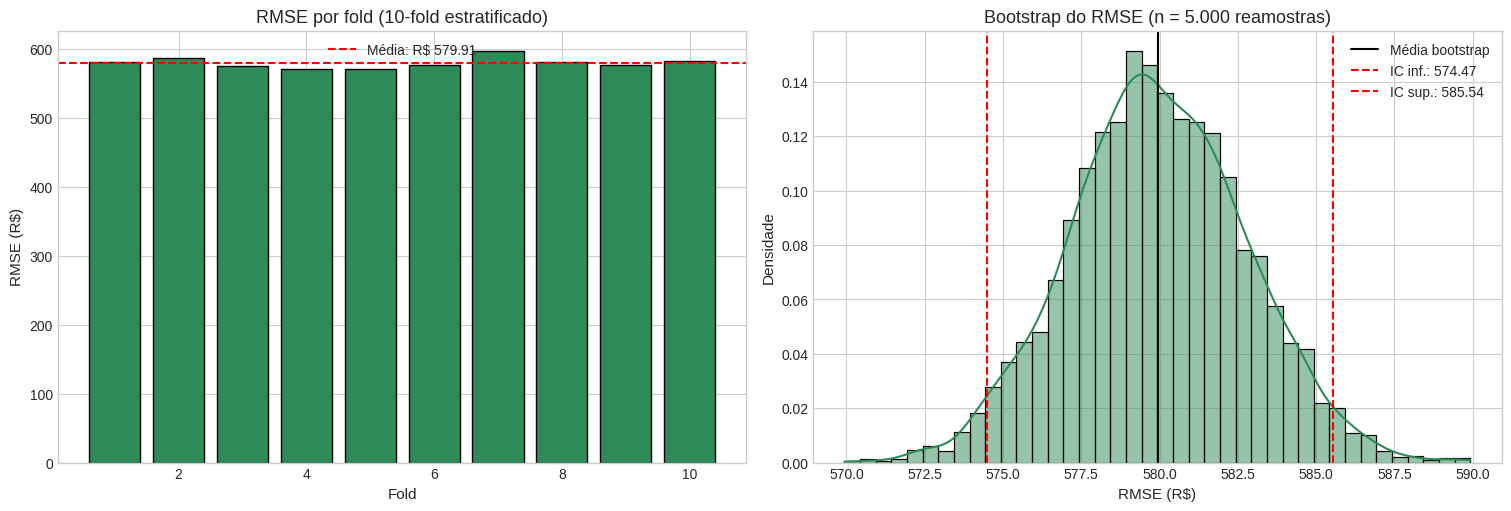

In [ ]:
# ==============================================================
# PARTE 2 | A1.3.1: Intervalo de confiança: Train
# Validação Cruzada e Análise Bootstrapping (modelo escolhido: Lasso L1)
# Requer: X_train, y_train, colunas_X (A1.2) e regressors (A1.3)
# Usa SOMENTE o conjunto de treino; validation e test não são tocados
# ==============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import StratifiedKFold

SEED = 42
K = 10                   # folds da validação cruzada
N_BOOT = 5000            # reamostragens bootstrap das métricas
N_BOOT_COEF = 500        # reamostragens bootstrap dos coeficientes (reajusta o modelo)
NIVEL = 0.95
ALFA = 1 - NIVEL

modelo = regressors["Lasso (L1)"]
n = len(y_train)
rng = np.random.default_rng(SEED)

# --------------------------------------------------------------
# 1. VALIDAÇÃO CRUZADA (K-Fold estratificado por TIPO DA CONTA)
# --------------------------------------------------------------
estrato = X_train[:, colunas_X.index("TIPO_CONTA_ORD")].astype(int)
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)

linhas_fold = []
oof = np.empty(n)                       # previsões "fora da dobra" (out-of-fold)
for k, (idx_tr, idx_te) in enumerate(skf.split(X_train, estrato), start=1):
    m = clone(modelo).fit(X_train[idx_tr], y_train[idx_tr])
    oof[idx_te] = m.predict(X_train[idx_te])
    linhas_fold.append({
        "Fold": k,
        "MAE (R$)": mean_absolute_error(y_train[idx_te], oof[idx_te]),
        "RMSE (R$)": np.sqrt(mean_squared_error(y_train[idx_te], oof[idx_te])),
        "R²": r2_score(y_train[idx_te], oof[idx_te]),
    })
cv = pd.DataFrame(linhas_fold).set_index("Fold")
print(f"VALIDAÇÃO CRUZADA ({K} folds) | Lasso (L1)")
display(cv.round(4))

# --------------------------------------------------------------
# 2. BOOTSTRAP das métricas (reamostra as previsões out-of-fold)
# --------------------------------------------------------------
def metricas_amostra(y, p):
    e = y - p
    return (np.sqrt(np.mean(e**2)),
            np.mean(np.abs(e)),
            1 - np.sum(e**2) / np.sum((y - y.mean())**2))

boot = np.empty((N_BOOT, 3))
for b in range(N_BOOT):
    i = rng.integers(0, n, n)
    boot[b] = metricas_amostra(y_train[i], oof[i])
boot = pd.DataFrame(boot, columns=["RMSE (R$)", "MAE (R$)", "R²"])

# --------------------------------------------------------------
# 3. Intervalos de confiança (95%)
# --------------------------------------------------------------
t_crit = stats.t.ppf(1 - ALFA / 2, df=K - 1)
resumo = {}
for nome in ["RMSE (R$)", "MAE (R$)", "R²"]:
    media, dp = cv[nome].mean(), cv[nome].std(ddof=1)
    ep_cv = dp / np.sqrt(K)
    resumo[nome] = {
        "CV média": media,
        "CV desvio (folds)": dp,
        "CV IC inferior": media - t_crit * ep_cv,
        "CV IC superior": media + t_crit * ep_cv,
        "Boot erro-padrão": boot[nome].std(ddof=1),
        "Boot IC inferior": boot[nome].quantile(ALFA / 2),
        "Boot IC superior": boot[nome].quantile(1 - ALFA / 2),
    }
print(f"\nINTERVALOS DE CONFIANÇA ({NIVEL:.0%}) | TRAIN")
display(pd.DataFrame(resumo).T.round(4))

# --------------------------------------------------------------
# 4. Bootstrap dos coeficientes (reajusta o Lasso em cada reamostra)
# --------------------------------------------------------------
coefs = np.empty((N_BOOT_COEF, X_train.shape[1]))
for b in range(N_BOOT_COEF):
    i = rng.integers(0, n, n)
    coefs[b] = clone(modelo).fit(X_train[i], y_train[i]).coef_

coef_final = clone(modelo).fit(X_train, y_train).coef_
tab_coef = pd.DataFrame({
    "coeficiente": coef_final,
    "erro-padrão (boot)": coefs.std(axis=0, ddof=1),
    "IC inferior": np.quantile(coefs, ALFA / 2, axis=0),
    "IC superior": np.quantile(coefs, 1 - ALFA / 2, axis=0),
}, index=colunas_X)
tab_coef["IC contém 0?"] = (tab_coef["IC inferior"] <= 0) & (tab_coef["IC superior"] >= 0)
tab_coef = tab_coef.reindex(tab_coef["coeficiente"].abs().sort_values(ascending=False).index)
print(f"\nCOEFICIENTES: IC {NIVEL:.0%} por bootstrap ({N_BOOT_COEF} reamostras)")
display(tab_coef.round(3))

# --------------------------------------------------------------
# 5. Gráficos
# --------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")

ax[0].bar(cv.index, cv["RMSE (R$)"], color="seagreen", edgecolor="black")
ax[0].axhline(cv["RMSE (R$)"].mean(), color="red", linestyle="--",
              label=f"Média: R$ {cv['RMSE (R$)'].mean():.2f}")
ax[0].set_title(f"RMSE por fold ({K}-fold estratificado)")
ax[0].set_xlabel("Fold"); ax[0].set_ylabel("RMSE (R$)"); ax[0].legend()

r = resumo["RMSE (R$)"]
sns.histplot(boot["RMSE (R$)"], bins=40, kde=True, stat="density", color="seagreen", ax=ax[1])
ax[1].axvline(boot["RMSE (R$)"].mean(), color="black", label="Média bootstrap")
ax[1].axvline(r["Boot IC inferior"], color="red", linestyle="--",
              label=f"IC inf.: {r['Boot IC inferior']:.2f}")
ax[1].axvline(r["Boot IC superior"], color="red", linestyle="--",
              label=f"IC sup.: {r['Boot IC superior']:.2f}")
ax[1].set_title(f"Bootstrap do RMSE (n = {N_BOOT:,} reamostras)".replace(",", "."))
ax[1].set_xlabel("RMSE (R$)"); ax[1].set_ylabel("Densidade"); ax[1].legend()
plt.show()

### A1.3.2: Intervalo de confiança: Validation

VALIDAÇÃO CRUZADA (10 partições da validação. n = 7.545) | Lasso (L1)


,RMSE (R$),MAE (R$),R²
Fold,,,
1,578.3358,396.8104,0.6980
2,572.4827,403.3693,0.7092
3,562.6259,390.1183,0.7103
4,555.5568,380.8793,0.7329
5,577.6267,409.3230,0.7086
6,583.5149,403.2945,0.6999
7,572.5385,402.9916,0.7184
8,584.5481,403.1027,0.6968
9,609.8870,422.2366,0.6918



INTERVALOS DE CONFIANÇA (95%) | VALIDATION


,Valor na validação,CV média,CV desvio (folds),CV IC inferior,CV IC superior,Boot erro-padrão,Boot IC inferior,Boot IC superior
RMSE (R$),575.5739,575.3802,15.9036,564.0035,586.7570,6.1018,563.6530,587.6633
MAE (R$),399.5980,399.6003,12.2653,390.8262,408.3744,4.8073,390.4169,409.1954
R²,0.7047,0.7039,0.0161,0.6924,0.7154,0.0056,0.6933,0.7153



BOOTSTRAP POR TIPO DA CONTA (IC 95%)


,n,RMSE (R$),RMSE IC inf.,RMSE IC sup.,R²,R² IC inf.,R² IC sup.
Estrato,,,,,,,
ESSENTIAL,3011,178.2935,169.1881,188.3847,0.6255,0.5513,0.6805
VIP,1699,380.9361,368.1116,393.9794,0.3077,0.2317,0.3744
PRIME,2835,872.3231,855.6015,888.0157,0.3005,0.2749,0.3255



CONSISTÊNCIA TRAIN x VALIDATION (RMSE, R$)
Train      IC 95%: [574.47; 585.54]
Validation IC 95%: [563.65; 587.66]
Os intervalos se sobrepõem: desempenho consistente.


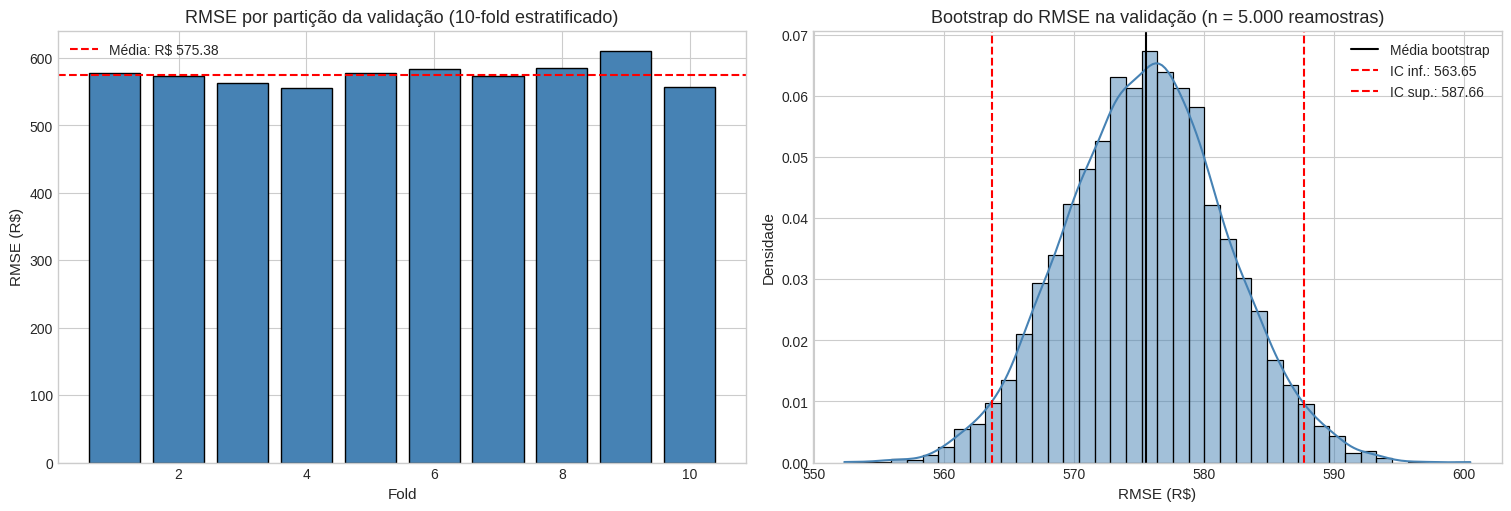

In [ ]:
# ==============================================================
# PARTE 2 | A1.3.2: Intervalo de confiança: Validation
# Validação Cruzada e Análise Bootstrapping (modelo escolhido: Lasso L1)
# Requer: regressors (A1.3 | já treinado no TRAIN), X_val, y_val, colunas_X
# (opcional) resumo da A1.3.1, para comparar com o intervalo do Train
# O modelo NÃO é reajustado aqui; test continua reservado
# ==============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import StratifiedKFold

SEED = 42
K = 10
N_BOOT = 5000
NIVEL = 0.95
ALFA = 1 - NIVEL

modelo = regressors["Lasso (L1)"]              # ajustado no TRAIN na A1.3
y_pred = modelo.predict(X_val)
n = len(y_val)
rng = np.random.default_rng(SEED)

estrato = X_val[:, colunas_X.index("TIPO_CONTA_ORD")].astype(int)
NOMES_ESTRATO = {0: "ESSENTIAL", 1: "VIP", 2: "PRIME"}

def metricas(y, p):
    e = y - p
    return (np.sqrt(np.mean(e**2)), np.mean(np.abs(e)),
            1 - np.sum(e**2) / np.sum((y - y.mean())**2))

NOMES_METRICAS = ["RMSE (R$)", "MAE (R$)", "R²"]
pontual = dict(zip(NOMES_METRICAS, metricas(y_val, y_pred)))

# --------------------------------------------------------------
# 1. VALIDAÇÃO CRUZADA sobre o conjunto de validação
#    (K partições estratificadas; modelo fixo, sem reajuste)
# --------------------------------------------------------------
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
linhas = []
for k, (_, idx) in enumerate(skf.split(X_val, estrato), start=1):
    linhas.append(dict(zip(["Fold"] + NOMES_METRICAS, (k, *metricas(y_val[idx], y_pred[idx])))))
cv = pd.DataFrame(linhas).set_index("Fold")
print(f"VALIDAÇÃO CRUZADA ({K} partições da validação, n = {n:,}) | Lasso (L1)".replace(",", "."))
display(cv.round(4))

# --------------------------------------------------------------
# 2. BOOTSTRAP das métricas na validação
# --------------------------------------------------------------
boot = np.empty((N_BOOT, 3))
for b in range(N_BOOT):
    i = rng.integers(0, n, n)
    boot[b] = metricas(y_val[i], y_pred[i])
boot = pd.DataFrame(boot, columns=NOMES_METRICAS)

# --------------------------------------------------------------
# 3. Intervalos de confiança (95%)
# --------------------------------------------------------------
t_crit = stats.t.ppf(1 - ALFA / 2, df=K - 1)
resumo_val = {}
for nome in NOMES_METRICAS:
    media, dp = cv[nome].mean(), cv[nome].std(ddof=1)
    ep = dp / np.sqrt(K)
    resumo_val[nome] = {
        "Valor na validação": pontual[nome],
        "CV média": media,
        "CV desvio (folds)": dp,
        "CV IC inferior": media - t_crit * ep,
        "CV IC superior": media + t_crit * ep,
        "Boot erro-padrão": boot[nome].std(ddof=1),
        "Boot IC inferior": boot[nome].quantile(ALFA / 2),
        "Boot IC superior": boot[nome].quantile(1 - ALFA / 2),
    }
print(f"\nINTERVALOS DE CONFIANÇA ({NIVEL:.0%}) | VALIDATION")
display(pd.DataFrame(resumo_val).T.round(4))

# --------------------------------------------------------------
# 4. Bootstrap por TIPO DA CONTA (onde está a incerteza?)
# --------------------------------------------------------------
linhas = []
for cod, nome_e in NOMES_ESTRATO.items():
    m = estrato == cod
    ye, pe = y_val[m], y_pred[m]
    ne = m.sum()
    b = np.array([metricas(ye[i], pe[i]) for i in (rng.integers(0, ne, ne) for _ in range(N_BOOT))])
    rmse, _, r2 = metricas(ye, pe)
    linhas.append({
        "Estrato": nome_e, "n": ne,
        "RMSE (R$)": rmse,
        "RMSE IC inf.": np.quantile(b[:, 0], ALFA / 2), "RMSE IC sup.": np.quantile(b[:, 0], 1 - ALFA / 2),
        "R²": r2,
        "R² IC inf.": np.quantile(b[:, 2], ALFA / 2), "R² IC sup.": np.quantile(b[:, 2], 1 - ALFA / 2),
    })
print(f"\nBOOTSTRAP POR TIPO DA CONTA (IC {NIVEL:.0%})")
display(pd.DataFrame(linhas).set_index("Estrato").round(4))

# --------------------------------------------------------------
# 5. Consistência com o Train (se a A1.3.1 foi executada)
# --------------------------------------------------------------
if "resumo" in globals():
    tr = resumo["RMSE (R$)"]
    v = resumo_val["RMSE (R$)"]
    sobrepoe = (v["Boot IC inferior"] <= tr["Boot IC superior"]) and (tr["Boot IC inferior"] <= v["Boot IC superior"])
    print("\nCONSISTÊNCIA TRAIN x VALIDATION (RMSE, R$)")
    print(f"Train      IC {NIVEL:.0%}: [{tr['Boot IC inferior']:.2f}; {tr['Boot IC superior']:.2f}]")
    print(f"Validation IC {NIVEL:.0%}: [{v['Boot IC inferior']:.2f}; {v['Boot IC superior']:.2f}]")
    print("Os intervalos se sobrepõem: desempenho consistente." if sobrepoe
          else "Os intervalos NÃO se sobrepõem: investigar diferença entre treino e validação.")

# --------------------------------------------------------------
# 6. Gráficos
# --------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")

ax[0].bar(cv.index, cv["RMSE (R$)"], color="steelblue", edgecolor="black")
ax[0].axhline(cv["RMSE (R$)"].mean(), color="red", linestyle="--",
              label=f"Média: R$ {cv['RMSE (R$)'].mean():.2f}")
ax[0].set_title(f"RMSE por partição da validação ({K}-fold estratificado)")
ax[0].set_xlabel("Fold"); ax[0].set_ylabel("RMSE (R$)"); ax[0].legend()

r = resumo_val["RMSE (R$)"]
sns.histplot(boot["RMSE (R$)"], bins=40, kde=True, stat="density", color="steelblue", ax=ax[1])
ax[1].axvline(boot["RMSE (R$)"].mean(), color="black", label="Média bootstrap")
ax[1].axvline(r["Boot IC inferior"], color="red", linestyle="--", label=f"IC inf.: {r['Boot IC inferior']:.2f}")
ax[1].axvline(r["Boot IC superior"], color="red", linestyle="--", label=f"IC sup.: {r['Boot IC superior']:.2f}")
ax[1].set_title(f"Bootstrap do RMSE na validação (n = {N_BOOT:,} reamostras)".replace(",", "."))
ax[1].set_xlabel("RMSE (R$)"); ax[1].set_ylabel("Densidade"); ax[1].legend()
plt.show()

##Atividade A1.4 (4º Passo): Medir a acurácia (score) dos Modelos de Regressão:

### A1.4.1: Exibir os Coeficientes de Determinação ($R^2$)

* Conjunto de Treinamento:

* Conjunto de Validação:

* Conjunto de Teste:

In [ ]:
# # ==============================================================
# PARTE 2 | A1.4.1: Exibir os Coeficientes de Determinação (R²)
# Requer: regressors (A1.3), X/y de train, val e test (A1.2)
# Cada bloco "# %%" corresponde a uma célula da print
# ==============================================================

# %% Train
import pandas as pd

MODELO_ESCOLHIDO = "Lasso (L1)"          # escolhido na validação (A1.3)

r2_train = {nome: m.score(X_train, y_train) for nome, m in regressors.items()}
print(f"Conjunto de Treinamento: R² = {r2_train[MODELO_ESCOLHIDO]:.4f}  ({MODELO_ESCOLHIDO})")

# %% Validation
r2_val = {nome: m.score(X_val, y_val) for nome, m in regressors.items()}
print(f"Conjunto de Validação:   R² = {r2_val[MODELO_ESCOLHIDO]:.4f}  ({MODELO_ESCOLHIDO})")

# %% Teste
# Primeiro uso do conjunto de teste. O modelo já foi escolhido na validação:
# o resultado abaixo NÃO deve ser usado para trocar de modelo.
r2_test = {nome: m.score(X_test, y_test) for nome, m in regressors.items()}
print(f"Conjunto de Teste:       R² = {r2_test[MODELO_ESCOLHIDO]:.4f}  ({MODELO_ESCOLHIDO})")

# Resumo de todos os regressores (ordenado pelo R² da validação)
tabela_r2 = pd.DataFrame({
    "R² Treino": r2_train,
    "R² Validação": r2_val,
    "R² Teste": r2_test,
})
tabela_r2["Treino − Teste"] = tabela_r2["R² Treino"] - tabela_r2["R² Teste"]
tabela_r2 = tabela_r2.sort_values("R² Validação", ascending=False).round(4)

display(tabela_r2.style.apply(
    lambda linha: ["font-weight: bold" if linha.name == MODELO_ESCOLHIDO else "" for _ in linha],
    axis=1))

Conjunto de Treinamento: R² = 0.7047  (Lasso (L1))
Conjunto de Validação:   R² = 0.7047  (Lasso (L1))
Conjunto de Teste:       R² = 0.7104  (Lasso (L1))


,R² Treino,R² Validação,R² Teste,Treino − Teste
Lasso (L1),0.704700,0.704700,0.710400,-0.005700
Ridge (L2),0.704700,0.704600,0.710400,-0.005700
Regressão Linear,0.704700,0.704600,0.710400,-0.005700
Random Forest,0.795000,0.702500,0.709300,0.085700
ElasticNet (L1+L2),0.700300,0.702200,0.705000,-0.004700
Gradient Boosting,0.738100,0.701100,0.708000,0.030100
Árvore de Decisão,0.720700,0.686700,0.696400,0.024400
KNN (k=15),0.691700,0.647600,0.649200,0.042500
Baseline (média),0.000000,-0.000000,-0.000200,0.000200


### A1.4.2: Plotagem dos Conjuntos - REAL ($y$) x ESTIMADO ($\hat{y}$):

* Conjunto de Treinamento:

* Conjunto de Validação:

* Conjunto de Teste:

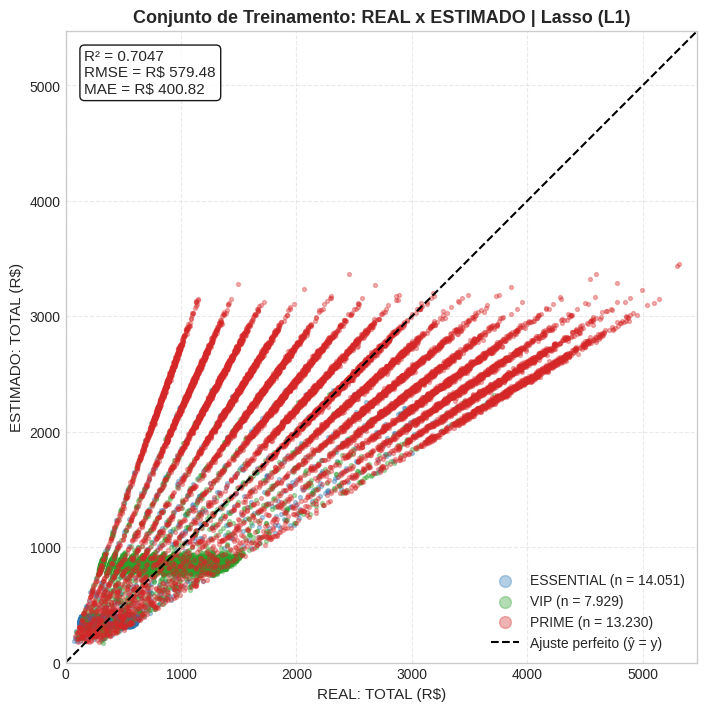

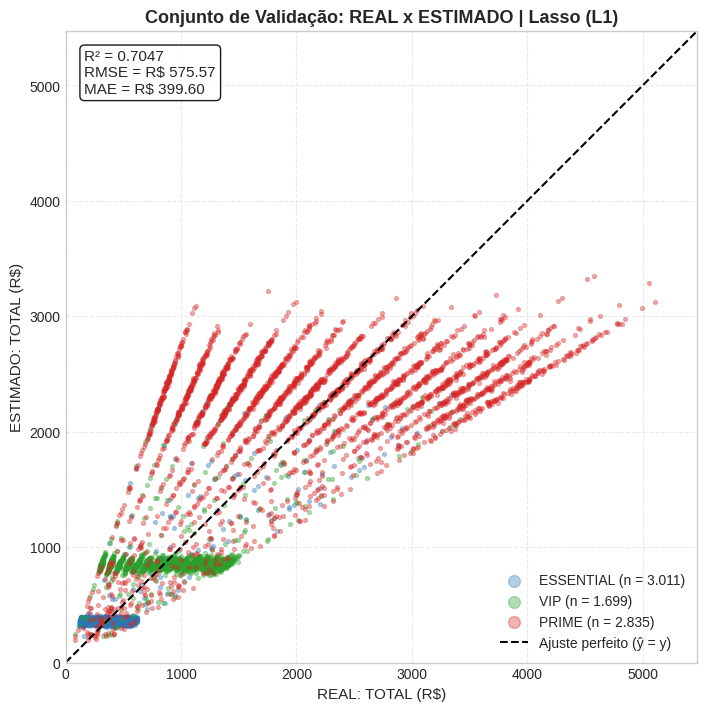

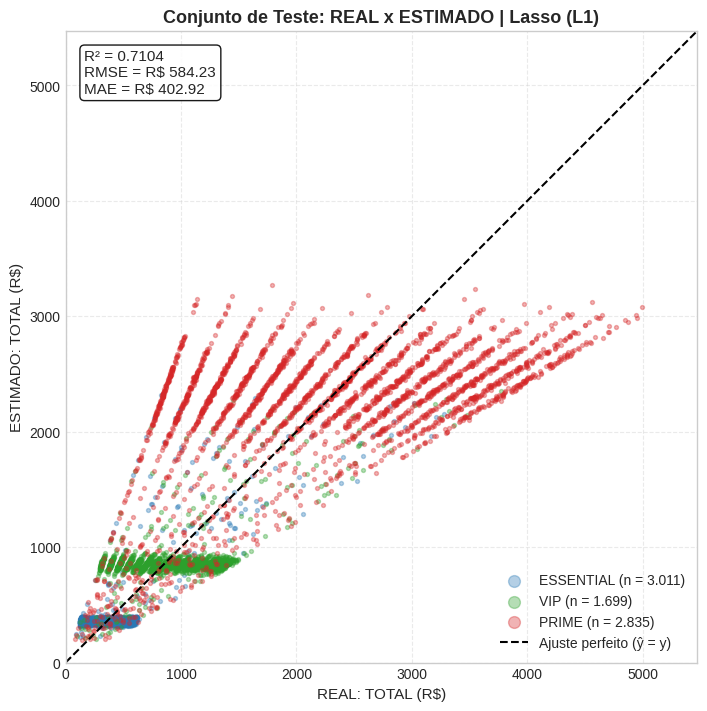

In [ ]:
# ==============================================================
# PARTE 2 | A1.4.2: Plotagem dos Conjuntos - REAL (y) x ESTIMADO (ŷ)
# Requer: regressors (A1.3), X/y de train, val e test, colunas_X (A1.2)
# Cada bloco "# %%" corresponde a uma célula (função, Train, Validation, Teste)
# ==============================================================

# %% Função de plotagem
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MODELO_ESCOLHIDO = "Lasso (L1)"
modelo = regressors[MODELO_ESCOLHIDO]

idx_conta = colunas_X.index("TIPO_CONTA_ORD")
NOMES_ESTRATO = {0: "ESSENTIAL", 1: "VIP", 2: "PRIME"}
CORES_ESTRATO = {0: "#2878B5", 1: "#2CA02C", 2: "#D62728"}

# Mesmos limites nos 3 gráficos, para comparação direta
_LIM = max(y_train.max(), y_val.max(), y_test.max()) * 1.03

def plotar_real_estimado(X, y, titulo):
    """
    Dispersão REAL (y) x ESTIMADO (ŷ) com a reta ideal y = ŷ.
    Pontos coloridos por TIPO DA CONTA; exibe R², RMSE e MAE.
    """
    y_hat = modelo.predict(X)
    estrato = X[:, idx_conta].astype(int)

    fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
    for cod, nome in NOMES_ESTRATO.items():
        m = estrato == cod
        ax.scatter(y[m], y_hat[m], s=8, alpha=0.35, color=CORES_ESTRATO[cod],
                   label=f"{nome} (n = {m.sum():,})".replace(",", "."))
    ax.plot([0, _LIM], [0, _LIM], "k--", linewidth=1.5, label="Ajuste perfeito (ŷ = y)")

    texto = (f"R² = {r2_score(y, y_hat):.4f}\n"
             f"RMSE = R$ {np.sqrt(mean_squared_error(y, y_hat)):.2f}\n"
             f"MAE = R$ {mean_absolute_error(y, y_hat):.2f}")
    ax.text(0.03, 0.97, texto, transform=ax.transAxes, va="top", fontsize=11,
            bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9})

    ax.set_xlim(0, _LIM); ax.set_ylim(0, _LIM); ax.set_aspect("equal")
    ax.set_xlabel("REAL: TOTAL (R$)"); ax.set_ylabel("ESTIMADO: TOTAL (R$)")
    ax.set_title(f"{titulo} | {MODELO_ESCOLHIDO}", fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="lower right", markerscale=3)
    plt.show()

# %% Train
plotar_real_estimado(X_train, y_train, "Conjunto de Treinamento: REAL x ESTIMADO")

# %% Validation
plotar_real_estimado(X_val, y_val, "Conjunto de Validação: REAL x ESTIMADO")

# %% Teste
plotar_real_estimado(X_test, y_test, "Conjunto de Teste: REAL x ESTIMADO")

### A1.4.3: Análise dos Resíduos: $\epsilon = y_{real} - y_{estimado}$

* Conjunto de Treinamento:

* Conjunto de Validação:

* Conjunto de Teste:

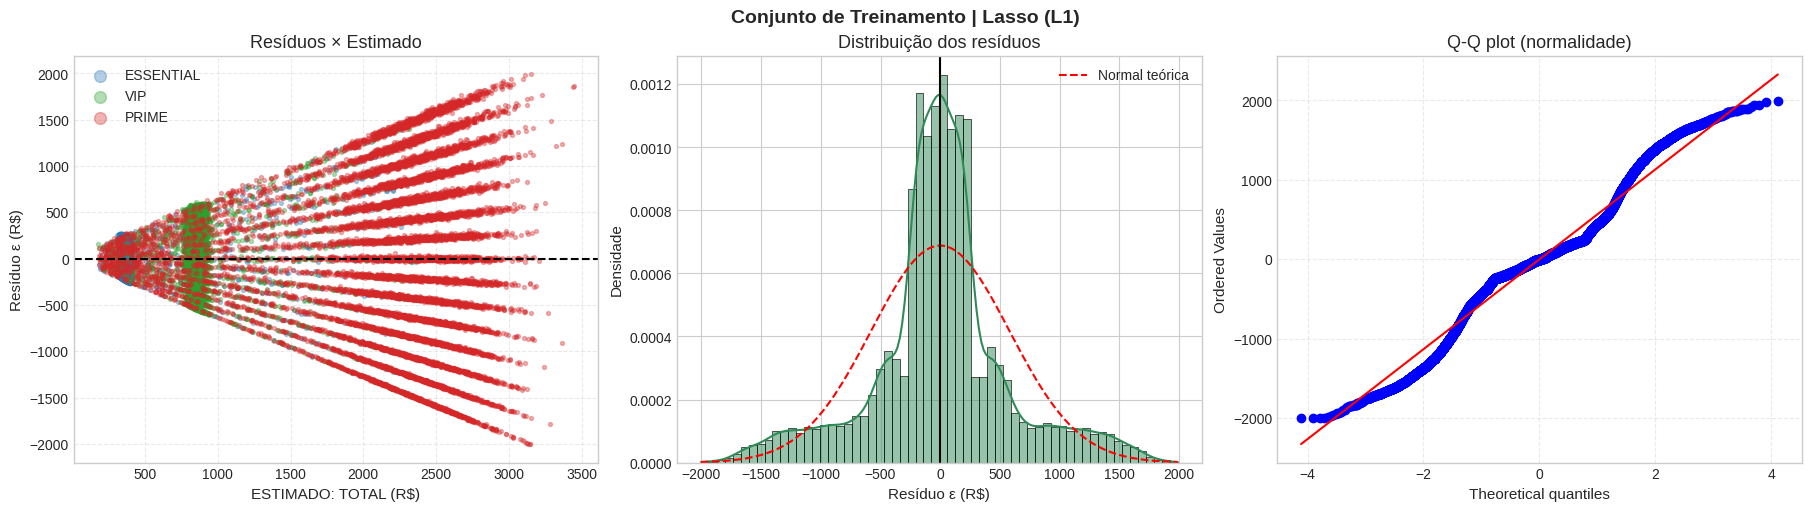

RESÍDUOS | Conjunto de Treinamento


,valor
n,35210.0000
Média de ε (R$),-0.0000
Desvio de ε (R$),579.4911
Mínimo (R$),-2003.1616
Mediana (R$),-2.6988
Máximo (R$),1987.8375
Assimetria,0.0202
Curtose (excesso),1.3291
Normalidade (D'Agostino) p-valor,0.0000
"Spearman(|ε|, ŷ)",0.6720


Normalidade: resíduos NÃO normais (p ≤ 0,05).
Variância: o erro absoluto cresce com o valor estimado (ρ = 0.67): heterocedasticidade.

Resíduos por TIPO DA CONTA:


,n,Média de ε (R$),Desvio de ε (R$)
ESSENTIAL,14051.0,-0.93,182.81
VIP,7929.0,3.72,367.64
PRIME,13230.0,-1.25,881.62


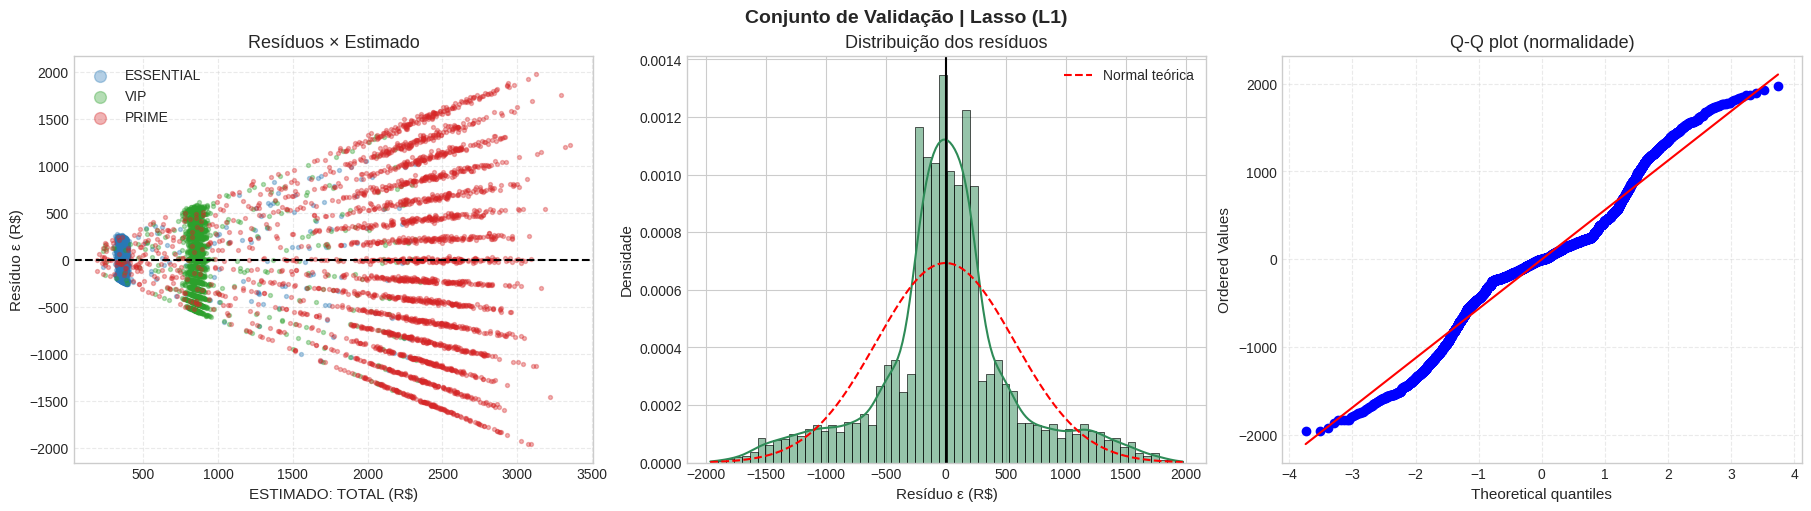

RESÍDUOS | Conjunto de Validação


,valor
n,7545.0000
Média de ε (R$),-1.9049
Desvio de ε (R$),575.6089
Mínimo (R$),-1963.1241
Mediana (R$),-3.1082
Máximo (R$),1975.5440
Assimetria,0.0238
Curtose (excesso),1.3216
Normalidade (D'Agostino) p-valor,0.0000
"Spearman(|ε|, ŷ)",0.6590


Normalidade: resíduos NÃO normais (p ≤ 0,05).
Variância: o erro absoluto cresce com o valor estimado (ρ = 0.66): heterocedasticidade.

Resíduos por TIPO DA CONTA:


,n,Média de ε (R$),Desvio de ε (R$)
ESSENTIAL,3011.0,5.22,178.25
VIP,1699.0,-6.19,381.00
PRIME,2835.0,-6.91,872.45


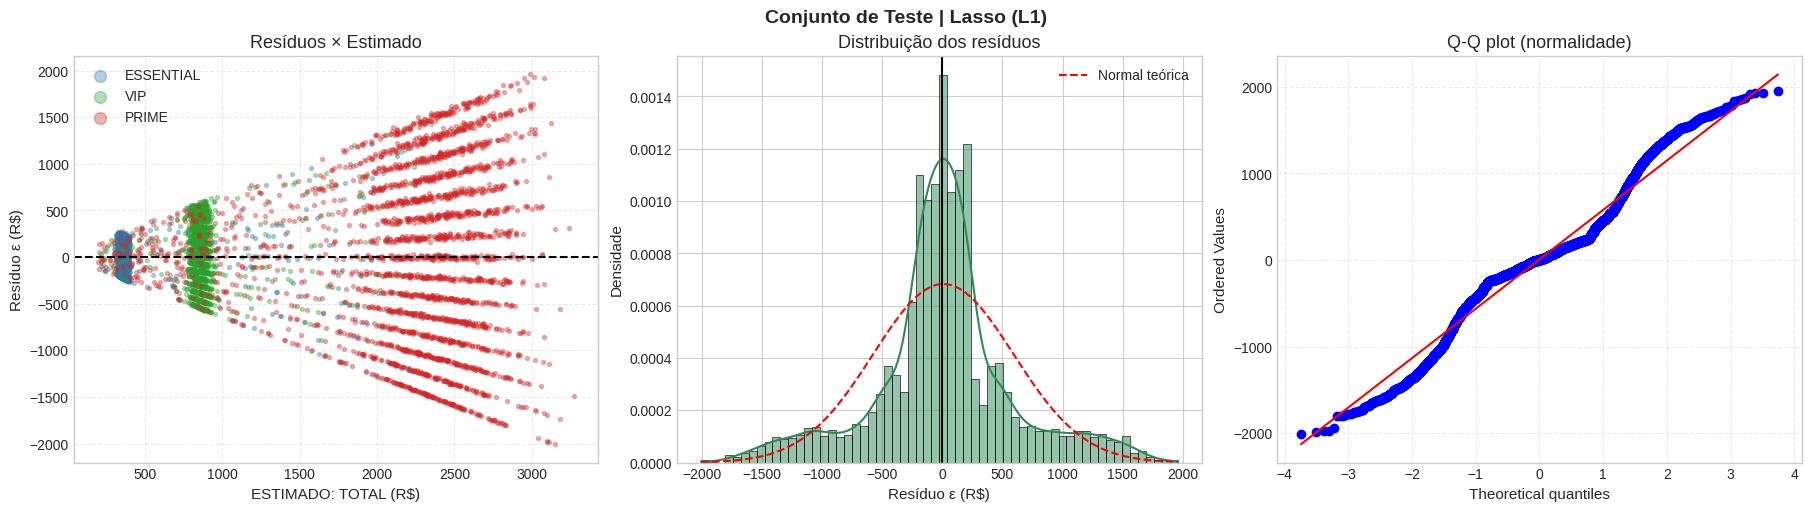

RESÍDUOS | Conjunto de Teste


,valor
n,7545.0000
Média de ε (R$),9.2369
Desvio de ε (R$),584.1945
Mínimo (R$),-2005.5216
Mediana (R$),3.8740
Máximo (R$),1957.9521
Assimetria,0.0219
Curtose (excesso),1.2908
Normalidade (D'Agostino) p-valor,0.0000
"Spearman(|ε|, ŷ)",0.6656


Normalidade: resíduos NÃO normais (p ≤ 0,05).
Variância: o erro absoluto cresce com o valor estimado (ρ = 0.67): heterocedasticidade.

Resíduos por TIPO DA CONTA:


,n,Média de ε (R$),Desvio de ε (R$)
ESSENTIAL,3011.0,-0.51,181.54
VIP,1699.0,-1.28,357.83
PRIME,2835.0,25.90,892.37


In [ ]:
# ==============================================================
# PARTE 2 | A1.4.3: Análise dos Resíduos: ε = y_real − y_estimado
# Requer: regressors (A1.3), X/y de train, val e test, colunas_X (A1.2)
# Cada bloco "# %%" corresponde a uma célula (função, Train, Validation, Teste)
# ==============================================================

# %% Função de análise dos resíduos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

MODELO_ESCOLHIDO = "Lasso (L1)"
modelo = regressors[MODELO_ESCOLHIDO]

idx_conta = colunas_X.index("TIPO_CONTA_ORD")
NOMES_ESTRATO = {0: "ESSENTIAL", 1: "VIP", 2: "PRIME"}
CORES_ESTRATO = {0: "#2878B5", 1: "#2CA02C", 2: "#D62728"}

def analisar_residuos(X, y, titulo):
    """
    ε = y_real − y_estimado. Exibe: (1) ε × ŷ, (2) histograma de ε com curva normal,
    (3) Q-Q plot; e imprime estatísticas, testes de normalidade e de
    heterocedasticidade, além do erro por TIPO DA CONTA. Retorna ε.
    """
    y_hat = modelo.predict(X)
    eps = y - y_hat
    estrato = X[:, idx_conta].astype(int)

    fig, ax = plt.subplots(1, 3, figsize=(18, 5), layout="constrained")
    fig.suptitle(f"{titulo} | {MODELO_ESCOLHIDO}", fontsize=14, fontweight="bold")

    # (1) Resíduos x estimado
    for cod, nome in NOMES_ESTRATO.items():
        m = estrato == cod
        ax[0].scatter(y_hat[m], eps[m], s=8, alpha=0.35, color=CORES_ESTRATO[cod], label=nome)
    ax[0].axhline(0, color="black", linestyle="--")
    ax[0].set_xlabel("ESTIMADO: TOTAL (R$)"); ax[0].set_ylabel("Resíduo ε (R$)")
    ax[0].set_title("Resíduos × Estimado"); ax[0].legend(markerscale=3)
    ax[0].grid(True, linestyle="--", alpha=0.4)

    # (2) Histograma + normal teórica
    sns.histplot(eps, bins=60, stat="density", kde=True, color="seagreen", ax=ax[1])
    xs = np.linspace(eps.min(), eps.max(), 300)
    ax[1].plot(xs, stats.norm.pdf(xs, eps.mean(), eps.std(ddof=1)), "r--", label="Normal teórica")
    ax[1].axvline(0, color="black")
    ax[1].set_xlabel("Resíduo ε (R$)"); ax[1].set_ylabel("Densidade")
    ax[1].set_title("Distribuição dos resíduos"); ax[1].legend()

    # (3) Q-Q plot
    stats.probplot(eps, dist="norm", plot=ax[2])
    ax[2].set_title("Q-Q plot (normalidade)"); ax[2].grid(True, linestyle="--", alpha=0.4)
    plt.show()

    # Estatísticas
    k2, p_norm = stats.normaltest(eps)                    # D'Agostino-Pearson
    rho, p_het = stats.spearmanr(y_hat, np.abs(eps))      # |ε| cresce com ŷ?
    resumo = pd.Series({
        "n": len(eps),
        "Média de ε (R$)": eps.mean(),
        "Desvio de ε (R$)": eps.std(ddof=1),
        "Mínimo (R$)": eps.min(),
        "Mediana (R$)": np.median(eps),
        "Máximo (R$)": eps.max(),
        "Assimetria": stats.skew(eps),
        "Curtose (excesso)": stats.kurtosis(eps),
        "Normalidade (D'Agostino) p-valor": p_norm,
        "Spearman(|ε|, ŷ)": rho,
        "Heterocedasticidade p-valor": p_het,
    })
    print(f"RESÍDUOS | {titulo}")
    display(resumo.to_frame("valor").round(4))
    print("Normalidade:", "resíduos compatíveis com a normal." if p_norm > 0.05
          else "resíduos NÃO normais (p ≤ 0,05).")
    print("Variância:", f"o erro absoluto cresce com o valor estimado (ρ = {rho:.2f}): heterocedasticidade."
          if (p_het <= 0.05 and rho > 0.1) else "sem evidência forte de heterocedasticidade.")

    por_estrato = pd.DataFrame({
        e: {"n": int((estrato == c).sum()),
            "Média de ε (R$)": eps[estrato == c].mean(),
            "Desvio de ε (R$)": eps[estrato == c].std(ddof=1)}
        for c, e in NOMES_ESTRATO.items()
    }).T
    print("\nResíduos por TIPO DA CONTA:")
    display(por_estrato.round(2))
    return eps

# %% Train
eps_train = analisar_residuos(X_train, y_train, "Conjunto de Treinamento")

# %% Validation
eps_val = analisar_residuos(X_val, y_val, "Conjunto de Validação")

# %% Teste
eps_test = analisar_residuos(X_test, y_test, "Conjunto de Teste")

### A1.4.4: JOINT: Resíduos ($\epsilon$) vs Valores Estimado ($\hat{y}$)

* Conjunto de Treinamento:

* Conjunto de Validação:

* Conjunto de Teste:

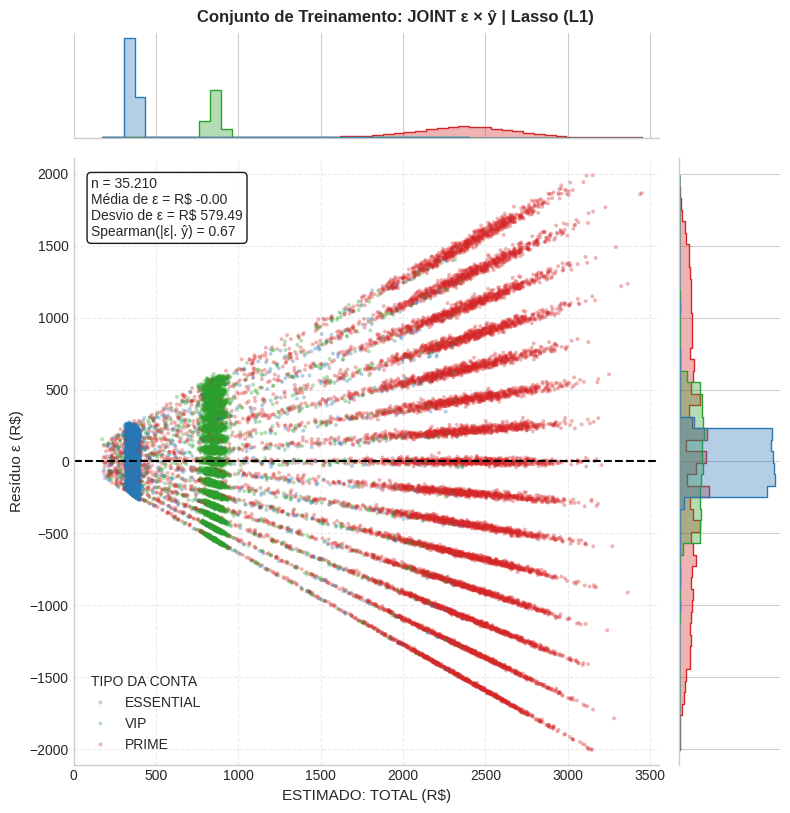

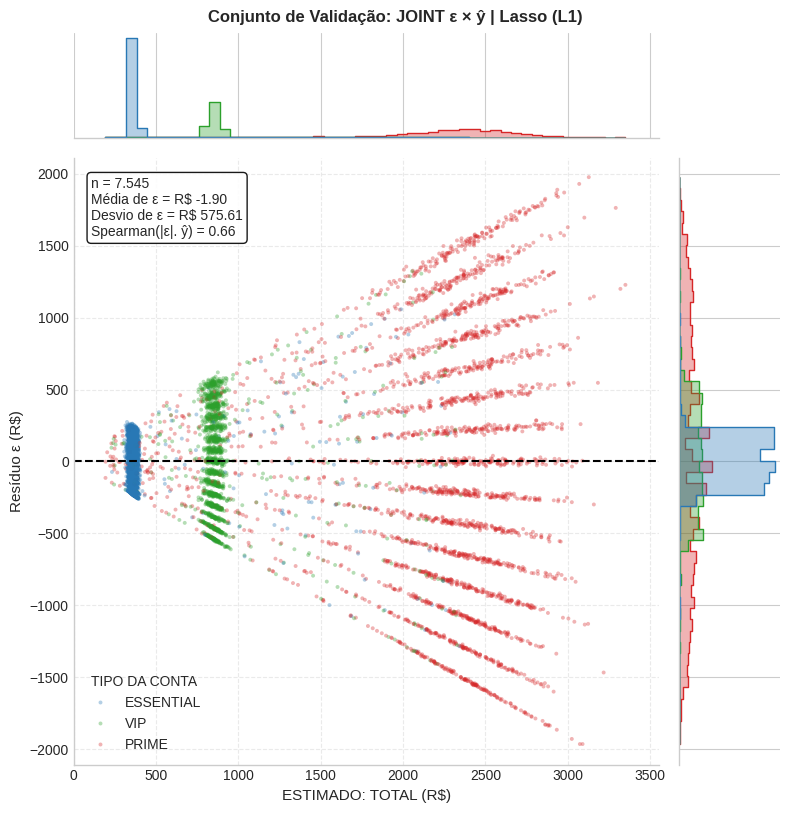

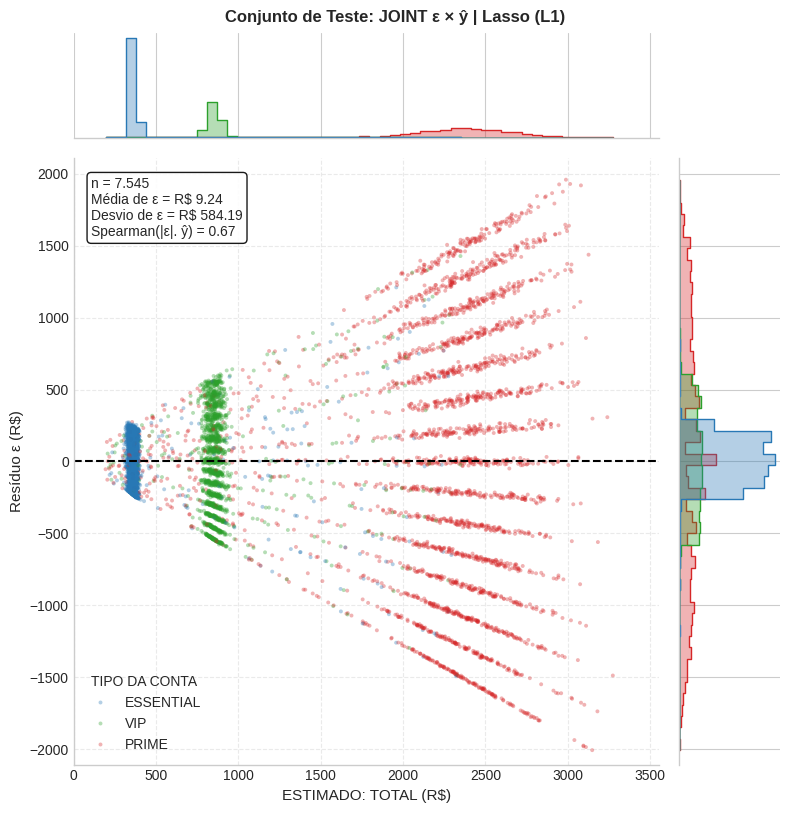

In [ ]:
# ==============================================================
# PARTE 2 | A1.4.4: JOINT: Resíduos (ε) vs Valores Estimados (ŷ)
# Requer: regressors (A1.3), X/y de train, val e test, colunas_X (A1.2)
# Cada bloco "# %%" corresponde a uma célula (função, Train, Validation, Teste)
# ==============================================================

# %% Função do gráfico JOINT
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

MODELO_ESCOLHIDO = "Lasso (L1)"
modelo = regressors[MODELO_ESCOLHIDO]

idx_conta = colunas_X.index("TIPO_CONTA_ORD")
NOMES_ESTRATO = {0: "ESSENTIAL", 1: "VIP", 2: "PRIME"}
CORES_ESTRATO = {"ESSENTIAL": "#2878B5", "VIP": "#2CA02C", "PRIME": "#D62728"}

# Mesmos limites nos 3 gráficos, para comparação direta
_eps_max = max(np.abs(y_train - modelo.predict(X_train)).max(),
               np.abs(y_val - modelo.predict(X_val)).max(),
               np.abs(y_test - modelo.predict(X_test)).max()) * 1.05
_yhat_max = max(modelo.predict(X_train).max(), modelo.predict(X_val).max(),
                modelo.predict(X_test).max()) * 1.03

def plotar_joint(X, y, titulo):
    """
    JOINT: dispersão de ε (eixo y) contra ŷ (eixo x), com os histogramas
    marginais de cada variável. Cor = TIPO DA CONTA. Reta ε = 0 em destaque.
    """
    y_hat = modelo.predict(X)
    df = pd.DataFrame({
        "ESTIMADO: TOTAL (R$)": y_hat,
        "Resíduo ε (R$)": y - y_hat,
        "TIPO DA CONTA": pd.Series(X[:, idx_conta].astype(int)).map(NOMES_ESTRATO).to_numpy(),
    })

    g = sns.JointGrid(data=df, x="ESTIMADO: TOTAL (R$)", y="Resíduo ε (R$)",
                      hue="TIPO DA CONTA", palette=CORES_ESTRATO,
                      hue_order=list(CORES_ESTRATO), height=8, xlim=(0, _yhat_max),
                      ylim=(-_eps_max, _eps_max))
    g.plot_joint(sns.scatterplot, s=8, alpha=0.35, linewidth=0)
    g.plot_marginals(sns.histplot, bins=50, element="step", alpha=0.35, common_norm=False)
    g.ax_joint.axhline(0, color="black", linestyle="--", linewidth=1.5)
    g.ax_joint.grid(True, linestyle="--", alpha=0.4)

    rho = df["ESTIMADO: TOTAL (R$)"].corr(df["Resíduo ε (R$)"].abs(), method="spearman")
    g.ax_joint.text(0.03, 0.97,
                    f"n = {len(df):,}\nMédia de ε = R$ {df['Resíduo ε (R$)'].mean():.2f}\n"
                    f"Desvio de ε = R$ {df['Resíduo ε (R$)'].std():.2f}\n"
                    f"Spearman(|ε|, ŷ) = {rho:.2f}".replace(",", "."),
                    transform=g.ax_joint.transAxes, va="top", fontsize=10,
                    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9})
    g.figure.suptitle(f"{titulo} | {MODELO_ESCOLHIDO}", fontweight="bold", y=1.01)
    plt.show()

# %% Train
plotar_joint(X_train, y_train, "Conjunto de Treinamento: JOINT ε × ŷ")

# %% Validation
plotar_joint(X_val, y_val, "Conjunto de Validação: JOINT ε × ŷ")

# %% Teste
plotar_joint(X_test, y_test, "Conjunto de Teste: JOINT ε × ŷ")

##Atividade A1.5 (5º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

Amostra aleatória da população: 50.300 registros
Composição por tipo de conta (população x amostra Neyman):


,População (base completa),Amostra aleatória (A1.5),Amostra Neyman (train+val+test)
TIPO DA CONTA,,,
ESSENTIAL,61.00,62.06,39.91
PRIME,16.38,15.43,37.57
VIP,22.62,22.51,22.52



DESEMPENHO: TESTE x POPULAÇÃO


,R²,RMSE (R$),MAE (R$)
Teste (amostra Neyman),0.7104,584.2288,402.9194
População (amostra aleatória),0.7413,416.8027,268.6761



INTERVALO DE CONFIANÇA (95%) | POPULAÇÃO


,valor,erro-padrão (boot),IC 95% inferior,IC 95% superior
R²,0.7413,0.0025,0.7363,0.7463
RMSE (R$),416.8027,2.2890,412.2210,421.3226
MAE (R$),268.6761,1.4172,265.8789,271.4066



DESEMPENHO POR TIPO DA CONTA | POPULAÇÃO


,n,R²,RMSE (R$),MAE (R$),Média de ε (R$)
ESSENTIAL,31217.0,0.6230,181.1560,135.6540,-0.9903
VIP,11323.0,0.3340,374.5704,310.5478,0.8886
PRIME,7760.0,0.2976,888.4444,742.7013,-1.8994


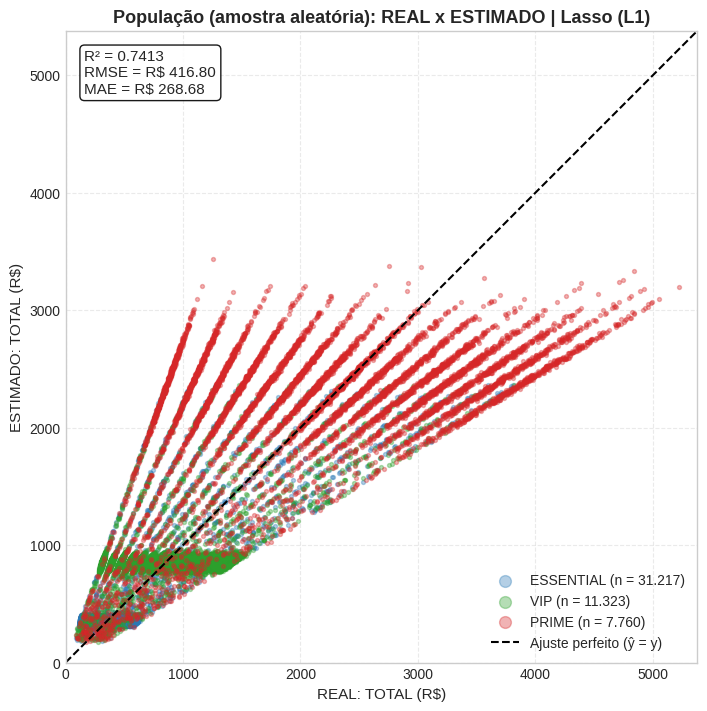

In [ ]:
# ==============================================================
# PARTE 2 | A1.5 (5º Passo): Testar o Modelo: Dados da População
#           amostra aleatória (Sample)
# Requer: table39, amostra_ideal (Load dos Datasets), preparar (A1.1),
#         regressors (A1.3), colunas_X (A1.2), X_test e y_test (A1.2)
# Modelo: Lasso (L1) já treinado no TRAIN; NÃO é reajustado aqui.
# ==============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 2026
N_POP = 50300            # mesmo tamanho ideal da amostra estratificada
N_BOOT = 2000
ESTRATO = "TIPO DA CONTA"
MODELO_ESCOLHIDO = "Lasso (L1)"
modelo = regressors[MODELO_ESCOLHIDO]
rng = np.random.default_rng(SEED)

# --------------------------------------------------------------
# 1. Amostra aleatória SIMPLES da população (proporções reais dos estratos)
#    Exclui os registros já usados em train/validation/test (sem vazamento)
# --------------------------------------------------------------
populacao_disponivel = table39.drop(index=amostra_ideal.index)
amostra_pop = populacao_disponivel.sample(n=N_POP, random_state=SEED)

# Mesma preparação da A1.1 (scaler e categorias definidos SOMENTE no treino)
X_pop_df, y_pop_s = preparar(amostra_pop)
assert list(X_pop_df.columns) == list(colunas_X), "Colunas diferentes das do treino."
X_pop = X_pop_df.to_numpy(dtype=np.float64)
y_pop = y_pop_s.to_numpy(dtype=np.float64)
y_hat = modelo.predict(X_pop)
eps = y_pop - y_hat
estrato = amostra_pop[ESTRATO].to_numpy()

print(f"Amostra aleatória da população: {N_POP:,} registros".replace(",", "."))
print("Composição por tipo de conta (população x amostra Neyman):")
display(pd.DataFrame({
    "População (base completa)": table39[ESTRATO].value_counts(normalize=True),
    "Amostra aleatória (A1.5)": amostra_pop[ESTRATO].value_counts(normalize=True),
    "Amostra Neyman (train+val+test)": amostra_ideal[ESTRATO].value_counts(normalize=True),
}).mul(100).round(2))

# --------------------------------------------------------------
# 2. Métricas na população e comparação com o conjunto de teste
# --------------------------------------------------------------
def metricas(y, p):
    return {"R²": r2_score(y, p),
            "RMSE (R$)": np.sqrt(mean_squared_error(y, p)),
            "MAE (R$)": mean_absolute_error(y, p)}

comparacao = pd.DataFrame({
    "Teste (amostra Neyman)": metricas(y_test, modelo.predict(X_test)),
    "População (amostra aleatória)": metricas(y_pop, y_hat),
}).T.round(4)
print("\nDESEMPENHO: TESTE x POPULAÇÃO")
display(comparacao)

# --------------------------------------------------------------
# 3. Bootstrap (IC 95%) das métricas na população
# --------------------------------------------------------------
boot = np.array([list(metricas(y_pop[i], y_hat[i]).values())
                 for i in (rng.integers(0, N_POP, N_POP) for _ in range(N_BOOT))])
ic = pd.DataFrame({
    "valor": metricas(y_pop, y_hat),
    "erro-padrão (boot)": dict(zip(["R²", "RMSE (R$)", "MAE (R$)"], boot.std(axis=0, ddof=1))),
    "IC 95% inferior": dict(zip(["R²", "RMSE (R$)", "MAE (R$)"], np.quantile(boot, 0.025, axis=0))),
    "IC 95% superior": dict(zip(["R²", "RMSE (R$)", "MAE (R$)"], np.quantile(boot, 0.975, axis=0))),
}).round(4)
print("\nINTERVALO DE CONFIANÇA (95%) | POPULAÇÃO")
display(ic)

# --------------------------------------------------------------
# 4. Erro por tipo de conta na população
# --------------------------------------------------------------
linhas = {}
for e in ["ESSENTIAL", "VIP", "PRIME"]:
    m = estrato == e
    linhas[e] = {"n": int(m.sum()), **metricas(y_pop[m], y_hat[m]),
                 "Média de ε (R$)": eps[m].mean()}
print("\nDESEMPENHO POR TIPO DA CONTA | POPULAÇÃO")
display(pd.DataFrame(linhas).T.round(4))

# --------------------------------------------------------------
# 5. Gráfico REAL x ESTIMADO na população
# --------------------------------------------------------------
cores = {"ESSENTIAL": "#2878B5", "VIP": "#2CA02C", "PRIME": "#D62728"}
lim = max(y_pop.max(), y_hat.max()) * 1.03
fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
for e, c in cores.items():
    m = estrato == e
    ax.scatter(y_pop[m], y_hat[m], s=8, alpha=0.35, color=c,
               label=f"{e} (n = {m.sum():,})".replace(",", "."))
ax.plot([0, lim], [0, lim], "k--", linewidth=1.5, label="Ajuste perfeito (ŷ = y)")
r = comparacao.loc["População (amostra aleatória)"]
ax.text(0.03, 0.97, f"R² = {r['R²']:.4f}\nRMSE = R$ {r['RMSE (R$)']:.2f}\nMAE = R$ {r['MAE (R$)']:.2f}",
        transform=ax.transAxes, va="top", fontsize=11,
        bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9})
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("REAL: TOTAL (R$)"); ax.set_ylabel("ESTIMADO: TOTAL (R$)")
ax.set_title(f"População (amostra aleatória): REAL x ESTIMADO | {MODELO_ESCOLHIDO}", fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.4); ax.legend(loc="lower right", markerscale=3)
plt.show()

## RELATÓRIO PARCIAL - MODELO DE REGRESSÃO

Fazer aqui o **RRELATÓRIO PARCIAL - MODELO DE REGRESSÃO** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.



O objetivo desta etapa foi construir um modelo capaz de prever o valor total de cada nota fiscal a partir do perfil do cliente. Para isso, usamos uma amostra de 50.300 notas, dividida de forma proporcional entre os tipos de conta, sendo 35.210 para treinar o modelo, 7.545 para validar e 7.545 para testar. Comparamos nove modelos de regressão e escolhemos o Lasso, um modelo linear simples, por ter apresentado o melhor desempenho na validação.

O Lasso explica cerca de 70,5% da variação do valor das notas nos dados de treino e de validação e 71,0% nos dados de teste, o que mostra que o modelo funciona da mesma forma em dados novos e não apenas decorou os dados usados no treinamento. Modelos mais complexos não trouxeram ganho: o Random Forest, por exemplo, teve 79,5% de acerto no treino, mas apenas 70,9% no teste.

Para medir o desempenho real para a empresa, aplicamos o modelo a uma amostra aleatória de 50.300 notas da base completa, que mantém as proporções reais de cada tipo de conta e não foi usada no treinamento. Nessa amostra, o modelo explica 74,1% da variação do valor das notas e erra, em média, R\$ 269 por nota, com erro típico (RMSE) de R\$ 417. O resultado é mais favorável que o do teste (RMSE de R\$ 584) porque a amostra de teste tinha mais clientes PRIME, que são os mais difíceis de prever.

O fator que mais influencia o valor da nota é a renda do cliente. As características dos vinhos e a nota de satisfação praticamente não alteram a previsão. O modelo não superestima nem subestima o valor na média, mas o erro cresce junto com o valor da compra: o erro típico é de cerca de R\$ 181 nos clientes ESSENTIAL, R\$ 375 nos VIP e R\$ 888 nos PRIME. Por isso, o modelo explica bem o perfil ESSENTIAL (62% da variação), mas apenas cerca de 33% no VIP e 30% no PRIME.

A principal limitação é que cerca de 26% da variação do valor das notas não é explicada pelas informações disponíveis. Concluímos que o Lasso é confiável para estimar o valor médio das notas, principalmente no perfil ESSENTIAL, mas a previsão individual é pouco precisa para os clientes VIP e PRIME. Como próximo passo, sugerimos investigar outras variáveis que expliquem melhor esses dois perfis.

#Atividade A2: Modelo de Clusterização

##Atividade A2.1 (1º Passo): Normalizar - Mapear - Discretizar

In [ ]:
# ==============================================================
# PARTE 2 | Atividade A2.1 (1º Passo): Normalizar - Mapear - Discretizar
#           (Modelo de CLUSTERIZAÇÃO, aprendizado não supervisionado)
# Requer: train, validation, test (Load dos Datasets) e as definições da A1.1:
#         discretizar_opiniao, MAPA_SEXO, MAPA_CONTA, COLS_DUMMY, CATEGORIAS
# Diferença para a A1.1: não existe alvo (y). TOTAL (R$) vira variável de entrada.
# ==============================================================
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

IDENTIFICADOR = "NOTA FISCAL"
ALVO_COMO_ENTRADA = "TOTAL (R$)"

# --------------------------------------------------------------
# Opções (altere se necessário)
# --------------------------------------------------------------
INCLUIR_TOTAL = True          # TOTAL (R$) como variável de segmentação
INCLUIR_TIPO_CONTA = False     # TIPO DA CONTA (0=ESSENTIAL, 1=VIP, 2=PRIME)
INCLUIR_MEAN_VINHO = False    # 13 variáveis "MEAN:" – excluídas: teste A2.4.1 mostrou que são ruído (silhueta 0,134 -> 0,364)

# --------------------------------------------------------------
# 1. Variáveis numéricas a NORMALIZAR (z-score, ajustado SOMENTE no treino)
# --------------------------------------------------------------
cols_num = [c for c in train.select_dtypes(include="number").columns if c != IDENTIFICADOR]
if not INCLUIR_TOTAL:
    cols_num = [c for c in cols_num if c != ALVO_COMO_ENTRADA]
if not INCLUIR_MEAN_VINHO:
    cols_num = [c for c in cols_num if not c.startswith("MEAN:")]

scaler_c = StandardScaler().fit(train[cols_num])

# --------------------------------------------------------------
# 2. Preparação: Normalizar + Mapear + Discretizar (igual nos 3 conjuntos)
# --------------------------------------------------------------
def preparar_cluster(df):
    # Normalizar
    num = pd.DataFrame(scaler_c.transform(df[cols_num]), columns=cols_num, index=df.index)
    # Mapear
    mapeadas = pd.DataFrame(index=df.index)
    mapeadas["SEXO_FEMININO"] = df["SEXO"].map(MAPA_SEXO)
    if INCLUIR_TIPO_CONTA:
        mapeadas["TIPO_CONTA_ORD"] = df["TIPO DA CONTA"].map(MAPA_CONTA)
    dummies = [
        pd.get_dummies(
            pd.Series(pd.Categorical(df[c], categories=CATEGORIAS[c]), index=df.index),
            prefix=c.replace(" ", "_"), drop_first=True, dtype=int)
        for c in COLS_DUMMY
    ]
    # Discretizar
    disc = pd.DataFrame({"NIVEL_SATISFACAO": discretizar_opiniao(df["OPINIÃO DO CLIENTE"])},
                        index=df.index)
    # Binárias e ordinais entram na escala 0/1 e 1-5: padroniza as ordinais/discretas
    X = pd.concat([num, mapeadas, *dummies, disc], axis=1)
    if X.isna().any().any():
        raise ValueError("Há valores ausentes após a preparação.")
    return X

Xc_train = preparar_cluster(train)
Xc_val = preparar_cluster(validation)
Xc_test = preparar_cluster(test)

# Colunas ordinais/discretas (TIPO_CONTA_ORD 0-2 e NIVEL_SATISFACAO 1-5) são padronizadas
# com a média e o desvio do TREINO, para não dominar nem sumir na distância euclidiana.
cols_escala_extra = [c for c in ["TIPO_CONTA_ORD", "NIVEL_SATISFACAO"] if c in Xc_train.columns]
scaler_extra = StandardScaler().fit(Xc_train[cols_escala_extra])
for X in (Xc_train, Xc_val, Xc_test):
    X[cols_escala_extra] = scaler_extra.transform(X[cols_escala_extra])

colunas_cluster = list(Xc_train.columns)

# --------------------------------------------------------------
# 3. Relatório
# --------------------------------------------------------------
print(f"Xc_train: {Xc_train.shape} | Xc_val: {Xc_val.shape} | Xc_test: {Xc_test.shape}")
print(f"\nVariáveis para a clusterização ({len(colunas_cluster)}):")
print(colunas_cluster)

print("\nConferência (média ~0 e desvio ~1 no treino):")
conf = pd.DataFrame({"média treino": Xc_train[cols_num + cols_escala_extra].mean(),
                     "desvio treino": Xc_train[cols_num + cols_escala_extra].std(),
                     "média validação": Xc_val[cols_num + cols_escala_extra].mean()}).round(3)
display(conf)

# Pares muito correlacionados (redundância pesa na distância dos clusters)
corr = Xc_train.corr().abs()
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().sort_values(ascending=False))
pares = pares[pares > 0.7].round(3)
print("\nPares de variáveis com |correlação| > 0,70 (treino):")
display(pares.to_frame("|r|") if len(pares) else "nenhum par acima de 0,70")
display(Xc_train.head())

Xc_train: (35210, 12) | Xc_val: (7545, 12) | Xc_test: (7545, 12)

Variáveis para a clusterização (12):
['DEPENDENTES', 'RENDA BRUTO (R$)', 'NOTA DE SATISFAÇÃO (%)', 'TOTAL (R$)', 'SEXO_FEMININO', 'REGIÃO_NORDESTE', 'REGIÃO_NORTE', 'REGIÃO_SUDESTE', 'REGIÃO_SUL', 'ESTADO_CIVIL_DESQUITADO(A) / VIÚVO(A)', 'ESTADO_CIVIL_SOLTEIRO', 'NIVEL_SATISFACAO']

Conferência (média ~0 e desvio ~1 no treino):


,média treino,desvio treino,média validação
DEPENDENTES,-0.0,1.0,-0.013
RENDA BRUTO (R$),-0.0,1.0,0.001
NOTA DE SATISFAÇÃO (%),-0.0,1.0,-0.002
TOTAL (R$),0.0,1.0,-0.001
NIVEL_SATISFACAO,0.0,1.0,-0.001



Pares de variáveis com |correlação| > 0,70 (treino):


,,|r|
RENDA BRUTO (R$),TOTAL (R$),0.839


,DEPENDENTES,RENDA BRUTO (R$),NOTA DE SATISFAÇÃO (%),TOTAL (R$),SEXO_FEMININO,REGIÃO_NORDESTE,REGIÃO_NORTE,REGIÃO_SUDESTE,REGIÃO_SUL,ESTADO_CIVIL_DESQUITADO(A) / VIÚVO(A),ESTADO_CIVIL_SOLTEIRO,NIVEL_SATISFACAO
105333,-1.109577,-0.934841,-0.348082,-0.784054,1,1,0,0,0,0,1,0.381144
646093,1.996415,-0.928708,-0.348082,-0.596219,0,0,0,1,0,0,0,0.381144
316800,-1.109577,1.241644,0.946746,1.627543,0,0,0,1,0,0,1,-4.537041
934947,-0.074246,-0.327675,-0.348082,-0.427664,0,0,0,1,0,0,0,0.381144
278487,-1.109577,-0.922363,-0.348082,-0.866391,0,0,0,0,1,0,0,0.381144


##Atividade A2.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [ ]:
# ==============================================================
# PARTE 2 | Atividade A2.2 (2º Passo) - ETL: Separar Entrada (X) da Saída (y)
# (Clusterização)
# Requer: Xc_train, Xc_val, Xc_test, colunas_cluster (A2.1), train, validation,
#         test (Load dos Datasets) e MAPA_CONTA (A1.1)
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
# ==============================================================
import numpy as np

# --------------------------------------------------------------
# X: entrada do algoritmo de clusterização (DataFrame -> ndarray 2D)
# np.asarray permite rodar a célula mais de uma vez sem erro
# --------------------------------------------------------------
Xc_train = np.asarray(Xc_train, dtype=np.float64)
Xc_val   = np.asarray(Xc_val,   dtype=np.float64)
Xc_test  = np.asarray(Xc_test,  dtype=np.float64)

# --------------------------------------------------------------
# y: RÓTULO DE REFERÊNCIA (não existe alvo em clusterização)
# TIPO DA CONTA (0=ESSENTIAL, 1=VIP, 2=PRIME). NÃO entra no ajuste dos clusters;
# serve apenas para avaliar, depois, se os grupos se parecem com os perfis conhecidos.
# --------------------------------------------------------------
yc_train = train["TIPO DA CONTA"].map(MAPA_CONTA).to_numpy(dtype=np.int64)
yc_val   = validation["TIPO DA CONTA"].map(MAPA_CONTA).to_numpy(dtype=np.int64)
yc_test  = test["TIPO DA CONTA"].map(MAPA_CONTA).to_numpy(dtype=np.int64)

# --------------------------------------------------------------
# Verificações de integridade
# --------------------------------------------------------------
for nome, X, y in [("train", Xc_train, yc_train),
                   ("validation", Xc_val, yc_val),
                   ("test", Xc_test, yc_test)]:
    assert isinstance(X, np.ndarray) and isinstance(y, np.ndarray)
    assert X.ndim == 2 and y.ndim == 1
    assert X.shape[0] == y.shape[0], f"{nome}: X e y com tamanhos diferentes"
    assert X.shape[1] == len(colunas_cluster)
    assert np.isfinite(X).all(), f"{nome}: há NaN/inf em X"

# --------------------------------------------------------------
# Relatório
# --------------------------------------------------------------
print(f"{'conjunto':<12}{'X (shape)':<18}{'y (shape)':<14}{'dtype X'}")
for nome, X, y in [("train", Xc_train, yc_train),
                   ("validation", Xc_val, yc_val),
                   ("test", Xc_test, yc_test)]:
    print(f"{nome:<12}{str(X.shape):<18}{str(y.shape):<14}{X.dtype}")
print(f"\nEntradas (X): {len(colunas_cluster)} variáveis")
print("Referência (y): TIPO DA CONTA, apenas para avaliação externa dos clusters")
if "TIPO_CONTA_ORD" in colunas_cluster:
    print("ATENÇÃO: TIPO_CONTA_ORD está em X; a comparação com y não será independente.")

conjunto    X (shape)         y (shape)     dtype X
train       (35210, 12)       (35210,)      float64
validation  (7545, 12)        (7545,)       float64
test        (7545, 12)        (7545,)       float64

Entradas (X): 12 variáveis
Referência (y): TIPO DA CONTA, apenas para avaliação externa dos clusters


##Atividade A2.3 (3º Passo): Aplicar o Método do Cotovelo

KMeans ajustado para k = 1..10 em 8.9 s

MÉTODO DO COTOVELO | KMeans (treino)


,Inércia,Redução vs k-1 (%)
k,,
1,205895.2059,NaN
2,143605.4340,30.2531
3,122994.5900,14.3524
4,103726.1044,15.6661
5,88597.5372,14.5851
6,83188.5560,6.1051
7,77813.9857,6.4607
8,74079.7318,4.7989
9,70985.8025,4.1765



k no cotovelo (maior curvatura): 4


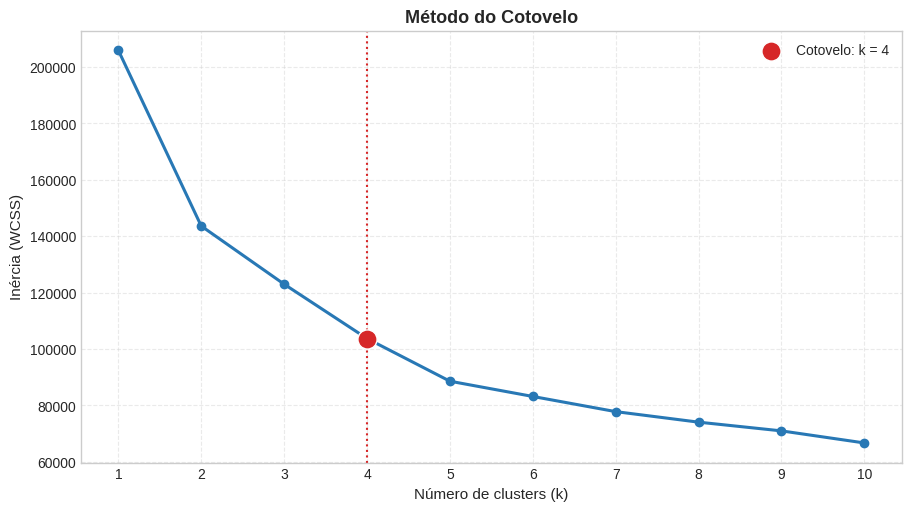

In [ ]:
# ==============================================================
# PARTE 2 | Atividade A2.3 (3º Passo): Aplicar o Método do Cotovelo
# Requer: Xc_train (ndarray, A2.2)  | usa SOMENTE o conjunto de treino
# ==============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

SEED = 42
K_MIN, K_MAX = 1, 10
ks = list(range(K_MIN, K_MAX + 1))

# --------------------------------------------------------------
# 1. Inércia (soma das distâncias² aos centróides, WCSS) para cada k
# --------------------------------------------------------------
inercia = []
inicio = time.perf_counter()
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xc_train)
    inercia.append(km.inertia_)
inercia = np.array(inercia)
print(f"KMeans ajustado para k = {K_MIN}..{K_MAX} em {time.perf_counter() - inicio:.1f} s")

# --------------------------------------------------------------
# 2. Cotovelo: ponto mais distante da reta entre (k_min, J_max) e (k_max, J_min)
#    (curva normalizada para [0, 1])
# --------------------------------------------------------------
x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
y = (inercia - inercia.min()) / (inercia.max() - inercia.min())
distancia = np.abs(y + x - 1) / np.sqrt(2)          # a reta vai de (0, 1) a (1, 0)
k_cotovelo = ks[int(np.argmax(distancia))]

tabela = pd.DataFrame({
    "k": ks,
    "Inércia": inercia,
    "Redução vs k-1 (%)": np.r_[np.nan, -np.diff(inercia) / inercia[:-1] * 100],
}).set_index("k")
print("\nMÉTODO DO COTOVELO | KMeans (treino)")
display(tabela.round(4))
print(f"\nk no cotovelo (maior curvatura): {k_cotovelo}")

# --------------------------------------------------------------
# 3. Gráfico
# --------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.plot(ks, inercia, "o-", color="#2878B5", linewidth=2.2)
ax.scatter(k_cotovelo, inercia[ks.index(k_cotovelo)], s=190, color="#D62728",
           edgecolor="white", zorder=5, label=f"Cotovelo: k = {k_cotovelo}")
ax.axvline(k_cotovelo, color="#D62728", linestyle=":")
ax.set_title("Método do Cotovelo", fontweight="bold")
ax.set_xlabel("Número de clusters (k)"); ax.set_ylabel("Inércia (WCSS)")
ax.set_xticks(ks); ax.grid(True, linestyle="--", alpha=0.4); ax.legend()
plt.show()

##Atividade A2.4 (4º Passo): Aplicar o Método da Silhueta

Silhueta calculada para k = 2..10 (10.000 pontos) em 45.8 s

MÉTODO DA SILHUETA | KMeans (treino)


,Silhueta média,Menor silhueta de cluster,% pontos com silhueta < 0,Maior cluster (%)
k,,,,
2,0.3391,0.1750,3.56,66.3931
3,0.3136,0.2202,1.42,64.7231
4,0.2955,0.1912,1.92,51.7239
5,0.2928,0.1801,2.93,41.3831
6,0.2825,0.1164,2.34,41.2269
7,0.2866,0.1369,1.81,41.1417
8,0.2658,0.1040,3.25,40.3408
9,0.2187,0.0900,6.58,27.2309
10,0.2257,0.0995,3.67,27.2110



k com maior silhueta média: 2 (silhueta = 0.3391)


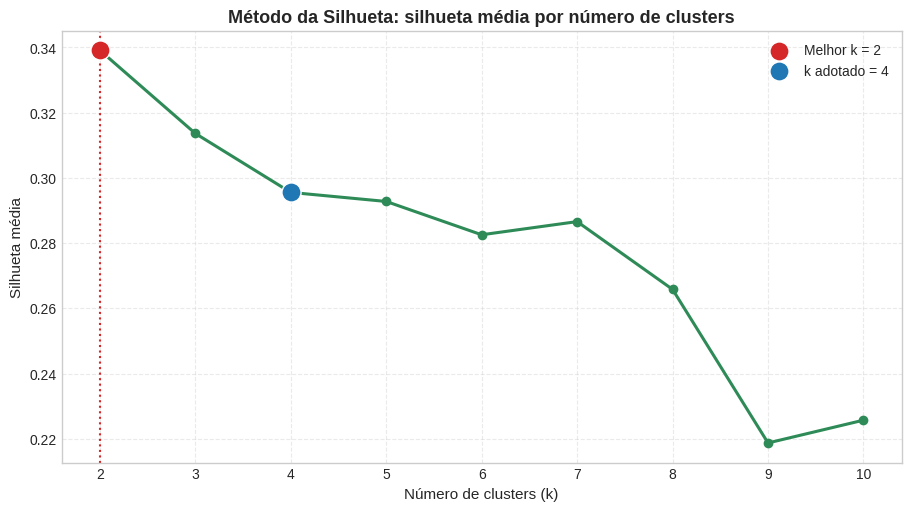

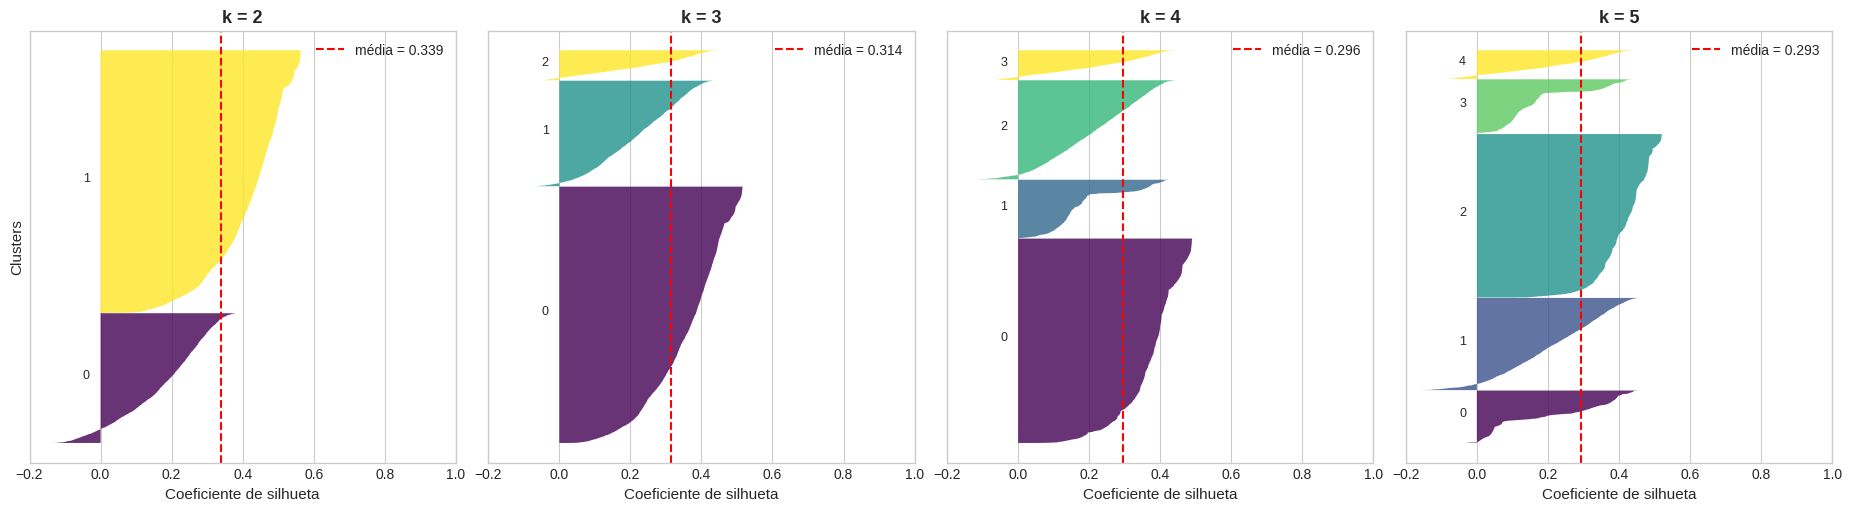


Cotovelo (A2.3): k = 4 | Silhueta máxima (A2.4): k = 2
k adotado: 4  (silhueta = 0.296; estrutura razoável, >= 0,25)

Justificativa: k = 2 tem a maior silhueta (0.339), mas a diferença para k = 4 é pequena (0.044) e ambos estão na mesma faixa de qualidade.
A silhueta tende a favorecer poucos grupos grandes; k = 2 separaria os clientes em apenas 2 segmentos, pouco útil para segmentação.
Por isso adota-se k = 4, coincidente com o cotovelo.


In [ ]:
# ==============================================================
# PARTE 2 | Atividade A2.4 (4º Passo): Aplicar o Método da Silhueta
# Requer: Xc_train (ndarray, A2.2)  | usa SOMENTE o conjunto de treino
# ==============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples

SEED = 42
KS = list(range(2, 11))                       # silhueta exige k >= 2
N_AMOSTRA = min(10000, len(Xc_train))         # silhueta é O(n²): usa amostra fixa
KS_DIAGRAMA = [2, 3, 4, 5]                    # k exibidos no diagrama de silhueta

idx = np.random.default_rng(SEED).choice(len(Xc_train), size=N_AMOSTRA, replace=False)
X_amostra = Xc_train[idx]

# --------------------------------------------------------------
# 1. Silhueta média para cada k (K-Means ajustado em TODO o treino)
# --------------------------------------------------------------
linhas, rotulos_amostra, valores_amostra = [], {}, {}
inicio = time.perf_counter()
for k in KS:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xc_train)
    r = km.labels_[idx]
    s = silhouette_samples(X_amostra, r)
    rotulos_amostra[k], valores_amostra[k] = r, s
    linhas.append({
        "k": k,
        "Silhueta média": s.mean(),
        "Menor silhueta de cluster": min(s[r == c].mean() for c in range(k)),
        "% pontos com silhueta < 0": (s < 0).mean() * 100,
        "Maior cluster (%)": np.bincount(km.labels_).max() / len(Xc_train) * 100,
    })
tabela = pd.DataFrame(linhas).set_index("k")
k_silhueta = int(tabela["Silhueta média"].idxmax())
print(f"Silhueta calculada para k = {KS[0]}..{KS[-1]} "
      f"({N_AMOSTRA:,} pontos) em {time.perf_counter() - inicio:.1f} s".replace(",", "."))
print("\nMÉTODO DA SILHUETA | KMeans (treino)")
display(tabela.round(4))
print(f"\nk com maior silhueta média: {k_silhueta} "
      f"(silhueta = {tabela.loc[k_silhueta, 'Silhueta média']:.4f})")

K_FINAL = 4   # <- k adotado (altere aqui se mudar a decisão)

# --------------------------------------------------------------
# 2. Gráfico: silhueta média por k
# --------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.plot(KS, tabela["Silhueta média"], "o-", color="seagreen", linewidth=2.2)
ax.scatter(k_silhueta, tabela.loc[k_silhueta, "Silhueta média"], s=190, color="#D62728",
           edgecolor="white", zorder=5, label=f"Melhor k = {k_silhueta}")
ax.axvline(k_silhueta, color="#D62728", linestyle=":")
if K_FINAL != k_silhueta:
    ax.scatter(K_FINAL, tabela.loc[K_FINAL, "Silhueta média"], s=190, color="#1F77B4",
               edgecolor="white", zorder=5, label=f"k adotado = {K_FINAL}")
ax.set_title("Método da Silhueta: silhueta média por número de clusters", fontweight="bold")
ax.set_xlabel("Número de clusters (k)"); ax.set_ylabel("Silhueta média")
ax.set_xticks(KS); ax.grid(True, linestyle="--", alpha=0.4); ax.legend()
plt.show()

# --------------------------------------------------------------
# 3. Diagrama de silhueta por cluster (k selecionados)
# --------------------------------------------------------------
ks_plot = [k for k in KS_DIAGRAMA if k in rotulos_amostra]
fig, axes = plt.subplots(1, len(ks_plot), figsize=(4.6 * len(ks_plot), 5), layout="constrained")
axes = np.atleast_1d(axes)
for ax, k in zip(axes, ks_plot):
    r, s = rotulos_amostra[k], valores_amostra[k]
    y_inf = 10
    for c in range(k):
        sc = np.sort(s[r == c])
        y_sup = y_inf + len(sc)
        ax.fill_betweenx(np.arange(y_inf, y_sup), 0, sc,
                         facecolor=cm.viridis(c / max(k - 1, 1)), alpha=0.8)
        ax.text(-0.05, y_inf + 0.5 * len(sc), str(c), fontsize=9)
        y_inf = y_sup + 10
    ax.axvline(s.mean(), color="red", linestyle="--", label=f"média = {s.mean():.3f}")
    ax.set_title(f"k = {k}", fontweight="bold")
    ax.set_xlabel("Coeficiente de silhueta"); ax.set_yticks([])
    ax.set_xlim(-0.2, 1.0); ax.legend(loc="upper right")
axes[0].set_ylabel("Clusters")
plt.show()

# --------------------------------------------------------------
# 4. Decisão final de k
# --------------------------------------------------------------
s_final = tabela.loc[K_FINAL, "Silhueta média"]
s_max = tabela.loc[k_silhueta, "Silhueta média"]
print("\n" + "=" * 70)
if "k_cotovelo" in globals():
    print(f"Cotovelo (A2.3): k = {k_cotovelo} | Silhueta máxima (A2.4): k = {k_silhueta}")
print(f"k adotado: {K_FINAL}  (silhueta = {s_final:.3f}; "
      f"{'estrutura razoável, >= 0,25' if s_final >= 0.25 else 'estrutura fraca, < 0,25'})")
if K_FINAL != k_silhueta:
    print(f"\nJustificativa: k = {k_silhueta} tem a maior silhueta ({s_max:.3f}), mas a diferença "
          f"para k = {K_FINAL} é pequena ({s_max - s_final:.3f}) e ambos estão na mesma faixa de "
          f"qualidade.\nA silhueta tende a favorecer poucos grupos grandes; k = {k_silhueta} "
          f"separaria os clientes em apenas {k_silhueta} segmentos, pouco útil para segmentação.\n"
          f"Por isso adota-se k = {K_FINAL}, coincidente com o cotovelo.")
print("=" * 70)

##Atividade A2.5 (5º Passo): Criar o Modelo: **Clusters**

In [ ]:
# ============================================================
# A2.5 (1/2) – NDARRAY – TREINAMENTO: train e validation
# Ajusta o K-Means final no TREINO e atribui clusters à VALIDAÇÃO.
# Requer: Xc_train, Xc_val (ndarray), yc_train, yc_val (TIPO DA CONTA, só referência)
# ============================================================
import numpy as np, pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_FINAL = globals().get("K_FINAL", 4)      # vem da A2.4; padrão 4
SEED, N_SIL = 42, 10000

# ---------- 1. Modelo final (ajustado SOMENTE no treino) ----------
modelo_km = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED).fit(Xc_train)
labels_train = modelo_km.labels_
labels_val   = modelo_km.predict(Xc_val)
print(f"K-Means ajustado | k = {K_FINAL} | n_init = 20 | iterações = {modelo_km.n_iter_}")

# ---------- 2. Métricas: treino x validação ----------
def metricas(X, labels, nome, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), size=min(N_SIL, len(X)), replace=False)
    d2 = ((X - modelo_km.cluster_centers_[labels]) ** 2).sum(axis=1)
    return {"conjunto": nome, "n": len(X),
            "inércia média por cliente": d2.mean(),
            "silhueta (amostra)": silhouette_score(X[idx], labels[idx])}

def tabela_metricas(conjuntos):
    return pd.DataFrame([metricas(X, l, n) for n, X, l in conjuntos]).set_index("conjunto").round(4)

def tabela_tamanhos(conjuntos):
    t = pd.DataFrame({n: pd.Series(l).value_counts(normalize=True).sort_index() * 100
                      for n, _, l in conjuntos})
    t.index.name = "cluster"
    return t.round(1)

conj_tv = [("treino", Xc_train, labels_train), ("validação", Xc_val, labels_val)]
print("\nMÉTRICAS | treino x validação")
display(tabela_metricas(conj_tv))
print("\nTAMANHO DOS CLUSTERS (% de clientes)")
display(tabela_tamanhos(conj_tv))

# ---------- 3. Referência externa: TIPO DA CONTA (não usado no ajuste) ----------
nomes_tipo = {0: "ESSENTIAL", 1: "VIP", 2: "PRIME"}
for nome, y, l in [("treino", yc_train, labels_train), ("validação", yc_val, labels_val)]:
    ct = pd.crosstab(pd.Series(l, name="cluster"),
                     pd.Series(np.asarray(y)).map(nomes_tipo).rename("tipo da conta"),
                     normalize="index") * 100
    print(f"\nComposição por TIPO DA CONTA em cada cluster (%) – {nome}")
    display(ct.round(1))

K-Means ajustado | k = 4 | n_init = 20 | iterações = 11

MÉTRICAS | treino x validação


,n,inércia média por cliente,silhueta (amostra)
conjunto,,,
treino,35210,2.9459,0.2955
validação,7545,2.9079,0.2967



TAMANHO DOS CLUSTERS (% de clientes)


,treino,validação
cluster,,
0,51.7,51.7
1,14.9,14.7
2,25.5,25.6
3,7.9,8.0



Composição por TIPO DA CONTA em cada cluster (%) – treino


tipo da conta,ESSENTIAL,PRIME,VIP
cluster,,,
0,60.6,6.7,32.7
1,53.2,15.9,30.9
2,2.6,93.5,3.9
3,0.0,100.0,0.0



Composição por TIPO DA CONTA em cada cluster (%) – validação


tipo da conta,ESSENTIAL,PRIME,VIP
cluster,,,
0,60.5,6.9,32.6
1,54.0,15.7,30.3
2,2.8,92.5,4.7
3,0.0,100.0,0.0


In [ ]:
# ============================================================
# A2.5 (2/2) – NDARRAY – TESTE: test
# Aplica o modelo JÁ AJUSTADO (sem reajustar) ao conjunto de teste.
# Requer: modelo_km, Xc_test, yc_test e as funções da célula anterior
# ============================================================
import numpy as np, pandas as pd

labels_test = modelo_km.predict(Xc_test)

conj_all = [("treino", Xc_train, labels_train),
            ("validação", Xc_val, labels_val),
            ("teste", Xc_test, labels_test)]

print("MÉTRICAS | treino x validação x teste")
display(tabela_metricas(conj_all))
print("\nTAMANHO DOS CLUSTERS (% de clientes)")
display(tabela_tamanhos(conj_all))

ct = pd.crosstab(pd.Series(labels_test, name="cluster"),
                 pd.Series(np.asarray(yc_test)).map(nomes_tipo).rename("tipo da conta"),
                 normalize="index") * 100
print("\nComposição por TIPO DA CONTA em cada cluster (%) – teste")
display(ct.round(1))

# Estabilidade: diferença máxima de tamanho entre treino e teste
dif = (tabela_tamanhos(conj_all)["teste"] - tabela_tamanhos(conj_all)["treino"]).abs().max()
print(f"\nMaior diferença de tamanho de cluster (treino x teste): {dif:.1f} p.p.")

MÉTRICAS | treino x validação x teste


,n,inércia média por cliente,silhueta (amostra)
conjunto,,,
treino,35210,2.9459,0.2955
validação,7545,2.9079,0.2967
teste,7545,2.9363,0.3045



TAMANHO DOS CLUSTERS (% de clientes)


,treino,validação,teste
cluster,,,
0,51.7,51.7,51.9
1,14.9,14.7,14.7
2,25.5,25.6,25.2
3,7.9,8.0,8.2



Composição por TIPO DA CONTA em cada cluster (%) – teste


tipo da conta,ESSENTIAL,PRIME,VIP
cluster,,,
0,60.0,6.2,33.8
1,55.9,16.8,27.3
2,2.2,94.2,3.7
3,0.0,100.0,0.0



Maior diferença de tamanho de cluster (treino x teste): 0.3 p.p.


##Atividade A2.6 (6º Passo): Medir a acurácia (score) dos Modelos de Clusterização:

####Atividade A2.6.1: Medir a Proporção dos clusters: Conjunto TRAIN

PROPORÇÃO DOS CLUSTERS | TRAIN | n = 35.210


,clientes,proporção (%)
cluster,,
0,18212.0,51.72
1,5242.0,14.89
2,8979.0,25.50
3,2777.0,7.89
Total,35210.0,100.00


Maior cluster: 0 (51.7%) | menor cluster: 3 (7.9%) | razão maior/menor = 6.6x


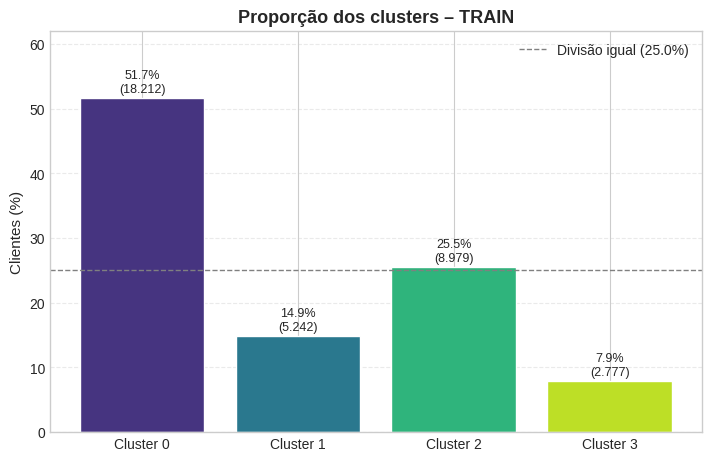

In [ ]:
# ============================================================
# A2.6.1 – Proporção dos clusters: conjunto TRAIN
# Requer: labels_train (A2.5)
# Define `proporcao_clusters`, reutilizada em validação e teste (A2.6.2 / A2.6.3)
# ============================================================
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def proporcao_clusters(labels, nome):
    labels = np.asarray(labels)
    cont = pd.Series(labels).value_counts().sort_index()
    tab = pd.DataFrame({"clientes": cont, "proporção (%)": cont / len(labels) * 100})
    tab.index.name = "cluster"
    tab.loc["Total"] = [len(labels), 100.0]

    print(f"PROPORÇÃO DOS CLUSTERS | {nome} | n = {len(labels):,}".replace(",", "."))
    display(tab.round(2))
    razao = cont.max() / cont.min()
    print(f"Maior cluster: {cont.idxmax()} ({cont.max()/len(labels)*100:.1f}%) | "
          f"menor cluster: {cont.idxmin()} ({cont.min()/len(labels)*100:.1f}%) | "
          f"razão maior/menor = {razao:.1f}x")

    cores = plt.cm.viridis(np.linspace(0.15, 0.9, len(cont)))
    fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
    barras = ax.bar([f"Cluster {c}" for c in cont.index], cont / len(labels) * 100,
                    color=cores, edgecolor="white")
    for b, n in zip(barras, cont.values):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.4,
                f"{b.get_height():.1f}%\n({n:,})".replace(",", "."), ha="center", va="bottom", fontsize=9)
    ax.axhline(100 / len(cont), color="gray", linestyle="--", linewidth=1,
               label=f"Divisão igual ({100/len(cont):.1f}%)")
    ax.set_ylim(0, (cont / len(labels) * 100).max() * 1.2)
    ax.set_ylabel("Clientes (%)"); ax.set_title(f"Proporção dos clusters – {nome}", fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.4); ax.legend()
    plt.show()
    return tab

prop_train = proporcao_clusters(labels_train, "TRAIN")

####Atividade A2.6.2: Medir a Proporção dos clusters: Conjunto VALIDATION

PROPORÇÃO DOS CLUSTERS | VALIDATION | n = 7.545


,clientes,proporção (%)
cluster,,
0,3898.0,51.66
1,1111.0,14.72
2,1931.0,25.59
3,605.0,8.02
Total,7545.0,100.00


Maior cluster: 0 (51.7%) | menor cluster: 3 (8.0%) | razão maior/menor = 6.4x


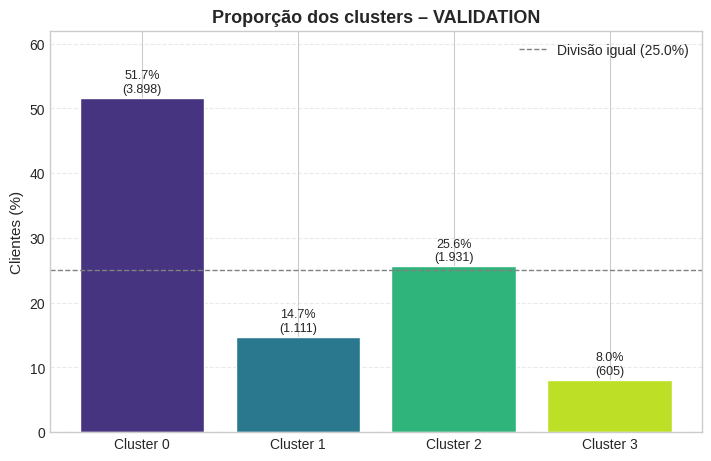


COMPARAÇÃO | treino x validação


,treino (%),validação (%),diferença (p.p.)
cluster,,,
0,51.72,51.66,-0.06
1,14.89,14.72,-0.16
2,25.50,25.59,0.09
3,7.89,8.02,0.13


Maior diferença absoluta: 0.16 p.p.


In [ ]:
# ============================================================
# A2.6.2 – Proporção dos clusters: conjunto VALIDATION
# Requer: labels_val (A2.5), proporcao_clusters e prop_train (A2.6.1)
# ============================================================
import pandas as pd

prop_val = proporcao_clusters(labels_val, "VALIDATION")

# Comparação com o treino
comp = pd.DataFrame({"treino (%)": prop_train["proporção (%)"],
                     "validação (%)": prop_val["proporção (%)"]}).drop(index="Total")
comp["diferença (p.p.)"] = comp["validação (%)"] - comp["treino (%)"]
print("\nCOMPARAÇÃO | treino x validação")
display(comp.round(2))
print(f"Maior diferença absoluta: {comp['diferença (p.p.)'].abs().max():.2f} p.p.")

####Atividade A2.6.3: Medir a Proporção dos clusters: Conjunto TEST

PROPORÇÃO DOS CLUSTERS | TEST | n = 7.545


,clientes,proporção (%)
cluster,,
0,3918.0,51.93
1,1109.0,14.70
2,1898.0,25.16
3,620.0,8.22
Total,7545.0,100.00


Maior cluster: 0 (51.9%) | menor cluster: 3 (8.2%) | razão maior/menor = 6.3x


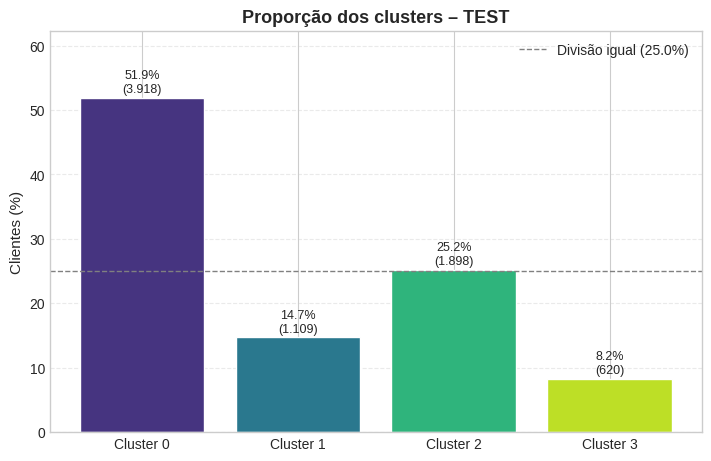


COMPARAÇÃO | treino x validação x teste


,treino (%),validação (%),teste (%),teste − treino (p.p.),teste − validação (p.p.)
cluster,,,,,
0,51.72,51.66,51.93,0.20,0.27
1,14.89,14.72,14.70,-0.19,-0.03
2,25.50,25.59,25.16,-0.35,-0.44
3,7.89,8.02,8.22,0.33,0.20


Maior diferença absoluta (teste x treino):    0.35 p.p.
Maior diferença absoluta (teste x validação): 0.44 p.p.


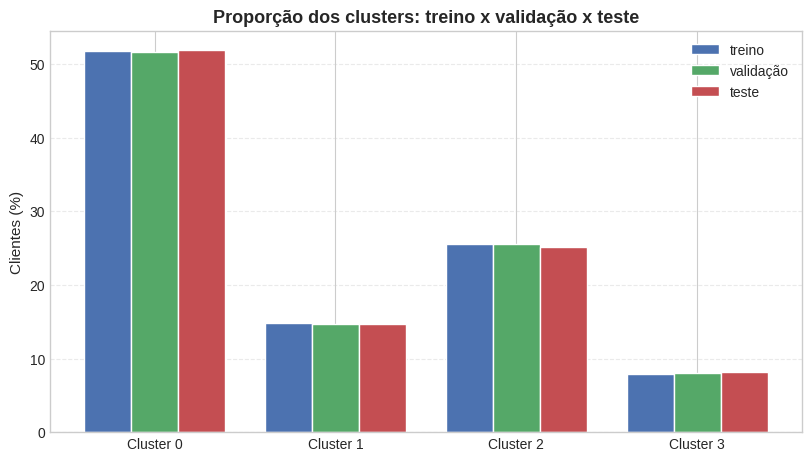

In [ ]:
# ============================================================
# A2.6.3 – Proporção dos clusters: conjunto TEST
# Requer: labels_test (A2.5), proporcao_clusters e prop_train (A2.6.1), prop_val (A2.6.2)
# ============================================================
import pandas as pd

prop_test = proporcao_clusters(labels_test, "TEST")

# Comparação entre os três conjuntos
comp = pd.DataFrame({"treino (%)": prop_train["proporção (%)"],
                     "validação (%)": prop_val["proporção (%)"],
                     "teste (%)": prop_test["proporção (%)"]}).drop(index="Total")
comp["teste − treino (p.p.)"] = comp["teste (%)"] - comp["treino (%)"]
comp["teste − validação (p.p.)"] = comp["teste (%)"] - comp["validação (%)"]
print("\nCOMPARAÇÃO | treino x validação x teste")
display(comp.round(2))
print(f"Maior diferença absoluta (teste x treino):    {comp['teste − treino (p.p.)'].abs().max():.2f} p.p.")
print(f"Maior diferença absoluta (teste x validação): {comp['teste − validação (p.p.)'].abs().max():.2f} p.p.")

# Gráfico comparativo
import matplotlib.pyplot as plt, numpy as np
x = np.arange(len(comp)); w = 0.26
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for i, (col, cor) in enumerate([("treino (%)", "#4C72B0"), ("validação (%)", "#55A868"), ("teste (%)", "#C44E52")]):
    ax.bar(x + (i - 1) * w, comp[col], w, label=col.replace(" (%)", ""), color=cor, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels([f"Cluster {c}" for c in comp.index])
ax.set_ylabel("Clientes (%)"); ax.set_title("Proporção dos clusters: treino x validação x teste", fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4); ax.legend()
plt.show()

##Atividade A2.7 (7º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

Amostra aleatória da população: 50.300 registros
PROPORÇÃO DOS CLUSTERS | POPULAÇÃO (amostra aleatória) | n = 50.300


,clientes,proporção (%)
cluster,,
0,33900.0,67.40
1,8883.0,17.66
2,5904.0,11.74
3,1613.0,3.21
Total,50300.0,100.00


Maior cluster: 0 (67.4%) | menor cluster: 3 (3.2%) | razão maior/menor = 21.0x


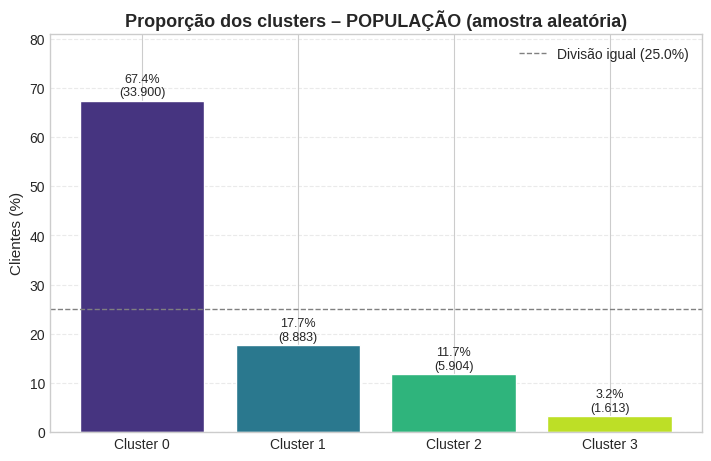


COMPARAÇÃO DAS PROPORÇÕES


,treino (%),validação (%),teste (%),população (%),população − treino (p.p.)
cluster,,,,,
0,51.72,51.66,51.93,67.40,15.67
1,14.89,14.72,14.70,17.66,2.77
2,25.50,25.59,25.16,11.74,-13.76
3,7.89,8.02,8.22,3.21,-4.68


Maior diferença absoluta (população x treino): 15.67 p.p.

MÉTRICAS | silhueta e inércia média


,n,inércia média por cliente,silhueta (amostra)
conjunto,,,
treino,35210,2.9459,0.2955
validação,7545,2.9079,0.2967
teste,7545,2.9363,0.3045
população,50300,2.5491,0.3249



Composição por TIPO DA CONTA em cada cluster (%) – população


tipo da conta,ESSENTIAL,PRIME,VIP
cluster,,,
0,72.6,2.3,25.2
1,68.9,5.9,25.3
2,8.4,82.4,9.2
3,0.0,100.0,0.0


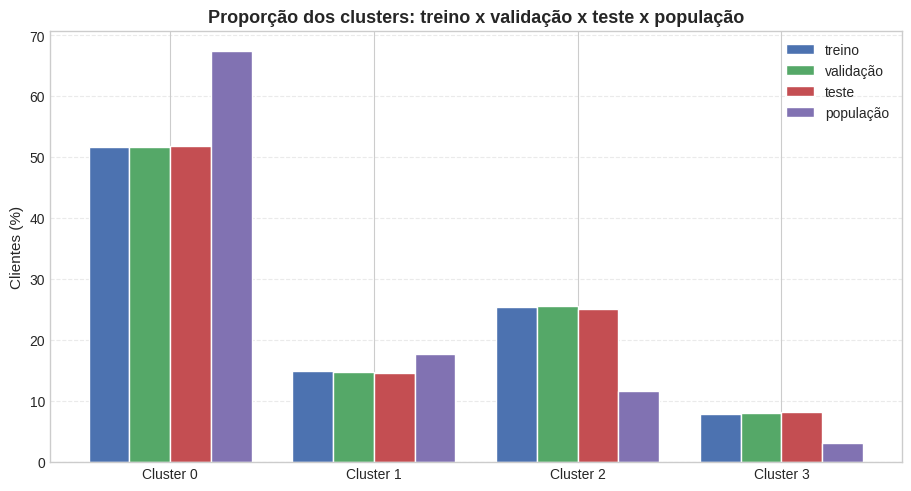

In [ ]:
# ==============================================================
# PARTE 2 | A2.7 (7º Passo): Testar o Modelo: Dados da População
#           amostra aleatória (Sample)
# Requer: table39, amostra_ideal (Load dos Datasets), preparar_cluster, scaler_extra,
#         cols_escala_extra, colunas_cluster (A2.1), modelo_km, labels_* (A2.5),
#         proporcao_clusters, prop_train/prop_val/prop_test (A2.6), tabela_metricas, nomes_tipo (A2.5)
# O modelo K-Means (ajustado no TRAIN) NÃO é reajustado aqui.
# ==============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 2026
N_POP = 50300            # mesmo tamanho da amostra estratificada
ESTRATO = "TIPO DA CONTA"

# --------------------------------------------------------------
# 1. Amostra aleatória SIMPLES da população (sem os registros já usados em train/val/test)
# --------------------------------------------------------------
populacao_disponivel = table39.drop(index=amostra_ideal.index)
amostra_pop = populacao_disponivel.sample(n=N_POP, random_state=SEED)

# Mesma preparação do A2.1 (inclui a padronização extra das ordinais/discretas)
Xc_pop_df = preparar_cluster(amostra_pop)
if len(cols_escala_extra):
    Xc_pop_df[cols_escala_extra] = scaler_extra.transform(Xc_pop_df[cols_escala_extra])
assert list(Xc_pop_df.columns) == list(colunas_cluster), "Colunas diferentes das do treino."
Xc_pop = Xc_pop_df.to_numpy(dtype=np.float64)
labels_pop = modelo_km.predict(Xc_pop)
yc_pop = amostra_pop[ESTRATO].to_numpy()          # só referência externa (nome do tipo)

print(f"Amostra aleatória da população: {N_POP:,} registros".replace(",", "."))

# --------------------------------------------------------------
# 2. Proporção dos clusters na população x treino/validação/teste
# --------------------------------------------------------------
prop_pop = proporcao_clusters(labels_pop, "POPULAÇÃO (amostra aleatória)")

comp = pd.DataFrame({"treino (%)": prop_train["proporção (%)"],
                     "validação (%)": prop_val["proporção (%)"],
                     "teste (%)": prop_test["proporção (%)"],
                     "população (%)": prop_pop["proporção (%)"]}).drop(index="Total")
comp["população − treino (p.p.)"] = comp["população (%)"] - comp["treino (%)"]
print("\nCOMPARAÇÃO DAS PROPORÇÕES")
display(comp.round(2))
print(f"Maior diferença absoluta (população x treino): "
      f"{comp['população − treino (p.p.)'].abs().max():.2f} p.p.")

# --------------------------------------------------------------
# 3. Qualidade do agrupamento: métricas em todos os conjuntos
# --------------------------------------------------------------
conj = [("treino", Xc_train, labels_train), ("validação", Xc_val, labels_val),
        ("teste", Xc_test, labels_test), ("população", Xc_pop, labels_pop)]
print("\nMÉTRICAS | silhueta e inércia média")
display(tabela_metricas(conj))

# --------------------------------------------------------------
# 4. Composição por TIPO DA CONTA em cada cluster (população)
# --------------------------------------------------------------
ct = pd.crosstab(pd.Series(labels_pop, name="cluster"),
                 pd.Series(yc_pop, name="tipo da conta"), normalize="index") * 100
print("\nComposição por TIPO DA CONTA em cada cluster (%) – população")
display(ct.round(1))

# --------------------------------------------------------------
# 5. Gráfico comparativo das proporções
# --------------------------------------------------------------
x = np.arange(len(comp)); w = 0.2
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
for i, (col, cor) in enumerate([("treino (%)", "#4C72B0"), ("validação (%)", "#55A868"),
                                ("teste (%)", "#C44E52"), ("população (%)", "#8172B2")]):
    ax.bar(x + (i - 1.5) * w, comp[col], w, label=col.replace(" (%)", ""), color=cor, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels([f"Cluster {c}" for c in comp.index])
ax.set_ylabel("Clientes (%)")
ax.set_title("Proporção dos clusters: treino x validação x teste x população", fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4); ax.legend()
plt.show()

In [ ]:
# ==============================================================
# A2.7.1 – Verificação: as proporções da população são explicadas pela mistura de estratos?
# Reponderamos os clusters do TREINO pelos pesos reais dos tipos de conta (base completa)
# e comparamos com o que o modelo encontrou na amostra aleatória da população.
# Requer: table39, labels_train, yc_train, labels_pop, nomes_tipo (A2.5), A2.7
# ==============================================================
import numpy as np, pandas as pd

ESTRATO = "TIPO DA CONTA"
tipo_train = pd.Series(np.asarray(yc_train)).map(nomes_tipo).to_numpy()

# 1) Mistura de estratos: amostra Neyman (treino) x população real
mist = pd.DataFrame({"treino (Neyman)": pd.Series(tipo_train).value_counts(normalize=True),
                     "população (base completa)": table39[ESTRATO].value_counts(normalize=True)}).mul(100)
print("MISTURA DE TIPOS DE CONTA (%)")
display(mist.round(1))

# 2) Distribuição de clusters DENTRO de cada tipo de conta (treino)
dist = pd.crosstab(pd.Series(tipo_train, name=ESTRATO),
                   pd.Series(labels_train, name="cluster"), normalize="index")
print("\nCLUSTERS DENTRO DE CADA TIPO DE CONTA – treino (%)")
display((dist * 100).round(1))

# 3) Reponderação pelos pesos reais
pesos = table39[ESTRATO].value_counts(normalize=True).reindex(dist.index)
prop_repond = (dist.mul(pesos, axis=0)).sum() * 100
prop_obs = pd.Series(labels_pop).value_counts(normalize=True).sort_index() * 100
cmp_ = pd.DataFrame({"treino (bruto, %)": pd.Series(labels_train).value_counts(normalize=True).sort_index() * 100,
                     "treino reponderado (%)": prop_repond,
                     "população observada (%)": prop_obs})
cmp_["observada − reponderada (p.p.)"] = cmp_["população observada (%)"] - cmp_["treino reponderado (%)"]
cmp_.index.name = "cluster"
print("\nPROPORÇÃO DOS CLUSTERS: bruta x reponderada x observada")
display(cmp_.round(2))
print(f"Maior diferença (observada x reponderada): "
      f"{cmp_['observada − reponderada (p.p.)'].abs().max():.2f} p.p.  "
      f"| (bruto x observada: {(cmp_['população observada (%)'] - cmp_['treino (bruto, %)']).abs().max():.2f} p.p.)")

MISTURA DE TIPOS DE CONTA (%)


,treino (Neyman),população (base completa)
ESSENTIAL,39.9,61.0
PRIME,37.6,16.4
VIP,22.5,22.6



CLUSTERS DENTRO DE CADA TIPO DE CONTA – treino (%)


cluster,0,1,2,3
TIPO DA CONTA,,,,
ESSENTIAL,78.5,19.8,1.6,0.0
PRIME,9.2,6.3,63.5,21.0
VIP,75.1,20.4,4.5,0.0



PROPORÇÃO DOS CLUSTERS: bruta x reponderada x observada


,"treino (bruto, %)",treino reponderado (%),população observada (%),observada − reponderada (p.p.)
cluster,,,,
0,51.72,66.40,67.40,0.99
1,14.89,17.76,17.66,-0.10
2,25.50,12.40,11.74,-0.66
3,7.89,3.44,3.21,-0.23


Maior diferença (observada x reponderada): 0.99 p.p.  | (bruto x observada: 15.67 p.p.)


Amostra estratificada da população: 50.300 registros


,proporção (%)
TIPO DA CONTA,
ESSENTIAL,39.91
PRIME,37.57
VIP,22.52


PROPORÇÃO DOS CLUSTERS | POPULAÇÃO ESTRATIFICADA (mesma composição do teste) | n = 50.300


,clientes,proporção (%)
cluster,,
0,26048.0,51.79
1,7423.0,14.76
2,12831.0,25.51
3,3998.0,7.95
Total,50300.0,100.00


Maior cluster: 0 (51.8%) | menor cluster: 3 (7.9%) | razão maior/menor = 6.5x


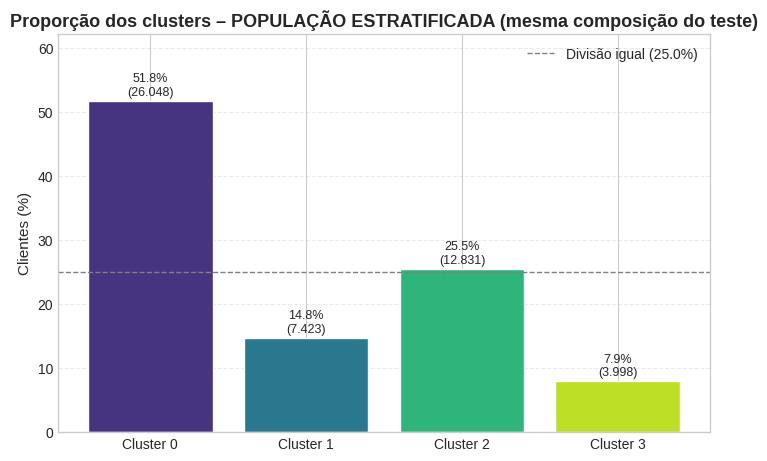


COMPARAÇÃO DAS PROPORÇÕES


,treino (%),validação (%),teste (%),população estratificada (%),pop. estrat. − teste (p.p.)
cluster,,,,,
0,51.72,51.66,51.93,51.79,-0.14
1,14.89,14.72,14.70,14.76,0.06
2,25.50,25.59,25.16,25.51,0.35
3,7.89,8.02,8.22,7.95,-0.27


Maior diferença absoluta (população estratificada x teste): 0.35 p.p.

MÉTRICAS | silhueta e inércia média


,n,inércia média por cliente,silhueta (amostra)
conjunto,,,
treino,35210,2.9459,0.2955
validação,7545,2.9079,0.2967
teste,7545,2.9363,0.3045
pop. estratificada,50300,2.9329,0.2977


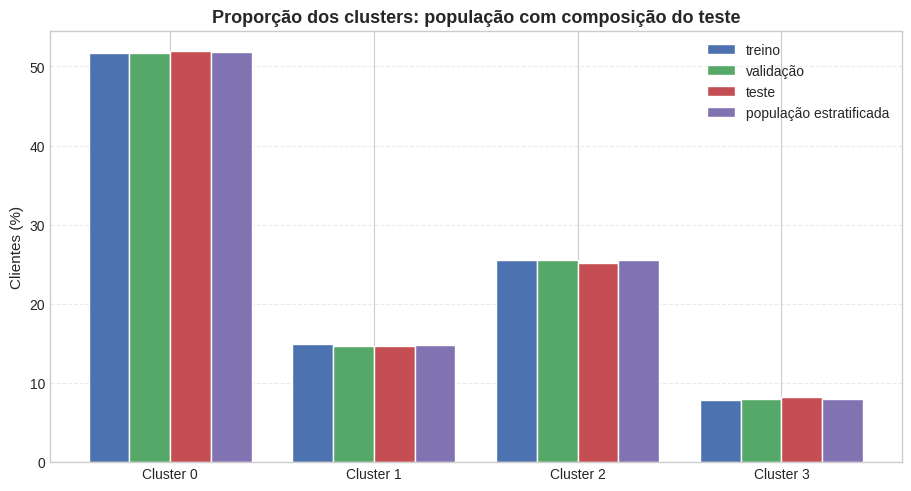

In [ ]:
# ==============================================================
# A2.7.2 – População com a MESMA composição de tipos de conta do treino/validação/teste
# Complementa a A2.7 (amostra aleatória simples): aqui o sorteio na população segue a
# alocação de Neyman, então as proporções dos clusters são comparáveis às do teste.
# Requer: table39, amostra_ideal, preparar_cluster, scaler_extra, cols_escala_extra,
#         colunas_cluster, modelo_km (A2.5), proporcao_clusters, prop_train/val/test (A2.6),
#         tabela_metricas, Xc_train/val/test e labels_* (A2.5)
# ==============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt

SEED = 2027
ESTRATO = "TIPO DA CONTA"

# 1) Sorteio estratificado: mesmas contagens por tipo de conta da amostra_ideal,
#    sem reutilizar registros de train/val/test nem os da A2.7
contagens = amostra_ideal[ESTRATO].value_counts()
pool = table39.drop(index=amostra_ideal.index)
if "amostra_pop" in globals():
    pool = pool.drop(index=amostra_pop.index)
_disp = pool[ESTRATO].value_counts()
assert all(_disp.get(t, 0) >= n for t, n in contagens.items()), "Registros insuficientes em algum tipo de conta."
amostra_pop_estr = pd.concat([pool[pool[ESTRATO] == t].sample(n=int(n), random_state=SEED)
                              for t, n in contagens.items()])
print(f"Amostra estratificada da população: {len(amostra_pop_estr):,} registros".replace(",", "."))
display((amostra_pop_estr[ESTRATO].value_counts(normalize=True) * 100).round(2).to_frame("proporção (%)"))

# 2) Preparação e atribuição de clusters (modelo NÃO reajustado)
X_df = preparar_cluster(amostra_pop_estr)
if len(cols_escala_extra):
    X_df[cols_escala_extra] = scaler_extra.transform(X_df[cols_escala_extra])
assert list(X_df.columns) == list(colunas_cluster)
Xc_pop_e = X_df.to_numpy(dtype=np.float64)
labels_pop_e = modelo_km.predict(Xc_pop_e)

# 3) Proporções e comparação
prop_pop_e = proporcao_clusters(labels_pop_e, "POPULAÇÃO ESTRATIFICADA (mesma composição do teste)")
comp = pd.DataFrame({"treino (%)": prop_train["proporção (%)"], "validação (%)": prop_val["proporção (%)"],
                     "teste (%)": prop_test["proporção (%)"],
                     "população estratificada (%)": prop_pop_e["proporção (%)"]}).drop(index="Total")
comp["pop. estrat. − teste (p.p.)"] = comp["população estratificada (%)"] - comp["teste (%)"]
print("\nCOMPARAÇÃO DAS PROPORÇÕES")
display(comp.round(2))
print(f"Maior diferença absoluta (população estratificada x teste): "
      f"{comp['pop. estrat. − teste (p.p.)'].abs().max():.2f} p.p.")

# 4) Métricas
print("\nMÉTRICAS | silhueta e inércia média")
display(tabela_metricas([("treino", Xc_train, labels_train), ("validação", Xc_val, labels_val),
                         ("teste", Xc_test, labels_test), ("pop. estratificada", Xc_pop_e, labels_pop_e)]))

# 5) Gráfico
x = np.arange(len(comp)); w = 0.2
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
for i, (c, cor) in enumerate([("treino (%)", "#4C72B0"), ("validação (%)", "#55A868"),
                              ("teste (%)", "#C44E52"), ("população estratificada (%)", "#8172B2")]):
    ax.bar(x + (i - 1.5) * w, comp[c], w, label=c.replace(" (%)", ""), color=cor, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels([f"Cluster {k}" for k in comp.index]); ax.set_ylabel("Clientes (%)")
ax.set_title("Proporção dos clusters: população com composição do teste", fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4); ax.legend(); plt.show()

## RELATÓRIO PARCIAL - MODELO DE CLUSTERIZAÇÃO

Fazer aqui o **RELATÓRIO PARCIAL - MODELO DE CLUSTERIZAÇÃO** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

Objetivo. Agrupar os clientes do UWine em perfis semelhantes, para que a empresa conheça melhor sua base e possa direcionar ações a cada grupo.

Como foi feito. Usamos o K-Means, técnica que reúne clientes parecidos em grupos, com base em 12 variáveis de perfil e de compra, como renda, valor gasto, satisfação, região e estado civil. Retiramos as medidas físico-químicas dos vinhos, que só atrapalhavam a separação dos grupos, e também o tipo de conta, para poder verificar depois se o modelo o reconhecia sozinho. O método do cotovelo indicou 4 grupos. A silhueta, que mede quão bem separados os grupos estão, deu o valor máximo com 2 grupos, mas a diferença para 4 grupos é pequena (0,34 contra 0,30) e dois grupos seriam pouco úteis para a empresa. Por isso adotamos 4 grupos.

Qualidade e estabilidade. A silhueta ficou em 0,30, valor razoável, em treino, validação e teste (0,296, 0,297 e 0,305). A distribuição dos clientes entre os grupos praticamente não muda entre esses conjuntos: a maior diferença é de apenas 0,4 ponto percentual. Isso mostra que o modelo funciona do mesmo jeito com clientes que ele não viu durante o ajuste.

Teste na base real. Aplicamos o modelo a uma amostra aleatória de 50.300 clientes da base, e a silhueta foi de 0,32, mantendo a qualidade. As proporções dos grupos são diferentes das do treino (o grupo 0 passa de 52% para 67%), mas isso acontece porque a amostra de treino tem mais clientes PRIME (38%) do que a base real (16%). Ao ajustar esse peso, a diferença cai para cerca de 1 ponto percentual, e ao sortear a população com a mesma composição do teste, as proporções ficam praticamente iguais.

O que os grupos mostram. O modelo separa os clientes PRIME dos demais, mesmo sem saber o tipo de conta. Os grupos 2 e 3 reúnem quase só clientes PRIME (94% e 100%) e representam cerca de 15% da base. Os grupos 0 e 1, que somam cerca de 85%, misturam clientes ESSENTIAL e VIP, ou seja, esses dois tipos têm perfis parecidos e o modelo não os distingue.

Limitações e próximos passos. A separação entre os grupos é moderada, com alguma sobreposição entre eles, então os perfis devem ser lidos como tendências, e não como categorias rígidas. O passo seguinte é descrever cada grupo em termos de renda, gasto e satisfação, para transformar os grupos em ações práticas para a empresa.

#Atividade A3: Modelo de Classificação

##Atividade A3.1 (1º Passo): Normalizar - Mapear - Discretizar

In [ ]:
# ==============================================================
# PARTE 2 | Atividade A3.1 (1º Passo): Normalizar - Mapear - Discretizar
#           Modelo de CLASSIFICAÇÃO | classe (alvo): TIPO DA CONTA
# Requer: train, validation, test (Load dos Datasets) e `preparar`, MAPA_CONTA, ALVO (A1.1)
# Entradas (X): preparação da regressão (parâmetros definidos SOMENTE no treino), com 2 ajustes:
#   - TIPO_CONTA_ORD sai (é o próprio alvo -> vazamento);
#   - TOTAL (R$) entra como entrada (z-score do treino), pois agora não é o alvo.
# ==============================================================
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

INCLUIR_MEAN_VINHO = False   # 13 variáveis "MEAN:" (físico-químicas); ruído na A2 -> False
COL_CLASSE = "TIPO DA CONTA"

# --------------------------------------------------------------
# 1. Classe (y): TIPO DA CONTA -> 0 = ESSENTIAL, 1 = VIP, 2 = PRIME
# --------------------------------------------------------------
CLASSES = [c for c, _ in sorted(MAPA_CONTA.items(), key=lambda kv: kv[1])]
ya_train = train[COL_CLASSE].map(MAPA_CONTA).to_numpy()
ya_val = validation[COL_CLASSE].map(MAPA_CONTA).to_numpy()
ya_test = test[COL_CLASSE].map(MAPA_CONTA).to_numpy()
for nome, y in [("train", ya_train), ("validation", ya_val), ("test", ya_test)]:
    assert not pd.isna(y).any(), f"{nome}: TIPO DA CONTA fora do mapa."

# --------------------------------------------------------------
# 2. Entradas (X)
# --------------------------------------------------------------
scaler_total = StandardScaler().fit(train[[ALVO]])          # TOTAL (R$) como entrada

def preparar_clf(df):
    X, _ = preparar(df)                                     # mesma preparação da A1.1
    X = X.drop(columns=["TIPO_CONTA_ORD"], errors="ignore") # remove o alvo das entradas
    if not INCLUIR_MEAN_VINHO:
        X = X.drop(columns=[c for c in X.columns if c.startswith("MEAN:")])
    X["TOTAL_R$"] = scaler_total.transform(df[[ALVO]]).ravel()
    return X

Xa_train, Xa_val, Xa_test = preparar_clf(train), preparar_clf(validation), preparar_clf(test)
colunas_Xa = list(Xa_train.columns)
assert "TIPO_CONTA_ORD" not in colunas_Xa and not any("TIPO" in c.upper() and "CONTA" in c.upper() for c in colunas_Xa), \
    "O alvo não pode estar entre as entradas."
assert not Xa_train.isna().any().any() and not Xa_val.isna().any().any() and not Xa_test.isna().any().any()

# --------------------------------------------------------------
# 3. Relatório
# --------------------------------------------------------------
print(f"Xa_train: {Xa_train.shape} | Xa_val: {Xa_val.shape} | Xa_test: {Xa_test.shape}")
print(f"Variáveis de entrada ({len(colunas_Xa)}): {colunas_Xa}\n")

dist = pd.DataFrame({n: pd.Series(y).value_counts(normalize=True).sort_index()
                     for n, y in [("treino", ya_train), ("validação", ya_val), ("teste", ya_test)]}).mul(100)
dist.index = CLASSES
dist.index.name = "classe"
print("DISTRIBUIÇÃO DAS CLASSES (%):")
display(dist.round(1))

print("\nMédia de TOTAL (R$) e de RENDA por classe no treino (referência):")
cols_ref = [c for c in [ALVO, "RENDA"] if c in train.columns]
display(train.groupby(COL_CLASSE)[cols_ref].mean().loc[CLASSES].round(2))

Xa_train: (35210, 12) | Xa_val: (7545, 12) | Xa_test: (7545, 12)
Variáveis de entrada (12): ['DEPENDENTES', 'RENDA BRUTO (R$)', 'NOTA DE SATISFAÇÃO (%)', 'SEXO_FEMININO', 'REGIÃO_NORDESTE', 'REGIÃO_NORTE', 'REGIÃO_SUDESTE', 'REGIÃO_SUL', 'ESTADO_CIVIL_DESQUITADO(A) / VIÚVO(A)', 'ESTADO_CIVIL_SOLTEIRO', 'NIVEL_SATISFACAO', 'TOTAL_R$']

DISTRIBUIÇÃO DAS CLASSES (%):


,treino,validação,teste
classe,,,
ESSENTIAL,39.9,39.9,39.9
VIP,22.5,22.5,22.5
PRIME,37.6,37.6,37.6



Média de TOTAL (R$) e de RENDA por classe no treino (referência):


,TOTAL (R$)
TIPO DA CONTA,
ESSENTIAL,402.76
VIP,910.58
PRIME,2192.90


##Atividade A3.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [ ]:
# ==============================================================
# PARTE 2 | Atividade A3.2 (2º Passo) - ETL: Separar Entrada (X) da Saída (y)
# Requer: Xa_train, Xa_val, Xa_test, ya_train, ya_val, ya_test, CLASSES (A3.1)
# A partir daqui temos apenas NDARRAY: train - validation - test
# ==============================================================
import numpy as np

# Nomes das variáveis de entrada (guardados antes da conversão, para interpretar o modelo)
colunas_Xa = list(Xa_train.columns) if hasattr(Xa_train, "columns") else colunas_Xa
nome_ya = "TIPO DA CONTA"

# --------------------------------------------------------------
# DataFrame/Series -> ndarray (pode ser reexecutada sem erro)
#   X: matriz 2D float (n_amostras, n_variáveis) | y: vetor 1D inteiro (0, 1, 2)
# --------------------------------------------------------------
Xa_train, Xa_val, Xa_test = (np.asarray(X, dtype=np.float64) for X in (Xa_train, Xa_val, Xa_test))
ya_train, ya_val, ya_test = (np.asarray(y, dtype=np.int64) for y in (ya_train, ya_val, ya_test))

# --------------------------------------------------------------
# Verificações de integridade
# --------------------------------------------------------------
for nome, X, y in [("train", Xa_train, ya_train), ("validation", Xa_val, ya_val), ("test", Xa_test, ya_test)]:
    assert isinstance(X, np.ndarray) and isinstance(y, np.ndarray)
    assert X.ndim == 2 and y.ndim == 1
    assert X.shape[0] == y.shape[0], f"{nome}: X e y com tamanhos diferentes"
    assert X.shape[1] == len(colunas_Xa)
    assert np.isfinite(X).all(), f"{nome}: há NaN/inf em X"
    assert set(np.unique(y)) <= set(range(len(CLASSES))), f"{nome}: classe inesperada em y"

# --------------------------------------------------------------
# Relatório
# --------------------------------------------------------------
print(f"{'conjunto':<12}{'X (shape)':<18}{'y (shape)':<14}{'X dtype':<10}{'y dtype'}")
for nome, X, y in [("train", Xa_train, ya_train), ("validation", Xa_val, ya_val), ("test", Xa_test, ya_test)]:
    print(f"{nome:<12}{str(X.shape):<18}{str(y.shape):<14}{str(X.dtype):<10}{y.dtype}")

print(f"\nClasses (y): {dict(enumerate(CLASSES))}")
print(f"Variáveis de entrada ({len(colunas_Xa)}): {colunas_Xa}")
print("\nClasses no treino (contagem):",
      {CLASSES[k]: int(n) for k, n in zip(*np.unique(ya_train, return_counts=True))})


conjunto    X (shape)         y (shape)     X dtype   y dtype
train       (35210, 12)       (35210,)      float64   int64
validation  (7545, 12)        (7545,)       float64   int64
test        (7545, 12)        (7545,)       float64   int64

Classes (y): {0: 'ESSENTIAL', 1: 'VIP', 2: 'PRIME'}
Variáveis de entrada (12): ['DEPENDENTES', 'RENDA BRUTO (R$)', 'NOTA DE SATISFAÇÃO (%)', 'SEXO_FEMININO', 'REGIÃO_NORDESTE', 'REGIÃO_NORTE', 'REGIÃO_SUDESTE', 'REGIÃO_SUL', 'ESTADO_CIVIL_DESQUITADO(A) / VIÚVO(A)', 'ESTADO_CIVIL_SOLTEIRO', 'NIVEL_SATISFACAO', 'TOTAL_R$']

Classes no treino (contagem): {'ESSENTIAL': 14051, 'VIP': 7929, 'PRIME': 13230}


##Atividade A3.3 (3º Passo): Escolher / Criar o Modelo: **Classifiers**

Escolher enter os seguintes - **Classifiers**:

1.   Nearest Neighbors
2.   Linear SVM
2.   RBF SVM
2.   Gaussian Process
2.   Decision Tree
2.   Random Forest
2.   Neural Net
2.   AdaBoost
2.   Naive Bayes
2.   QDA

**Qual obteve o maior SCORE ?**

  Baseline (classe mais frequente)   ok (0.0 s)
  Nearest Neighbors                  ok (28.8 s)
  Linear SVM                         ok (0.7 s)
  RBF SVM                            ok (11.3 s)
  Gaussian Process                   ok (89.1 s)
  Decision Tree                      ok (0.2 s)
  Random Forest                      ok (6.6 s)
  Neural Net                         ok (14.1 s)
  AdaBoost                           ok (7.5 s)
  Naive Bayes                        ok (0.0 s)
  QDA                                ok (0.1 s)

DESEMPENHO DOS CLASSIFICADORES (ordenado pelo SCORE na validação)


,SCORE treino,SCORE validação,F1 macro (val),acurácia balanceada (val),treino com (n),tempo (s),gap treino-val
modelo,,,,,,,
AdaBoost,0.9459,0.9475,0.9429,0.9374,35210,7.4836,-0.0016
Decision Tree,0.9490,0.9450,0.9403,0.9349,35210,0.1656,0.0040
Random Forest,0.9562,0.9431,0.9377,0.9356,35210,6.5775,0.0130
Neural Net,0.9416,0.9400,0.9361,0.9320,35210,14.1141,0.0016
RBF SVM,0.9274,0.9256,0.9192,0.9244,12000,11.2830,0.0017
Gaussian Process,0.9271,0.9246,0.9185,0.9220,3000,89.1345,0.0025
Nearest Neighbors,0.9259,0.9201,0.9124,0.9118,35210,28.8339,0.0059
QDA,0.8452,0.8387,0.8070,0.7981,35210,0.0575,0.0065
Linear SVM,0.8287,0.8252,0.7731,0.7654,35210,0.7109,0.0035



Maior SCORE na validação: AdaBoost (acurácia = 0.9475 | F1 macro = 0.9429)
Baseline (sempre a classe mais frequente): 0.3991
Atenção: os dois primeiros estão separados por menos de 0,5 p.p.; considere critérios de desempate (F1 macro, gap treino-val, tempo).


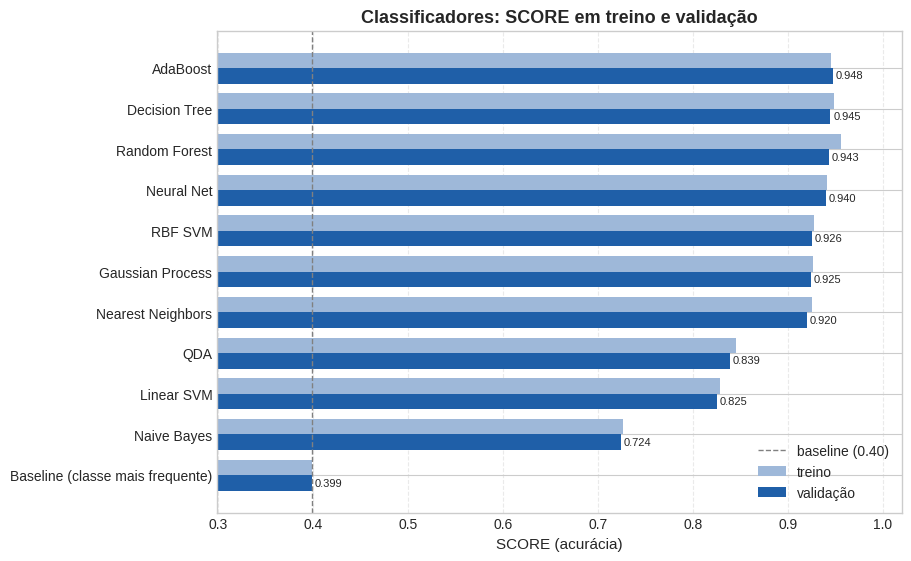

In [ ]:
# ==============================================================
# PARTE 2 | Atividade A3.3 (3º Passo): Escolher / Criar o Modelo: Classifiers
# Requer: Xa_train, Xa_val, ya_train, ya_val (A3.2), CLASSES (A3.1)
# Todos os modelos são ajustados no TREINO e avaliados na VALIDAÇÃO.
# SCORE = acurácia. Também reportamos F1 macro e acurácia balanceada,
# porque as classes não são equilibradas (ESSENTIAL ~40%, VIP ~22%, PRIME ~38%).
# ==============================================================
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

SEED = 42
# Modelos de custo O(n²)/O(n³): treinados em subamostra ESTRATIFICADA do treino
N_SUB_GP = 3000      # Gaussian Process (custo O(n³): inviável com 35 mil linhas)
N_SUB_SVM = 12000    # RBF SVM
SUBAMOSTRADOS = {"Gaussian Process": N_SUB_GP, "RBF SVM": N_SUB_SVM}

def subamostra(X, y, n, seed=SEED):
    if n >= len(X):
        return X, y
    rng = np.random.default_rng(seed)
    idx = np.concatenate([rng.choice(np.where(y == c)[0], size=round(n * (y == c).mean()), replace=False)
                          for c in np.unique(y)])
    return X[idx], y[idx]

classifiers = {
    "Baseline (classe mais frequente)": DummyClassifier(strategy="most_frequent"),
    "Nearest Neighbors":  KNeighborsClassifier(n_neighbors=15),
    "Linear SVM":         LinearSVC(C=0.1, dual=False, max_iter=5000, random_state=SEED),
    "RBF SVM":            SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED),
    "Gaussian Process":   GaussianProcessClassifier(kernel=1.0 * RBF(1.0), optimizer=None, n_jobs=-1,
                                                  random_state=SEED),  # kernel fixo: sem otimização (rápido e estável),
    "Decision Tree":      DecisionTreeClassifier(max_depth=8, random_state=SEED),
    "Random Forest":      RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1, random_state=SEED),
    "Neural Net":         MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True,
                                        max_iter=300, random_state=SEED),
    "AdaBoost":           AdaBoostClassifier(n_estimators=200, random_state=SEED),
    "Naive Bayes":        GaussianNB(),
    "QDA":                QuadraticDiscriminantAnalysis(reg_param=0.1),   # reg: variáveis dummy são colineares
}

linhas, y_pred_val = [], {}
for nome, clf in classifiers.items():
    Xf, yf = subamostra(Xa_train, ya_train, SUBAMOSTRADOS.get(nome, len(Xa_train)))
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        clf.fit(Xf, yf)
        pred_tr, pred_val = clf.predict(Xa_train), clf.predict(Xa_val)
    y_pred_val[nome] = pred_val
    linhas.append({"modelo": nome,
                   "SCORE treino": accuracy_score(ya_train, pred_tr),
                   "SCORE validação": accuracy_score(ya_val, pred_val),
                   "F1 macro (val)": f1_score(ya_val, pred_val, average="macro"),
                   "acurácia balanceada (val)": balanced_accuracy_score(ya_val, pred_val),
                   "treino com (n)": len(Xf),
                   "tempo (s)": time.perf_counter() - t0})
    print(f"  {nome:<34} ok ({linhas[-1]['tempo (s)']:.1f} s)")

desempenho = (pd.DataFrame(linhas).set_index("modelo")
              .sort_values("SCORE validação", ascending=False))
desempenho["gap treino-val"] = desempenho["SCORE treino"] - desempenho["SCORE validação"]
print("\nDESEMPENHO DOS CLASSIFICADORES (ordenado pelo SCORE na validação)")
display(desempenho.round(4))

validos = desempenho.drop(index="Baseline (classe mais frequente)")
melhor = validos["SCORE validação"].idxmax()
print(f"\nMaior SCORE na validação: {melhor} "
      f"(acurácia = {validos.loc[melhor, 'SCORE validação']:.4f} | "
      f"F1 macro = {validos.loc[melhor, 'F1 macro (val)']:.4f})")
base = desempenho.loc["Baseline (classe mais frequente)", "SCORE validação"]
print(f"Baseline (sempre a classe mais frequente): {base:.4f}")
if validos["SCORE validação"].nlargest(2).diff().abs().iloc[-1] < 0.005:
    print("Atenção: os dois primeiros estão separados por menos de 0,5 p.p.; considere critérios de desempate (F1 macro, gap treino-val, tempo).")

# --------------------------------------------------------------
# Gráfico: SCORE de treino x validação
# --------------------------------------------------------------
d = desempenho.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
y = np.arange(len(d)); h = 0.38
ax.barh(y + h / 2, d["SCORE treino"], h, label="treino", color="#9EB8D9")
ax.barh(y - h / 2, d["SCORE validação"], h, label="validação", color="#1F5FA8")
for yi, v in zip(y - h / 2, d["SCORE validação"]):
    ax.text(v + 0.003, yi, f"{v:.3f}", va="center", fontsize=8)
ax.axvline(base, color="gray", linestyle="--", linewidth=1, label=f"baseline ({base:.2f})")
ax.set_yticks(y); ax.set_yticklabels(d.index); ax.set_xlim(max(0, d["SCORE validação"].min() - 0.1), 1.02)
ax.set_xlabel("SCORE (acurácia)"); ax.set_title("Classificadores: SCORE em treino e validação", fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.4); ax.legend(loc="lower right")
plt.show()

### A3.3.1: Intervalo de confiança: Train

VALIDAÇÃO CRUZADA (10 folds) | AdaBoost


,Acurácia (SCORE),F1 macro,Acurácia balanceada
Fold,,,
1,0.9455,0.9413,0.9367
2,0.9432,0.9386,0.9330
3,0.9469,0.9415,0.9351
4,0.9480,0.9452,0.9409
5,0.9466,0.9431,0.9373
6,0.9429,0.9395,0.9356
7,0.9486,0.9449,0.9395
8,0.9432,0.9399,0.9358
9,0.9438,0.9392,0.9331



INTERVALOS DE CONFIANÇA (95%) | TRAIN


,CV média,CV desvio (folds),CV IC inferior,CV IC superior,Boot erro-padrão,Boot IC inferior,Boot IC superior
Acurácia (SCORE),0.9458,0.0024,0.9441,0.9474,0.0012,0.9434,0.9481
F1 macro,0.9418,0.0026,0.9400,0.9437,0.0013,0.9393,0.9444
Acurácia balanceada,0.9368,0.0029,0.9347,0.9389,0.0014,0.9341,0.9396



MATRIZ DE CONFUSÃO (% de cada classe real) | previsões out-of-fold


,prev. ESSENTIAL,prev. VIP,prev. PRIME
real ESSENTIAL,95.3,0.5,4.3
real VIP,0.4,88.0,11.6
real PRIME,0.6,1.6,97.8



IMPORTÂNCIA DAS VARIÁVEIS | média e IC 95% entre os 10 folds


,importância (média),IC inferior,IC superior
RENDA BRUTO (R$),0.7973,0.7839,0.8106
NOTA DE SATISFAÇÃO (%),0.2027,0.1894,0.2161
DEPENDENTES,0.0000,0.0000,0.0000
SEXO_FEMININO,0.0000,0.0000,0.0000
REGIÃO_NORDESTE,0.0000,0.0000,0.0000
REGIÃO_NORTE,0.0000,0.0000,0.0000
REGIÃO_SUDESTE,0.0000,0.0000,0.0000
REGIÃO_SUL,0.0000,0.0000,0.0000
ESTADO_CIVIL_DESQUITADO(A) / VIÚVO(A),0.0000,0.0000,0.0000
ESTADO_CIVIL_SOLTEIRO,0.0000,0.0000,0.0000


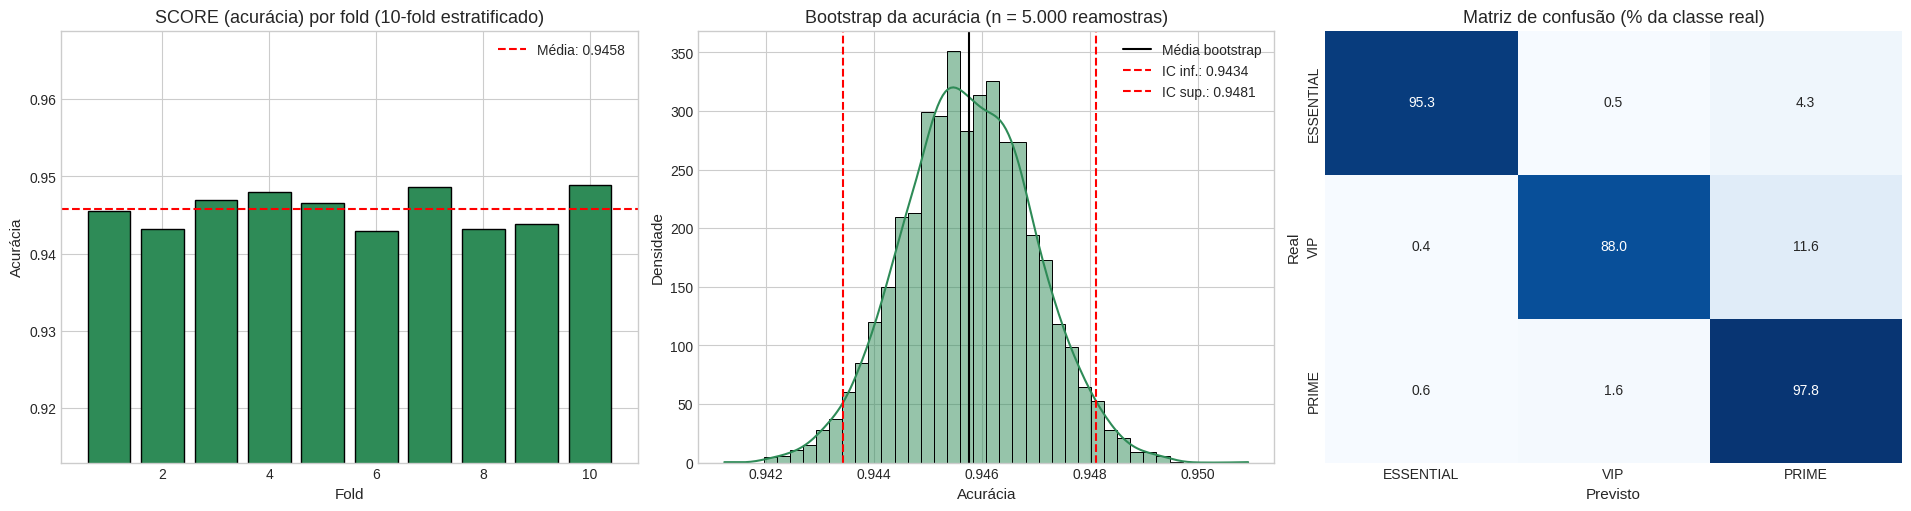

In [ ]:
# ==============================================================
# PARTE 2 | A3.3.1: Intervalo de confiança: Train
# Validação Cruzada e Análise Bootstrapping (modelo escolhido: AdaBoost)
# Requer: Xa_train, ya_train, colunas_Xa (A3.2), CLASSES (A3.1) e classifiers (A3.3)
# Usa SOMENTE o conjunto de treino; validation e test não são tocados
# ==============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix

SEED = 42
K = 10                   # folds da validação cruzada
N_BOOT = 5000            # reamostragens bootstrap das métricas
NIVEL = 0.95
ALFA = 1 - NIVEL
MODELO_ESCOLHIDO = "AdaBoost"

modelo = classifiers[MODELO_ESCOLHIDO]
nc = len(CLASSES)
n = len(ya_train)
rng = np.random.default_rng(SEED)
NOMES = ["Acurácia (SCORE)", "F1 macro", "Acurácia balanceada"]

def metricas_conf(C):
    """Métricas a partir da matriz de confusão (linhas = real, colunas = previsto)."""
    diag = np.diag(C).astype(float)
    rec = diag / np.maximum(C.sum(axis=1), 1)
    prec = diag / np.maximum(C.sum(axis=0), 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0.0)
    return np.array([diag.sum() / C.sum(), f1.mean(), rec.mean()])

def conf(y, p):
    return np.bincount(y * nc + p, minlength=nc * nc).reshape(nc, nc)

# --------------------------------------------------------------
# 1. VALIDAÇÃO CRUZADA (K-Fold estratificado pela CLASSE)
# --------------------------------------------------------------
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
linhas_fold, oof = [], np.empty(n, dtype=int)
imp_folds = []
for k, (idx_tr, idx_te) in enumerate(skf.split(Xa_train, ya_train), start=1):
    m = clone(modelo).fit(Xa_train[idx_tr], ya_train[idx_tr])
    oof[idx_te] = m.predict(Xa_train[idx_te])
    imp_folds.append(m.feature_importances_)
    linhas_fold.append(dict(zip(["Fold"] + NOMES,
                                [k, *metricas_conf(conf(ya_train[idx_te], oof[idx_te]))])))
cv = pd.DataFrame(linhas_fold).set_index("Fold")
print(f"VALIDAÇÃO CRUZADA ({K} folds) | {MODELO_ESCOLHIDO}")
display(cv.round(4))

# --------------------------------------------------------------
# 2. BOOTSTRAP das métricas (reamostra as previsões out-of-fold)
# --------------------------------------------------------------
boot = np.empty((N_BOOT, 3))
for b in range(N_BOOT):
    i = rng.integers(0, n, n)
    boot[b] = metricas_conf(conf(ya_train[i], oof[i]))
boot = pd.DataFrame(boot, columns=NOMES)

# --------------------------------------------------------------
# 3. Intervalos de confiança (95%)
# --------------------------------------------------------------
t_crit = stats.t.ppf(1 - ALFA / 2, df=K - 1)
resumo_clf = {}
for nome in NOMES:
    media, dp = cv[nome].mean(), cv[nome].std(ddof=1)
    ep_cv = dp / np.sqrt(K)
    resumo_clf[nome] = {
        "CV média": media,
        "CV desvio (folds)": dp,
        "CV IC inferior": media - t_crit * ep_cv,
        "CV IC superior": media + t_crit * ep_cv,
        "Boot erro-padrão": boot[nome].std(ddof=1),
        "Boot IC inferior": boot[nome].quantile(ALFA / 2),
        "Boot IC superior": boot[nome].quantile(1 - ALFA / 2),
    }
print(f"\nINTERVALOS DE CONFIANÇA ({NIVEL:.0%}) | TRAIN")
display(pd.DataFrame(resumo_clf).T.round(4))

# --------------------------------------------------------------
# 4. Onde o modelo erra: matriz de confusão out-of-fold e recall por classe
# --------------------------------------------------------------
C = confusion_matrix(ya_train, oof, labels=range(nc))
C_pct = C / C.sum(axis=1, keepdims=True) * 100
print("\nMATRIZ DE CONFUSÃO (% de cada classe real) | previsões out-of-fold")
display(pd.DataFrame(C_pct, index=[f"real {c}" for c in CLASSES],
                     columns=[f"prev. {c}" for c in CLASSES]).round(1))

# --------------------------------------------------------------
# 5. Importância das variáveis: média e IC (95%) entre os folds
# --------------------------------------------------------------
imp = np.array(imp_folds)
ep = imp.std(axis=0, ddof=1) / np.sqrt(K)
tab_imp = pd.DataFrame({"importância (média)": imp.mean(axis=0),
                        "IC inferior": imp.mean(axis=0) - t_crit * ep,
                        "IC superior": imp.mean(axis=0) + t_crit * ep}, index=colunas_Xa)
tab_imp = tab_imp.sort_values("importância (média)", ascending=False)
print(f"\nIMPORTÂNCIA DAS VARIÁVEIS | média e IC {NIVEL:.0%} entre os {K} folds")
display(tab_imp.round(4))

# --------------------------------------------------------------
# 6. Gráficos
# --------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(19, 5), layout="constrained")

ax[0].bar(cv.index, cv[NOMES[0]], color="seagreen", edgecolor="black")
ax[0].axhline(cv[NOMES[0]].mean(), color="red", linestyle="--",
              label=f"Média: {cv[NOMES[0]].mean():.4f}")
ax[0].set_ylim(max(0, cv[NOMES[0]].min() - 0.03), min(1, cv[NOMES[0]].max() + 0.02))
ax[0].set_title(f"SCORE (acurácia) por fold ({K}-fold estratificado)")
ax[0].set_xlabel("Fold"); ax[0].set_ylabel("Acurácia"); ax[0].legend()

r = resumo_clf[NOMES[0]]
sns.histplot(boot[NOMES[0]], bins=40, kde=True, stat="density", color="seagreen", ax=ax[1])
ax[1].axvline(boot[NOMES[0]].mean(), color="black", label="Média bootstrap")
ax[1].axvline(r["Boot IC inferior"], color="red", linestyle="--", label=f"IC inf.: {r['Boot IC inferior']:.4f}")
ax[1].axvline(r["Boot IC superior"], color="red", linestyle="--", label=f"IC sup.: {r['Boot IC superior']:.4f}")
ax[1].set_title(f"Bootstrap da acurácia (n = {N_BOOT:,} reamostras)".replace(",", "."))
ax[1].set_xlabel("Acurácia"); ax[1].set_ylabel("Densidade"); ax[1].legend()

sns.heatmap(C_pct, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[2])
ax[2].set_title("Matriz de confusão (% da classe real)"); ax[2].set_xlabel("Previsto"); ax[2].set_ylabel("Real")
plt.show()

### A3.3.2: Intervalo de confiança: Validation

VALIDAÇÃO CRUZADA (10 partições da validação. n = 7.545) | AdaBoost


,Acurácia (SCORE),F1 macro,Acurácia balanceada
Fold,,,
1,0.9523,0.9474,0.9427
2,0.9550,0.9535,0.9499
3,0.9364,0.9285,0.9206
4,0.9483,0.9423,0.9352
5,0.9497,0.9464,0.9430
6,0.9390,0.9345,0.9272
7,0.9496,0.9481,0.9432
8,0.9483,0.9412,0.9343
9,0.9496,0.9464,0.9391



INTERVALOS DE CONFIANÇA (95%) | VALIDATION


,Valor na validação,CV média,CV desvio (folds),CV IC inferior,CV IC superior,Boot erro-padrão,Boot IC inferior,Boot IC superior
Acurácia (SCORE),0.9475,0.9475,0.0057,0.9435,0.9516,0.0026,0.9423,0.9524
F1 macro,0.9429,0.9429,0.0073,0.9377,0.9480,0.0028,0.9373,0.9483
Acurácia balanceada,0.9374,0.9374,0.0085,0.9313,0.9435,0.0031,0.9314,0.9432



BOOTSTRAP POR CLASSE (IC 95%)


,n,recall (acerto),recall IC inf.,recall IC sup.,precisão
Classe,,,,,
ESSENTIAL,3011,0.9588,0.9515,0.9658,0.9924
VIP,1699,0.8735,0.8570,0.8888,0.9649
PRIME,2835,0.9799,0.9746,0.9848,0.8967



CONSISTÊNCIA TRAIN x VALIDATION (acurácia)
Train      IC 95%: [0.9434; 0.9481]
Validation IC 95%: [0.9423; 0.9524]
Os intervalos se sobrepõem: desempenho consistente.

MATRIZ DE CONFUSÃO (% de cada classe real) | validação


,prev. ESSENTIAL,prev. VIP,prev. PRIME
real ESSENTIAL,95.9,0.4,3.7
real VIP,0.4,87.3,12.2
real PRIME,0.5,1.5,98.0


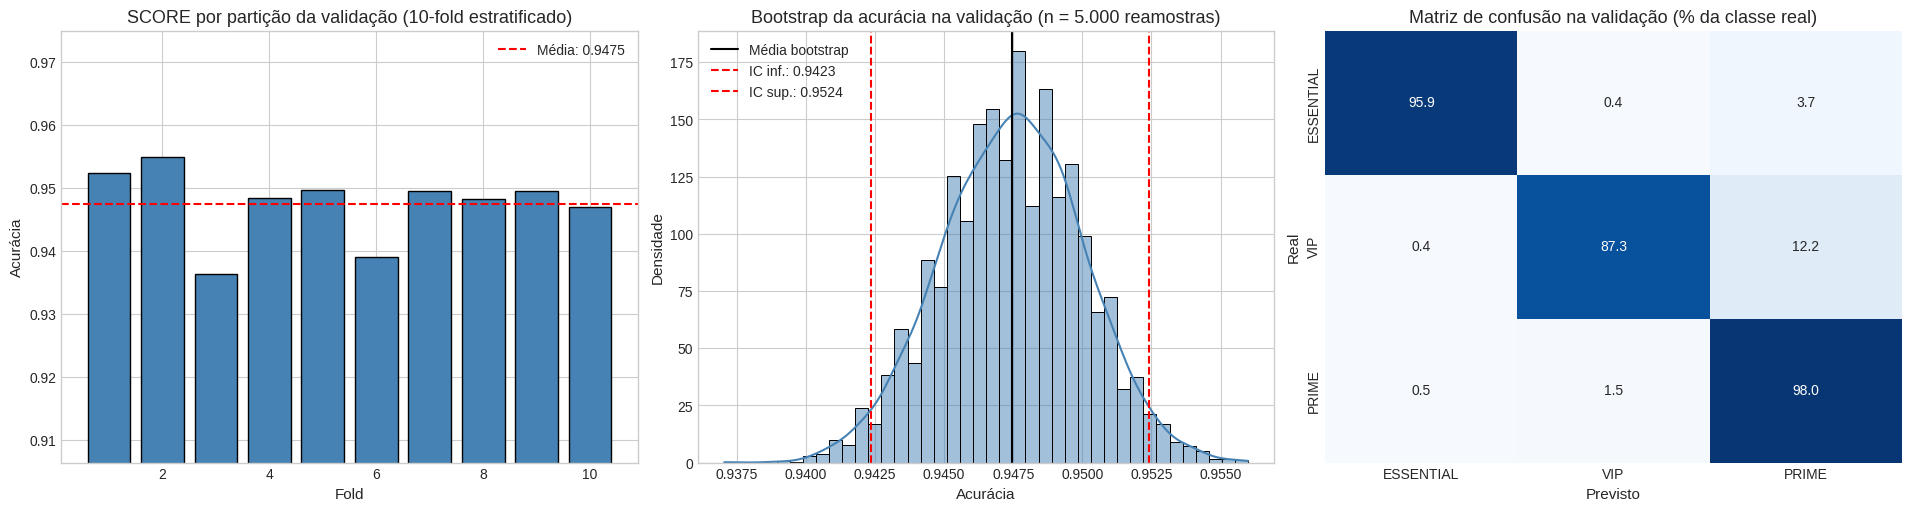

In [ ]:
# ==============================================================
# PARTE 2 | A3.3.2: Intervalo de confiança: Validation
# Validação Cruzada e Análise Bootstrapping (modelo escolhido: AdaBoost)
# Requer: classifiers (A3.3 | já treinado no TRAIN), Xa_val, ya_val, CLASSES
# (opcional) resumo_clf da A3.3.1, para comparar com o intervalo do Train
# O modelo NÃO é reajustado aqui; test continua reservado
# ==============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold

SEED = 42
K = 10
N_BOOT = 5000
NIVEL = 0.95
ALFA = 1 - NIVEL
MODELO_ESCOLHIDO = "AdaBoost"

modelo = classifiers[MODELO_ESCOLHIDO]          # ajustado no TRAIN na A3.3
y_pred = modelo.predict(Xa_val)
nc = len(CLASSES)
n = len(ya_val)
rng = np.random.default_rng(SEED)
NOMES = ["Acurácia (SCORE)", "F1 macro", "Acurácia balanceada"]

def conf(y, p):
    return np.bincount(y * nc + p, minlength=nc * nc).reshape(nc, nc)

def metricas_conf(C):
    diag = np.diag(C).astype(float)
    rec = diag / np.maximum(C.sum(axis=1), 1)
    prec = diag / np.maximum(C.sum(axis=0), 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0.0)
    return np.array([diag.sum() / C.sum(), f1.mean(), rec.mean()])

pontual = dict(zip(NOMES, metricas_conf(conf(ya_val, y_pred))))

# --------------------------------------------------------------
# 1. VALIDAÇÃO CRUZADA sobre o conjunto de validação
#    (K partições estratificadas pela classe; modelo fixo, sem reajuste)
# --------------------------------------------------------------
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
linhas = []
for k, (_, idx) in enumerate(skf.split(Xa_val, ya_val), start=1):
    linhas.append(dict(zip(["Fold"] + NOMES, (k, *metricas_conf(conf(ya_val[idx], y_pred[idx]))))))
cv = pd.DataFrame(linhas).set_index("Fold")
print(f"VALIDAÇÃO CRUZADA ({K} partições da validação, n = {n:,}) | {MODELO_ESCOLHIDO}".replace(",", "."))
display(cv.round(4))

# --------------------------------------------------------------
# 2. BOOTSTRAP das métricas na validação
# --------------------------------------------------------------
boot = np.empty((N_BOOT, 3))
for b in range(N_BOOT):
    i = rng.integers(0, n, n)
    boot[b] = metricas_conf(conf(ya_val[i], y_pred[i]))
boot = pd.DataFrame(boot, columns=NOMES)

# --------------------------------------------------------------
# 3. Intervalos de confiança (95%)
# --------------------------------------------------------------
t_crit = stats.t.ppf(1 - ALFA / 2, df=K - 1)
resumo_val_clf = {}
for nome in NOMES:
    media, dp = cv[nome].mean(), cv[nome].std(ddof=1)
    ep = dp / np.sqrt(K)
    resumo_val_clf[nome] = {
        "Valor na validação": pontual[nome],
        "CV média": media,
        "CV desvio (folds)": dp,
        "CV IC inferior": media - t_crit * ep,
        "CV IC superior": media + t_crit * ep,
        "Boot erro-padrão": boot[nome].std(ddof=1),
        "Boot IC inferior": boot[nome].quantile(ALFA / 2),
        "Boot IC superior": boot[nome].quantile(1 - ALFA / 2),
    }
print(f"\nINTERVALOS DE CONFIANÇA ({NIVEL:.0%}) | VALIDATION")
display(pd.DataFrame(resumo_val_clf).T.round(4))

# --------------------------------------------------------------
# 4. Bootstrap por CLASSE: recall (acerto dentro de cada tipo de conta)
# --------------------------------------------------------------
linhas = []
for c, nome_c in enumerate(CLASSES):
    m = ya_val == c
    yc, pc = ya_val[m], y_pred[m]
    nn = m.sum()
    b = np.array([(pc[i] == yc[i]).mean() for i in (rng.integers(0, nn, nn) for _ in range(N_BOOT))])
    prec = (ya_val[y_pred == c] == c).mean() if (y_pred == c).any() else np.nan
    linhas.append({"Classe": nome_c, "n": nn, "recall (acerto)": (pc == c).mean(),
                   "recall IC inf.": np.quantile(b, ALFA / 2), "recall IC sup.": np.quantile(b, 1 - ALFA / 2),
                   "precisão": prec})
print(f"\nBOOTSTRAP POR CLASSE (IC {NIVEL:.0%})")
display(pd.DataFrame(linhas).set_index("Classe").round(4))

# --------------------------------------------------------------
# 5. Consistência com o Train (se a A3.3.1 foi executada)
# --------------------------------------------------------------
if "resumo_clf" in globals():
    tr = resumo_clf["Acurácia (SCORE)"]
    v = resumo_val_clf["Acurácia (SCORE)"]
    sobrepoe = (v["Boot IC inferior"] <= tr["Boot IC superior"]) and (tr["Boot IC inferior"] <= v["Boot IC superior"])
    print("\nCONSISTÊNCIA TRAIN x VALIDATION (acurácia)")
    print(f"Train      IC {NIVEL:.0%}: [{tr['Boot IC inferior']:.4f}; {tr['Boot IC superior']:.4f}]")
    print(f"Validation IC {NIVEL:.0%}: [{v['Boot IC inferior']:.4f}; {v['Boot IC superior']:.4f}]")
    print("Os intervalos se sobrepõem: desempenho consistente." if sobrepoe
          else "Os intervalos NÃO se sobrepõem: investigar diferença entre treino e validação.")

# --------------------------------------------------------------
# 6. Gráficos
# --------------------------------------------------------------
C = confusion_matrix(ya_val, y_pred, labels=range(nc))
C_pct = C / C.sum(axis=1, keepdims=True) * 100
print("\nMATRIZ DE CONFUSÃO (% de cada classe real) | validação")
display(pd.DataFrame(C_pct, index=[f"real {c}" for c in CLASSES],
                     columns=[f"prev. {c}" for c in CLASSES]).round(1))

fig, ax = plt.subplots(1, 3, figsize=(19, 5), layout="constrained")
ax[0].bar(cv.index, cv[NOMES[0]], color="steelblue", edgecolor="black")
ax[0].axhline(cv[NOMES[0]].mean(), color="red", linestyle="--", label=f"Média: {cv[NOMES[0]].mean():.4f}")
ax[0].set_ylim(max(0, cv[NOMES[0]].min() - 0.03), min(1, cv[NOMES[0]].max() + 0.02))
ax[0].set_title(f"SCORE por partição da validação ({K}-fold estratificado)")
ax[0].set_xlabel("Fold"); ax[0].set_ylabel("Acurácia"); ax[0].legend()

r = resumo_val_clf[NOMES[0]]
sns.histplot(boot[NOMES[0]], bins=40, kde=True, stat="density", color="steelblue", ax=ax[1])
ax[1].axvline(boot[NOMES[0]].mean(), color="black", label="Média bootstrap")
ax[1].axvline(r["Boot IC inferior"], color="red", linestyle="--", label=f"IC inf.: {r['Boot IC inferior']:.4f}")
ax[1].axvline(r["Boot IC superior"], color="red", linestyle="--", label=f"IC sup.: {r['Boot IC superior']:.4f}")
ax[1].set_title(f"Bootstrap da acurácia na validação (n = {N_BOOT:,} reamostras)".replace(",", "."))
ax[1].set_xlabel("Acurácia"); ax[1].set_ylabel("Densidade"); ax[1].legend()

sns.heatmap(C_pct, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[2])
ax[2].set_title("Matriz de confusão na validação (% da classe real)"); ax[2].set_xlabel("Previsto"); ax[2].set_ylabel("Real")
plt.show()

##Atividade A3.4 (4º Passo): Medir a acurácia (score) dos Modelos de Classificação:

####Atividade A3.4.1: Medir a acurácia (score) - Matriz de Confusão: Conjunto TRAIN

MATRIZ DE CONFUSÃO | TRAIN | n = 35.210
(linhas = classe real; colunas = classe prevista)


,prev. ESSENTIAL,prev. VIP,prev. PRIME
real ESSENTIAL,13388,62,601
real VIP,26,6969,934
real PRIME,84,197,12949



MÉTRICAS POR CLASSE | TRAIN


,precisão,recall,F1,n (real)
ESSENTIAL,0.9919,0.9528,0.9719,14051.0
VIP,0.9642,0.8789,0.9196,7929.0
PRIME,0.8940,0.9788,0.9345,13230.0
média macro,0.9500,0.9368,0.9420,35210.0


SCORE (acurácia): 0.9459 | acurácia balanceada: 0.9368 | erros: 1.904 de 35.210
Maior confusão: VIP previsto como PRIME (11.8% dos VIP reais; 934 clientes)


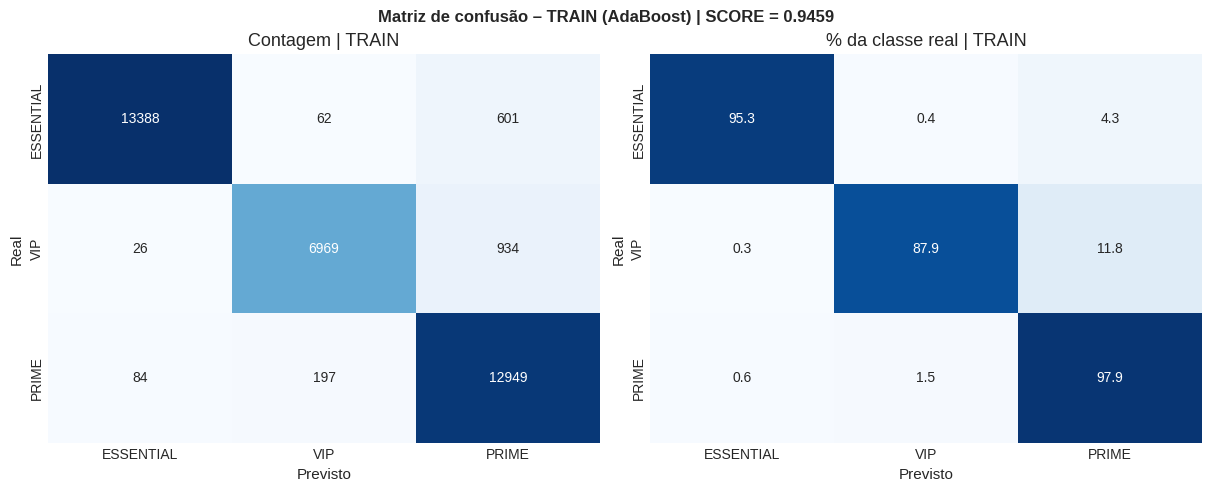

In [ ]:
# ==============================================================
# PARTE 2 | A3.4.1: Medir a acurácia (score) - Matriz de Confusão: Conjunto TRAIN
# Requer: classifiers (A3.3 | AdaBoost já treinado no TRAIN), Xa_train, ya_train, CLASSES
# Define `matriz_confusao`, reutilizada em validação e teste (A3.4.2 / A3.4.3)
# O modelo NÃO é reajustado aqui.
# ==============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             precision_recall_fscore_support)

MODELO_ESCOLHIDO = "AdaBoost"
modelo = classifiers[MODELO_ESCOLHIDO]
nc = len(CLASSES)

def matriz_confusao(y, pred, nome):
    C = confusion_matrix(y, pred, labels=range(nc))
    C_pct = C / C.sum(axis=1, keepdims=True) * 100
    prec, rec, f1, sup = precision_recall_fscore_support(y, pred, labels=range(nc), zero_division=0)
    acc = accuracy_score(y, pred)

    print(f"MATRIZ DE CONFUSÃO | {nome} | n = {len(y):,}".replace(",", "."))
    print("(linhas = classe real; colunas = classe prevista)")
    display(pd.DataFrame(C, index=[f"real {c}" for c in CLASSES],
                         columns=[f"prev. {c}" for c in CLASSES]))

    rel = pd.DataFrame({"precisão": prec, "recall": rec, "F1": f1, "n (real)": sup}, index=CLASSES)
    rel.loc["média macro"] = [prec.mean(), rec.mean(), f1.mean(), sup.sum()]
    print(f"\nMÉTRICAS POR CLASSE | {nome}")
    display(rel.round(4))
    print(f"SCORE (acurácia): {acc:.4f} | acurácia balanceada: {balanced_accuracy_score(y, pred):.4f} "
          f"| erros: {(y != pred).sum():,} de {len(y):,}".replace(",", "."))

    # maior confusão fora da diagonal
    fora = C.astype(float).copy(); np.fill_diagonal(fora, 0)
    i, j = np.unravel_index(fora.argmax(), fora.shape)
    print(f"Maior confusão: {CLASSES[i]} previsto como {CLASSES[j]} "
          f"({C_pct[i, j]:.1f}% dos {CLASSES[i]} reais; {C[i, j]:,} clientes)".replace(",", "."))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
    sns.heatmap(C, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
    ax[0].set_title(f"Contagem | {nome}"); ax[0].set_xlabel("Previsto"); ax[0].set_ylabel("Real")
    sns.heatmap(C_pct, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
    ax[1].set_title(f"% da classe real | {nome}"); ax[1].set_xlabel("Previsto"); ax[1].set_ylabel("Real")
    fig.suptitle(f"Matriz de confusão – {nome} ({MODELO_ESCOLHIDO}) | SCORE = {acc:.4f}", fontweight="bold")
    plt.show()
    return C, rel, acc

pred_train = modelo.predict(Xa_train)
cm_train, rel_train, acc_train = matriz_confusao(ya_train, pred_train, "TRAIN")

####Atividade A3.4.2: Medir a acurácia (score) - Matriz de Confusão: Conjunto VALIDATION

MATRIZ DE CONFUSÃO | VALIDATION | n = 7.545
(linhas = classe real; colunas = classe prevista)


,prev. ESSENTIAL,prev. VIP,prev. PRIME
real ESSENTIAL,2887,12,112
real VIP,7,1484,208
real PRIME,15,42,2778



MÉTRICAS POR CLASSE | VALIDATION


,precisão,recall,F1,n (real)
ESSENTIAL,0.9924,0.9588,0.9753,3011.0
VIP,0.9649,0.8735,0.9169,1699.0
PRIME,0.8967,0.9799,0.9365,2835.0
média macro,0.9513,0.9374,0.9429,7545.0


SCORE (acurácia): 0.9475 | acurácia balanceada: 0.9374 | erros: 396 de 7.545
Maior confusão: VIP previsto como PRIME (12.2% dos VIP reais; 208 clientes)


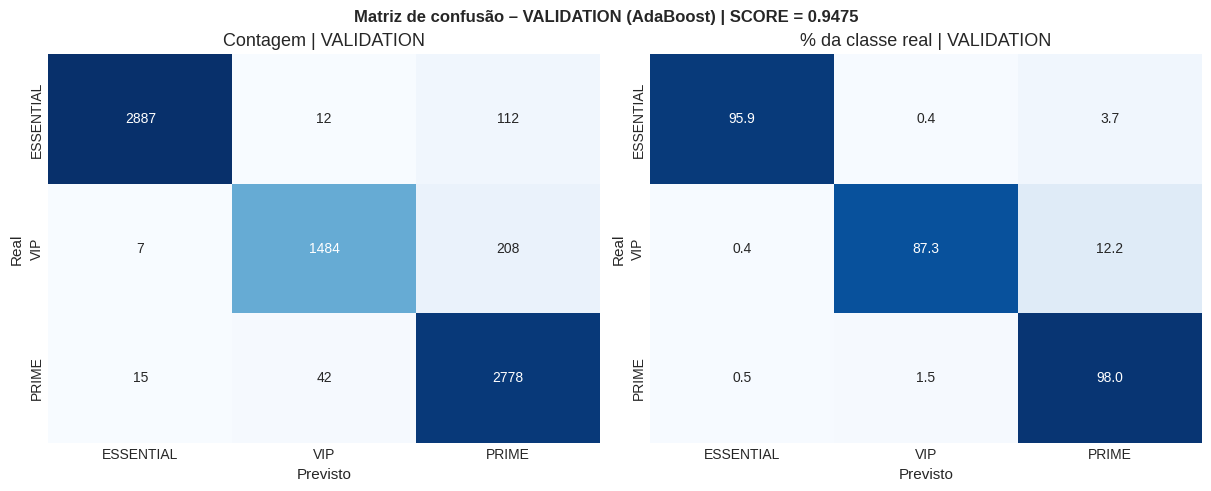


COMPARAÇÃO TREINO x VALIDAÇÃO


,recall treino,recall validação,F1 treino,F1 validação,Δ recall (val − treino)
ESSENTIAL,0.9528,0.9588,0.9719,0.9753,0.0060
VIP,0.8789,0.8735,0.9196,0.9169,-0.0055
PRIME,0.9788,0.9799,0.9345,0.9365,0.0011
média macro (recall = ac. balanceada),0.9368,0.9374,0.9420,0.9429,0.0006


SCORE treino = 0.9459 | SCORE validação = 0.9475 | diferença = -0.0016
Diferença pequena entre treino e validação: sem sinal de sobreajuste.


In [ ]:
# ==============================================================
# PARTE 2 | A3.4.2: Medir a acurácia (score) - Matriz de Confusão: Conjunto VALIDATION
# Requer: modelo, matriz_confusao, rel_train, acc_train (A3.4.1), Xa_val, ya_val, CLASSES
# O modelo NÃO é reajustado aqui.
# ==============================================================
import pandas as pd

pred_val = modelo.predict(Xa_val)
cm_val, rel_val, acc_val = matriz_confusao(ya_val, pred_val, "VALIDATION")

# Comparação com o treino
comp = pd.DataFrame({
    "recall treino": rel_train["recall"], "recall validação": rel_val["recall"],
    "F1 treino": rel_train["F1"], "F1 validação": rel_val["F1"]})
comp["Δ recall (val − treino)"] = comp["recall validação"] - comp["recall treino"]
comp = comp.rename(index={"média macro": "média macro (recall = ac. balanceada)"})
print("\nCOMPARAÇÃO TREINO x VALIDAÇÃO")
display(comp.round(4))
print(f"SCORE treino = {acc_train:.4f} | SCORE validação = {acc_val:.4f} | "
      f"diferença = {acc_train - acc_val:+.4f}")
if acc_train - acc_val > 0.03:
    print("Atenção: diferença acima de 3 p.p. entre treino e validação (possível sobreajuste).")
else:
    print("Diferença pequena entre treino e validação: sem sinal de sobreajuste.")

####Atividade A3.4.1: Medir a acurácia (score) - Matriz de Confusão: Conjunto TEST

MATRIZ DE CONFUSÃO | TEST | n = 7.545
(linhas = classe real; colunas = classe prevista)


,prev. ESSENTIAL,prev. VIP,prev. PRIME
real ESSENTIAL,2861,14,136
real VIP,6,1501,192
real PRIME,16,43,2776



MÉTRICAS POR CLASSE | TEST


,precisão,recall,F1,n (real)
ESSENTIAL,0.9924,0.9502,0.9708,3011.0
VIP,0.9634,0.8835,0.9217,1699.0
PRIME,0.8943,0.9792,0.9348,2835.0
média macro,0.9500,0.9376,0.9425,7545.0


SCORE (acurácia): 0.9461 | acurácia balanceada: 0.9376 | erros: 407 de 7.545
Maior confusão: VIP previsto como PRIME (11.3% dos VIP reais; 192 clientes)


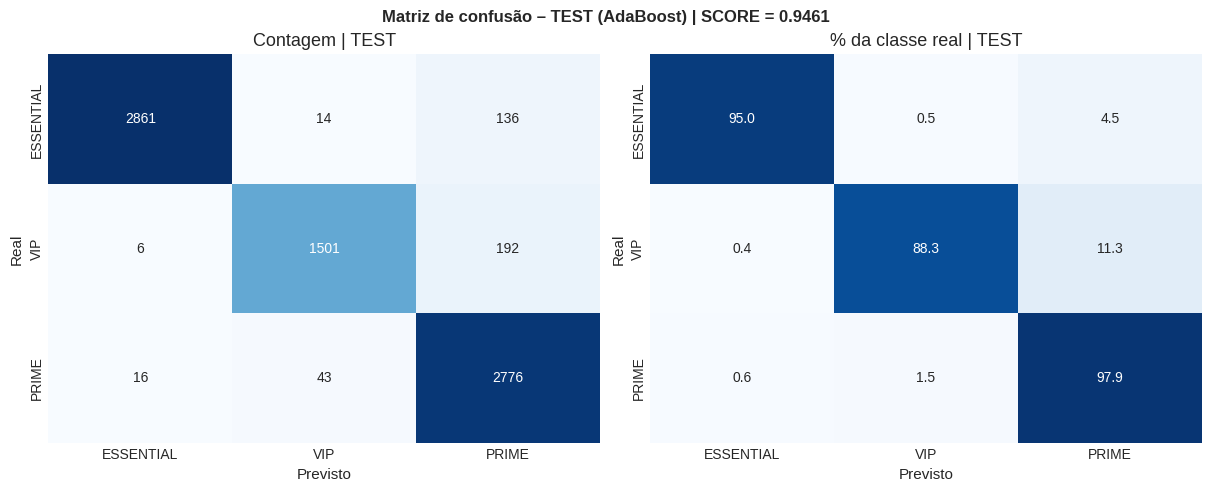


RECALL POR CLASSE | treino x validação x teste


,treino,validação,teste,Δ teste − treino
ESSENTIAL,0.9528,0.9588,0.9502,-0.0026
VIP,0.8789,0.8735,0.8835,0.0045
PRIME,0.9788,0.9799,0.9792,0.0004
média macro (= ac. balanceada),0.9368,0.9374,0.9376,0.0008



SCORE (acurácia):


,treino,validação,teste
SCORE (acurácia),0.9459,0.9475,0.9461


Diferença teste − treino: +0.0001 | teste − validação: -0.0015
Teste e validação praticamente iguais: o desempenho se mantém em dados novos.


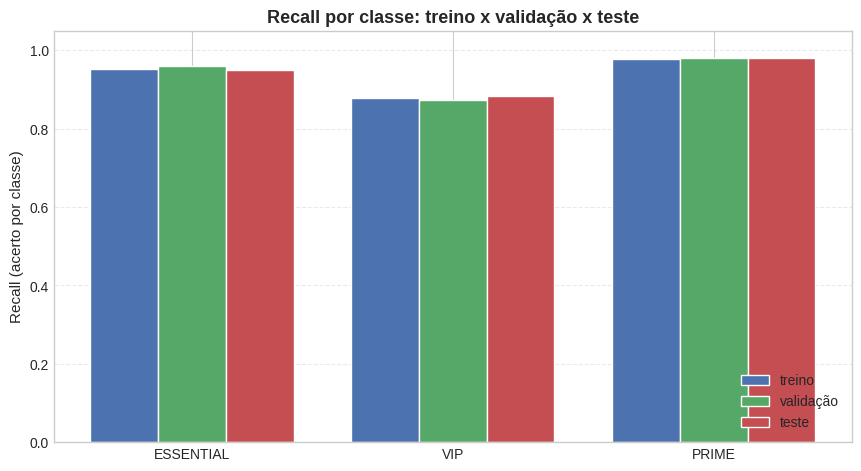

In [ ]:
# ==============================================================
# PARTE 2 | A3.4.3: Medir a acurácia (score) - Matriz de Confusão: Conjunto TEST
# (no notebook o título aparece como "A3.4.1", mas é a célula do TEST)
# Requer: modelo, matriz_confusao, rel_train/acc_train (A3.4.1), rel_val/acc_val (A3.4.2),
#         Xa_test, ya_test, CLASSES
# O modelo NÃO é reajustado aqui; o teste é usado uma única vez.
# ==============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pred_test = modelo.predict(Xa_test)
cm_test, rel_test, acc_test = matriz_confusao(ya_test, pred_test, "TEST")

# --------------------------------------------------------------
# Comparação entre os três conjuntos
# --------------------------------------------------------------
comp = pd.DataFrame({"treino": rel_train["recall"], "validação": rel_val["recall"], "teste": rel_test["recall"]})
comp["Δ teste − treino"] = comp["teste"] - comp["treino"]
comp = comp.rename(index={"média macro": "média macro (= ac. balanceada)"})
print("\nRECALL POR CLASSE | treino x validação x teste")
display(comp.round(4))

scores = pd.Series({"treino": acc_train, "validação": acc_val, "teste": acc_test}, name="SCORE (acurácia)")
print("\nSCORE (acurácia):")
display(scores.round(4).to_frame().T)
print(f"Diferença teste − treino: {acc_test - acc_train:+.4f} | teste − validação: {acc_test - acc_val:+.4f}")
if abs(acc_test - acc_val) <= 0.01:
    print("Teste e validação praticamente iguais: o desempenho se mantém em dados novos.")
else:
    print("Atenção: diferença acima de 1 p.p. entre teste e validação; investigar.")

# Gráfico: recall por classe nos três conjuntos
d = comp.drop(index="média macro (= ac. balanceada)")[["treino", "validação", "teste"]]
x = np.arange(len(d)); w = 0.26
fig, ax = plt.subplots(figsize=(8.5, 4.6), layout="constrained")
for i, (c, cor) in enumerate([("treino", "#4C72B0"), ("validação", "#55A868"), ("teste", "#C44E52")]):
    ax.bar(x + (i - 1) * w, d[c], w, label=c, color=cor, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_ylim(0, 1.05); ax.set_ylabel("Recall (acerto por classe)")
ax.set_title("Recall por classe: treino x validação x teste", fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4); ax.legend(loc="lower right")
plt.show()

##Atividade A3.5 (5º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

PARTE A | amostra aleatória simples: 50.300 registros


,população (base completa),amostra aleatória,amostra Neyman (train+val+test)
TIPO DA CONTA,,,
ESSENTIAL,61.00,62.06,39.91
PRIME,16.38,15.43,37.57
VIP,22.62,22.51,22.52


MATRIZ DE CONFUSÃO | POPULAÇÃO (amostra aleatória) | n = 50.300
(linhas = classe real; colunas = classe prevista)


,prev. ESSENTIAL,prev. VIP,prev. PRIME
real ESSENTIAL,29771,131,1315
real VIP,56,9855,1412
real PRIME,42,122,7596



MÉTRICAS POR CLASSE | POPULAÇÃO (amostra aleatória)


,precisão,recall,F1,n (real)
ESSENTIAL,0.9967,0.9537,0.9747,31217.0
VIP,0.9750,0.8704,0.9197,11323.0
PRIME,0.7358,0.9789,0.8401,7760.0
média macro,0.9025,0.9343,0.9115,50300.0


SCORE (acurácia): 0.9388 | acurácia balanceada: 0.9343 | erros: 3.078 de 50.300
Maior confusão: VIP previsto como PRIME (12.5% dos VIP reais; 1.412 clientes)


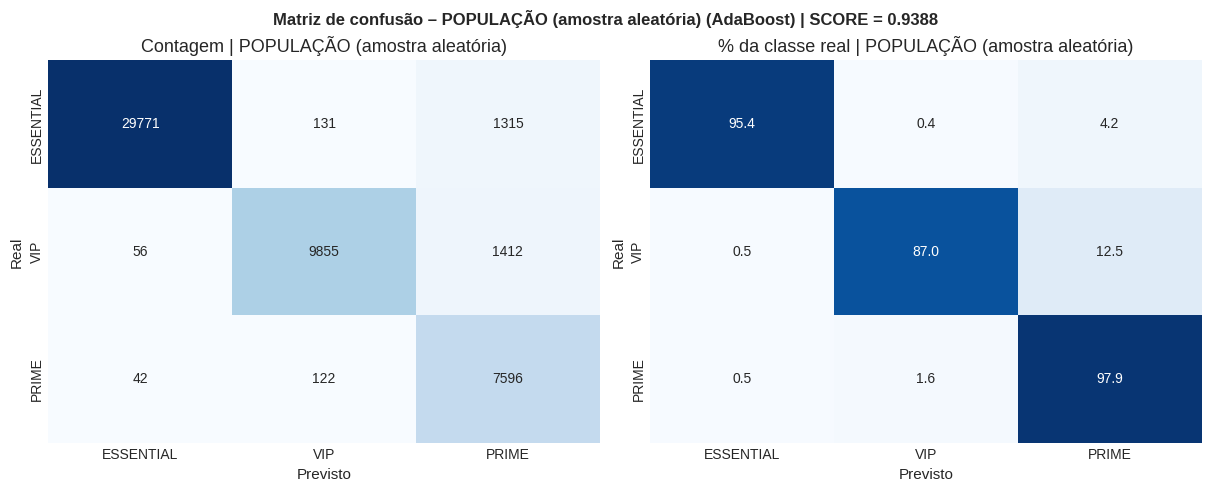

IC 95% (bootstrap) da acurácia na população: [0.9367; 0.9410]

REPONDERAÇÃO: o recall por classe do teste, com os pesos reais da base


,peso real da classe (%),recall no teste,recall na população
ESSENTIAL,61.0021,0.9502,0.9537
VIP,22.6168,0.8835,0.8704
PRIME,16.3812,0.9792,0.9789


Acurácia no teste (composição Neyman): 0.9461
Acurácia esperada na base real (teste reponderado): 0.9398
Acurácia observada na população:                   0.9388 (diferença: -0.0010)

PARTE B | amostra estratificada (composição do teste): 50.300 registros
MATRIZ DE CONFUSÃO | POPULAÇÃO (estratificada) | n = 50.300
(linhas = classe real; colunas = classe prevista)


,prev. ESSENTIAL,prev. VIP,prev. PRIME
real ESSENTIAL,19108,84,881
real VIP,41,9927,1359
real PRIME,91,268,18541



MÉTRICAS POR CLASSE | POPULAÇÃO (estratificada)


,precisão,recall,F1,n (real)
ESSENTIAL,0.9931,0.9519,0.9721,20073.0
VIP,0.9658,0.8764,0.9189,11327.0
PRIME,0.8922,0.9810,0.9345,18900.0
média macro,0.9504,0.9364,0.9418,50300.0


SCORE (acurácia): 0.9458 | acurácia balanceada: 0.9364 | erros: 2.724 de 50.300
Maior confusão: VIP previsto como PRIME (12.0% dos VIP reais; 1.359 clientes)


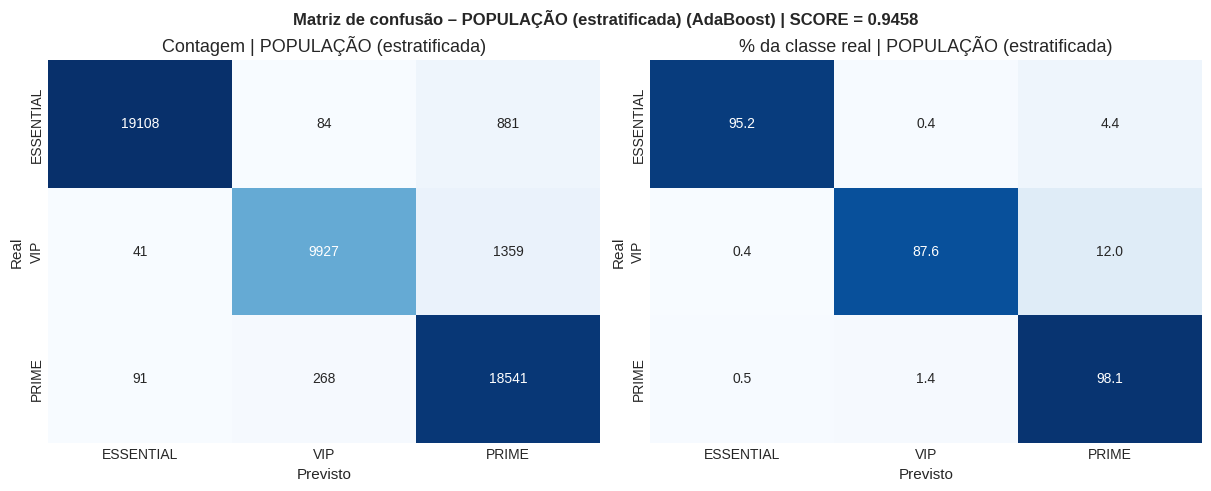

IC 95% (bootstrap) da acurácia: [0.9439; 0.9477]

RESUMO | todos os conjuntos


,acurácia,acurácia balanceada,F1 macro
treino,0.9459,0.9368,0.9420
validação,0.9475,0.9374,0.9429
teste,0.9461,0.9376,0.9425
população estratificada (B),0.9458,0.9364,0.9418
população aleatória (A),0.9388,0.9343,0.9115


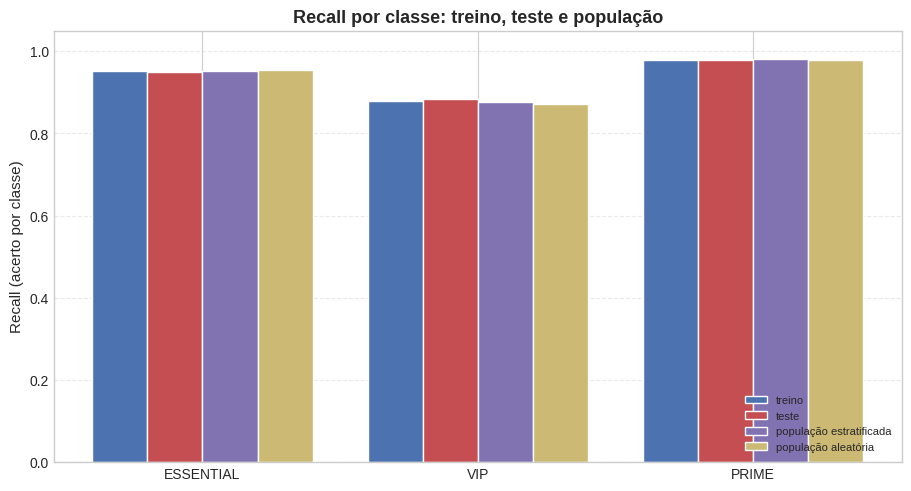

In [ ]:
# ==============================================================
# PARTE 2 | A3.5 (5º Passo): Testar o Modelo: Dados da População
#           amostra aleatória (Sample)
# Requer: table39, amostra_ideal (Load dos Datasets), preparar_clf, colunas_Xa (A3.1),
#         MAPA_CONTA (A1.1), modelo, matriz_confusao, rel_test, acc_test (A3.4)
# O modelo (AdaBoost, ajustado no TRAIN) NÃO é reajustado aqui.
# Parte A: amostra aleatória SIMPLES (proporções reais da base)
# Parte B: amostra estratificada com a MESMA composição do teste (comparável ao teste)
# ==============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED_A, SEED_B = 2026, 2027
N_POP = 50300
N_BOOT = 2000
ESTRATO = "TIPO DA CONTA"
nc = len(CLASSES)

def conf(y, p):
    return np.bincount(y * nc + p, minlength=nc * nc).reshape(nc, nc)

def avaliar(df, nome):
    X = preparar_clf(df)
    assert list(X.columns) == list(colunas_Xa), "Colunas diferentes das do treino."
    X = X.to_numpy(dtype=np.float64)
    y = df[ESTRATO].map(MAPA_CONTA).to_numpy()
    assert not pd.isna(y).any()
    y = y.astype(int)
    pred = modelo.predict(X)
    return y, pred

def ic_acuracia(y, pred, seed):
    rng = np.random.default_rng(seed)
    acc = np.empty(N_BOOT)
    for b in range(N_BOOT):
        i = rng.integers(0, len(y), len(y))
        acc[b] = (y[i] == pred[i]).mean()
    return np.quantile(acc, [0.025, 0.975])

# --------------------------------------------------------------
# PARTE A: amostra aleatória simples da população
# --------------------------------------------------------------
populacao_disponivel = table39.drop(index=amostra_ideal.index)
amostra_pop_c = populacao_disponivel.sample(n=N_POP, random_state=SEED_A)
print(f"PARTE A | amostra aleatória simples: {N_POP:,} registros".replace(",", "."))
display((pd.DataFrame({"população (base completa)": table39[ESTRATO].value_counts(normalize=True),
                       "amostra aleatória": amostra_pop_c[ESTRATO].value_counts(normalize=True),
                       "amostra Neyman (train+val+test)": amostra_ideal[ESTRATO].value_counts(normalize=True)})
         * 100).round(2))

y_pa, pred_pa = avaliar(amostra_pop_c, "população")
cm_pa, rel_pa, acc_pa = matriz_confusao(y_pa, pred_pa, "POPULAÇÃO (amostra aleatória)")
lo, hi = ic_acuracia(y_pa, pred_pa, SEED_A)
print(f"IC 95% (bootstrap) da acurácia na população: [{lo:.4f}; {hi:.4f}]")

# --------------------------------------------------------------
# Por que a acurácia pode mudar? Reponderação pelos pesos reais das classes
# acurácia esperada = soma( peso real da classe x recall da classe no TESTE )
# --------------------------------------------------------------
pesos = table39[ESTRATO].value_counts(normalize=True).rename(index=MAPA_CONTA).reindex(range(nc)).to_numpy()
recall_test = rel_test["recall"].iloc[:nc].to_numpy()
acc_esperada = float((pesos * recall_test).sum())
print("\nREPONDERAÇÃO: o recall por classe do teste, com os pesos reais da base")
display(pd.DataFrame({"peso real da classe (%)": pesos * 100,
                      "recall no teste": recall_test,
                      "recall na população": rel_pa["recall"].iloc[:nc].to_numpy()}, index=CLASSES).round(4))
print(f"Acurácia no teste (composição Neyman): {acc_test:.4f}")
print(f"Acurácia esperada na base real (teste reponderado): {acc_esperada:.4f}")
print(f"Acurácia observada na população:                   {acc_pa:.4f} "
      f"(diferença: {acc_pa - acc_esperada:+.4f})")

# --------------------------------------------------------------
# PARTE B: população com a mesma composição do teste (sem reutilizar registros)
# --------------------------------------------------------------
contagens = amostra_ideal[ESTRATO].value_counts()
pool = table39.drop(index=amostra_ideal.index).drop(index=amostra_pop_c.index)
assert all(pool[ESTRATO].value_counts().get(t, 0) >= n for t, n in contagens.items()), \
    "Registros insuficientes em algum tipo de conta."
amostra_pop_e = pd.concat([pool[pool[ESTRATO] == t].sample(n=int(n), random_state=SEED_B)
                           for t, n in contagens.items()])
print(f"\nPARTE B | amostra estratificada (composição do teste): {len(amostra_pop_e):,} registros".replace(",", "."))
y_pb, pred_pb = avaliar(amostra_pop_e, "população estratificada")
cm_pb, rel_pb, acc_pb = matriz_confusao(y_pb, pred_pb, "POPULAÇÃO (estratificada)")
lo_b, hi_b = ic_acuracia(y_pb, pred_pb, SEED_B)
print(f"IC 95% (bootstrap) da acurácia: [{lo_b:.4f}; {hi_b:.4f}]")

# --------------------------------------------------------------
# Resumo comparativo
# --------------------------------------------------------------
resumo_pop = pd.DataFrame({
    "acurácia": [acc_train, acc_val, acc_test, acc_pb, acc_pa],
    "acurácia balanceada": [rel_train["recall"].iloc[-1], rel_val["recall"].iloc[-1], rel_test["recall"].iloc[-1],
                            rel_pb["recall"].iloc[-1], rel_pa["recall"].iloc[-1]],
    "F1 macro": [rel_train["F1"].iloc[-1], rel_val["F1"].iloc[-1], rel_test["F1"].iloc[-1],
                 rel_pb["F1"].iloc[-1], rel_pa["F1"].iloc[-1]],
}, index=["treino", "validação", "teste", "população estratificada (B)", "população aleatória (A)"])
print("\nRESUMO | todos os conjuntos")
display(resumo_pop.round(4))

d = pd.DataFrame({"treino": rel_train["recall"].iloc[:nc].to_numpy(), "teste": rel_test["recall"].iloc[:nc].to_numpy(),
                  "população estratificada": rel_pb["recall"].iloc[:nc].to_numpy(),
                  "população aleatória": rel_pa["recall"].iloc[:nc].to_numpy()}, index=CLASSES)
x = np.arange(nc); w = 0.2
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
for i, (c, cor) in enumerate(zip(d.columns, ["#4C72B0", "#C44E52", "#8172B2", "#CCB974"])):
    ax.bar(x + (i - 1.5) * w, d[c], w, label=c, color=cor, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels(CLASSES); ax.set_ylim(0, 1.05); ax.set_ylabel("Recall (acerto por classe)")
ax.set_title("Recall por classe: treino, teste e população", fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4); ax.legend(loc="lower right", fontsize=8)
plt.show()

## RELATÓRIO PARCIAL - MODELO DE CLASSIFICAÇÃO

Fazer aqui o **RELATÓRIO PARCIAL - MODELO DE CLASSIFICAÇÃO** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

Objetivo. Identificar o tipo de conta do cliente (ESSENTIAL, VIP ou PRIME) a partir de suas características e de seu histórico de compra, para que a empresa reconheça o perfil de cada cliente sem depender do cadastro.

Como foi feito. Comparamos 10 técnicas de classificação, todas ajustadas em 35.210 clientes (treino) e avaliadas em outros 7.545 (validação), usando como medida principal a acurácia, que é a porcentagem de clientes classificados corretamente. Como as classes não têm o mesmo tamanho, usamos também o F1 macro e a acurácia balanceada, que dão o mesmo peso aos três tipos de conta. O tipo da conta foi retirado das variáveis de entrada para não entregar a resposta ao modelo.

Modelo escolhido. O melhor resultado foi do AdaBoost, com acurácia de 94,7% na validação, contra 39,9% de um modelo que sempre responde a classe mais frequente. Decision Tree, Random Forest e Neural Net ficaram a menos de 1 ponto percentual do primeiro, ou seja, muito próximos. O AdaBoost foi escolhido por ter a maior acurácia e o maior F1 macro (0,943), sem sinais de sobreajuste: a acurácia no treino (94,6%) é praticamente igual à da validação.

Resultado em dados novos. No conjunto de teste, que o modelo não viu durante o ajuste, a acurácia foi de 94,6%, com acurácia balanceada de 93,8%, valores praticamente iguais aos da validação. O modelo acerta 95,0% dos clientes ESSENTIAL, 88,3% dos VIP e 97,9% dos PRIME. O erro mais frequente é classificar clientes VIP como PRIME (11,3% dos VIP), o que indica que esses dois tipos de conta têm perfis parecidos.

Teste na base real. Aplicamos o modelo a uma amostra aleatória de 50.300 clientes da base, e a acurácia foi de 93,9%, com intervalo de confiança de 95% de 93,7% a 94,1%. Ela é um pouco menor que a do teste porque a base real tem mais clientes ESSENTIAL (61%) e menos PRIME (16%) do que a amostra de treino. Ao ajustar o desempenho do teste a essa composição, a acurácia esperada é de 94,0%, praticamente igual à observada. Em uma amostra com a mesma composição do teste, a acurácia foi de 94,6%, igual à do teste, o que confirma que o modelo se mantém em dados novos.

Limitações e próximos passos. O modelo tem mais dificuldade com os clientes VIP, que são às vezes confundidos com PRIME (cerca de 12% dos VIP na base real). Além disso, a precisão de cada tipo muda conforme a mistura de clientes: na base real, onde há menos PRIME, a precisão dessa classe cai de 89% para 74%, ou seja, cerca de um quarto dos clientes classificados como PRIME são na verdade VIP ou ESSENTIAL. Recomenda-se acompanhar o desempenho por tipo de conta, e não só a acurácia geral, e usar o modelo como apoio à decisão, não como substituto do cadastro.

# RELATÓRIO FINAL - VISÃO HOLÍSTICA SOBRE O PROJETO

Fazer aqui o **RELATÓRIO FINAL** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.



## 1. Introdução

O UWine é o clube de vinhos da UVV. Este projeto trabalha com a tabela de notas fiscais do clube, uma base simulada com **1.120.000 registros** e 23 colunas, que descrevem o perfil do cliente (renda, sexo, estado civil, região e opinião sobre o serviço), o tipo de conta (ESSENTIAL, VIP ou PRIME), as características dos vinhos comprados e o valor total de cada nota.

A pergunta que orienta o trabalho é: **o que os dados dizem sobre os clientes do clube e o quanto eles permitem prever?** Para responder, aplicamos três técnicas de ciência de dados sobre a mesma base: regressão, clusterização e classificação.

## 2. Objetivo

O objetivo geral é transformar os dados do clube em informação útil para os gestores. Ele se divide em três objetivos específicos:

- **Regressão:** prever o valor total de uma nota fiscal a partir do perfil do cliente.
- **Clusterização:** descobrir grupos naturais de clientes, sem dizer ao modelo quais grupos esperar.
- **Classificação:** identificar o tipo de conta (ESSENTIAL, VIP ou PRIME) de um cliente a partir de suas características e de seu histórico de compra.

Em cada etapa, o critério de sucesso foi o mesmo: o modelo precisa funcionar em clientes que ele não viu durante o ajuste, e não apenas nos dados usados para treiná-lo.

## 3. Metodologia

**Amostra.** Analisar 1,12 milhão de registros em todos os modelos seria lento e desnecessário. Retiramos uma amostra de **50.300 notas** com alocação de Neyman, método que sorteia mais clientes nos grupos mais variáveis: 20.073 ESSENTIAL, 18.900 PRIME e 11.327 VIP. Por isso a amostra tem mais clientes PRIME (38%) do que a base real (16%), fato que influencia a leitura dos resultados.

**Divisão dos dados.** A amostra foi dividida de forma proporcional entre os tipos de conta: **70% para treino** (35.210 notas), **15% para validação** (7.545) e **15% para teste** (7.545). O treino ajusta o modelo, a validação serve para escolher entre modelos e o teste mede o desempenho final, sendo usado uma única vez.

**Preparação das variáveis.** Os números foram padronizados (para que renda e idade fiquem na mesma escala), o sexo virou uma variável de 0 ou 1, o tipo de conta virou uma escala ordenada (ESSENTIAL, VIP, PRIME), região e estado civil foram transformados em colunas de sim ou não, e a opinião do cliente virou uma nota de satisfação de 1 a 5. Todos os parâmetros dessas transformações foram calculados **apenas no treino**, para que nenhuma informação de validação ou teste vazasse para o modelo.

**Verificação com a população.** Depois do teste, cada modelo foi aplicado a uma **amostra aleatória de 50.300 notas da base completa**, sem repetir registros já usados. Como essa amostra mantém as proporções reais dos tipos de conta, ela mostra o desempenho que a empresa teria na prática. Também fizemos uma versão com a mesma composição da amostra de treino, para isolar o efeito da mistura de clientes.

**Os três modelos.**

| Tarefa | Como foi escolhido o modelo | Modelo final |
|---|---|---|
| Regressão (valor da nota) | Comparação de 9 modelos na validação | Lasso, um modelo linear simples |
| Clusterização (grupos de clientes) | Método do cotovelo e silhueta para escolher o número de grupos | K-Means com 4 grupos |
| Classificação (tipo de conta) | Comparação de 10 técnicas na validação | AdaBoost |

Para estimar a confiança nos resultados, usamos validação cruzada e bootstrap, que repetem a avaliação em muitas reamostragens dos dados e mostram o quanto o resultado varia.

## 4. Análise dos dados e resultados

### 4.1 Regressão: prever o valor da nota

O Lasso explica cerca de **70,5%** da variação do valor das notas no treino e na validação e **71,0%** no teste. Os valores praticamente iguais mostram que ele funciona do mesmo jeito em dados novos. Modelos mais complexos não trouxeram ganho: o Random Forest, por exemplo, teve 79,5% no treino, mas só 70,9% no teste, sinal de que decorou os dados.

Na amostra aleatória da base real, o modelo explica **74,1%** da variação (intervalo de confiança de 95%: 73,6% a 74,6%), com erro médio de **269 reais** por nota e erro típico (RMSE) de **417 reais**. Esse erro é menor que o do teste (584 reais) porque o teste tinha mais clientes PRIME, que são os mais difíceis de prever.

O **fator que mais influencia o valor da nota é a renda do cliente**. As características dos vinhos e a nota de satisfação praticamente não alteram a previsão. O modelo não erra para mais nem para menos na média, mas o erro cresce junto com o valor da compra:

| Tipo de conta | Erro típico (reais) | Variação explicada |
|---|---|---|
| ESSENTIAL | 181 | 62% |
| VIP | 375 | 33% |
| PRIME | 888 | 30% |

Cerca de 26% da variação do valor das notas não é explicada pelas informações disponíveis.

### 4.2 Clusterização: grupos de clientes

Para o K-Means, usamos as variáveis de perfil e de compra e retiramos as medidas físico-químicas dos vinhos, que atrapalhavam a separação dos grupos: com elas, a qualidade da separação (silhueta) era de 0,13, e sem elas subiu para 0,36. O tipo de conta também ficou de fora, para que ele servisse depois como teste independente. O método do cotovelo indicou **4 grupos**. A silhueta apontou 2 grupos como melhor valor (0,339), mas a diferença para 4 grupos (0,296) é pequena, e dois grupos seriam pouco úteis para a empresa.

A qualidade da separação foi de **0,296 no treino, 0,297 na validação, 0,305 no teste e 0,325 na base real**, valores razoáveis e estáveis. A distribuição dos clientes entre os grupos praticamente não muda do treino para a validação e o teste (diferença máxima de 0,4 ponto percentual).

O resultado mais relevante é que o modelo **separa os clientes PRIME dos demais, mesmo sem saber o tipo de conta**:

| Grupo | Treino | Base real | Composição |
|---|---|---|---|
| 0 | 51,7% | 67,4% | ESSENTIAL e VIP (cerca de 61% e 33%) |
| 1 | 14,9% | 17,7% | ESSENTIAL e VIP, com um pouco mais de PRIME |
| 2 | 25,5% | 11,7% | Quase só PRIME (cerca de 94%) |
| 3 | 7,9% | 3,2% | 100% PRIME |

Os grupos 2 e 3 reúnem cerca de **15% da base real**. As proporções na base real são diferentes das do treino porque a amostra de treino tem mais clientes PRIME. Ao corrigir esse peso, a diferença cai para cerca de 1 ponto percentual, e em uma amostra com a mesma composição do teste as proporções ficam praticamente iguais. Isso confirma que a diferença vem da composição da amostra, e não de instabilidade do modelo.

### 4.3 Classificação: identificar o tipo de conta

Comparamos 10 técnicas. O **AdaBoost** teve o melhor desempenho, com **94,7%** de acerto na validação, contra 39,9% de um modelo que sempre responde a classe mais frequente. Decision Tree, Random Forest e Neural Net ficaram a menos de 1 ponto percentual dele. O AdaBoost foi escolhido por ter a maior acurácia e o maior F1 macro (0,943), sem sinais de sobreajuste: a acurácia no treino (94,6%) é igual à da validação.

| Conjunto | Acurácia | Acurácia balanceada |
|---|---|---|
| Treino | 94,6% | 93,7% |
| Validação | 94,7% | 93,7% |
| Teste | 94,6% | 93,8% |
| Base real (amostra aleatória) | 93,9% | 93,4% |
| Amostra com a composição do teste | 94,6% | 93,6% |

O modelo acerta **95% dos clientes ESSENTIAL, 88% dos VIP e 98% dos PRIME**. O erro mais comum é classificar clientes **VIP como PRIME** (11% no teste e 12% na base real). Na base real a acurácia é 0,7 ponto percentual menor que no teste, e a reponderação do teste pelos pesos reais da base prevê 94,0%, a 0,1 ponto da observada. Já a precisão do PRIME cai de 89% para 74%, porque há menos clientes PRIME na base e os erros vindos dos outros tipos pesam mais.

### 4.4 Visão integrada

As três análises contam a mesma história por caminhos diferentes:

- **O perfil PRIME é o mais distinto.** A clusterização o isola sozinha, a classificação o acerta em 98% dos casos e, na regressão, ele é o mais difícil de prever, com valores de compra altos e variáveis.
- **ESSENTIAL e VIP têm perfis parecidos.** A clusterização os mistura, e na classificação o VIP é a classe de menor acerto, confundida com o PRIME.
- **A renda é o principal fator** do valor da compra, enquanto as características dos vinhos não ajudaram em nenhum dos três modelos.
- **A composição da amostra importa.** Em todas as etapas, a diferença entre o teste e a base real veio da mistura de tipos de conta, e não do modelo, o que foi comprovado reponderando os resultados.

## 5. Conclusão

Os três modelos funcionam em clientes que não participaram do ajuste e se mantêm na base real, com desempenho estável entre treino, validação, teste e população.

- **A regressão** (Lasso) é confiável para estimar o valor médio das notas, principalmente nos clientes ESSENTIAL, mas a previsão individual é pouco precisa para VIP e PRIME.
- **A clusterização** (K-Means, 4 grupos) revela uma estrutura moderada, em que cerca de 15% da base forma um segmento de clientes PRIME bem definido.
- **A classificação** (AdaBoost) identifica o tipo de conta com cerca de 94% de acerto, com maior dificuldade em separar os clientes VIP dos PRIME.

**Limitações.** A separação dos grupos na clusterização é moderada, com alguma sobreposição, então os perfis devem ser lidos como tendências, e não como categorias rígidas. A base é simulada, e os resultados devem ser confirmados com dados reais antes de decisões de negócio. A precisão de cada tipo de conta muda com a mistura de clientes, por isso o desempenho deve ser acompanhado por tipo de conta, e não só pela acurácia geral.

**Recomendações.** (1) Usar o grupo PRIME identificado na clusterização como público de ações específicas do clube. (2) Usar o classificador como apoio à decisão, revisando os casos VIP e PRIME mais próximos da fronteira. (3) Coletar novas variáveis que expliquem melhor o gasto dos clientes VIP e PRIME, já que as informações atuais deixam cerca de 26% da variação sem explicação. (4) Retreinar e reavaliar os modelos periodicamente, à medida que a base cresça.

In [ ]:
!jupyter nbconvert --to html /content/Lucas_Barbosa_WORKFLOW_PARTE_1.ipynb